# ANALISIS DATA MINING

## Analisis Tren dan Prediksi Potensi Permintaan 10 Sparepart Apple Device Berdasarkan Data Transaksi Servis
## 10 Sparepart Apple Device

Metode:
Logistic Regression

Bahasa Pemrograman:
Python

## Tujuan Penelitian

1. Mengidentifikasi 10 sparepart Apple Device
   dengan frekuensi kemunculan tertinggi.

2. Menganalisis tren kemunculan sparepart
   berdasarkan periode bulanan.

3. Membangun model Logistic Regression untuk
   memprediksi potensi kemunculan sparepart
   dalam transaksi pada periode berikutnya.

4. Mengevaluasi hasil prediksi menggunakan
   metrik evaluasi klasifikasi.
       

# BAGIAN B — BUSINESS UNDERSTANDING DAN DATA UNDERSTANDING

## 1. Import Library

Tahap ini dilakukan untuk memanggil library Python
yang akan digunakan dalam proses pengolahan data,
analisis, visualisasi, pemodelan, dan evaluasi.

In [1]:
# IMPORT LIBRARY

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    balanced_accuracy_score
)

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

print("Library berhasil dipanggil!")


Library berhasil dipanggil!


In [83]:
# 2. MENENTUKAN LOKASI DATA

from pathlib import Path
import os

DATASET_NAME = "Data_Mentah_PT_X.xlsx"
CURRENT_DIR = Path.cwd().resolve()

# Cari dataset pada struktur folder project yang umum digunakan.
KANDIDAT_DATA = [
    CURRENT_DIR / "data" / "raw" / DATASET_NAME,
    CURRENT_DIR / DATASET_NAME,
    CURRENT_DIR / "Project_Final" / "data" / "raw" / DATASET_NAME,
]

DATA_FILE = next((p for p in KANDIDAT_DATA if p.is_file()), None)

# Jika belum ditemukan, cari di dalam folder kerja Jupyter.
if DATA_FILE is None:
    hasil_pencarian = list(CURRENT_DIR.rglob(DATASET_NAME))
    if hasil_pencarian:
        DATA_FILE = hasil_pencarian[0]

if DATA_FILE is None:
    raise FileNotFoundError(
        "File data belum ditemukan. Pastikan file "
        f"'{DATASET_NAME}' berada di folder 'data/raw' dalam folder project. "
        f"Folder kerja Jupyter saat ini: {CURRENT_DIR}"
    )

DATA_FILE = DATA_FILE.resolve()

# Tentukan folder utama project berdasarkan letak dataset.
if DATA_FILE.parent.name.lower() == "raw" and DATA_FILE.parent.parent.name.lower() == "data":
    BASE_DIR = DATA_FILE.parent.parent.parent
else:
    BASE_DIR = DATA_FILE.parent

# Pastikan semua file hasil disimpan di dalam folder project.
os.chdir(BASE_DIR)

OUTPUT_DIR = BASE_DIR / "hasil"
GRAFIK_DIR = BASE_DIR / "grafik"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
GRAFIK_DIR.mkdir(parents=True, exist_ok=True)

print("Lokasi proyek:", BASE_DIR)
print("Lokasi dataset:", DATA_FILE)
print("File ditemukan:", DATA_FILE.is_file())


Lokasi proyek: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final
Lokasi dataset: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\data\raw\Data_Mentah_PT_X.xlsx
File ditemukan: True


In [3]:
# 3. MEMBACA DATASET

df_raw = pd.read_excel(
    DATA_FILE,
    sheet_name="Transaksi_12_Bulan"
)

print("Dataset berhasil dibaca!")

display(df_raw.head(10))
print("Jumlah baris:", df_raw.shape[0])
print("Jumlah kolom:", df_raw.shape[1])

print("\nNama kolom:")
print(df_raw.columns.tolist())

print("\nInformasi tipe data:")
df_raw.info()

Dataset berhasil dibaca!


,Sumber_File,Sheet_Asal,Baris_Asal,Tanggal_Asli,Tanggal_Diperbaiki,Name,Device,Damage Type,Technician,Description,Status,Payment Date,Amount,Status_Perbaikan,Periode
0,Sumber_01.xlsx,AGUSTUS,2,2025-08-01,2025-08-01,P0001,iPhone 12 Pro Max,Etc,T001,Cleaning kena air,Paid,2025-08-01 00:00:00,350000.0,Tidak diubah,2025-08
1,Sumber_01.xlsx,AGUSTUS,3,2025-08-01,2025-08-01,P0002,iPhone 12 Pro,Interface,T001,Baterai Oem,Paid,2025-08-01 00:00:00,640000.0,Tidak diubah,2025-08
2,Sumber_01.xlsx,AGUSTUS,4,2025-08-02,2025-08-02,P0003,iPhone X,Interface,T001,Mati Total > Baterai Ori + Ag Black Biasa,Paid,2025-08-02 00:00:00,470000.0,Tidak diubah,2025-08
3,Sumber_01.xlsx,AGUSTUS,5,2025-08-02,2025-08-02,P0004,iPhone 11 Pro,Interface,T001,Kamera Belakang,Paid,2025-08-02 00:00:00,1000000.0,Tidak diubah,2025-08
4,Sumber_01.xlsx,AGUSTUS,6,2025-08-03,2025-08-03,P0005,iPhone XR,Machine + Interface,T002,Mati Total + Baterai Ori,Paid,2025-08-15 00:00:00,1390000.0,Tidak diubah,2025-08
5,Sumber_01.xlsx,AGUSTUS,7,2025-08-03,2025-08-03,P0006,iPhone 11 Pro,Interface,T001,Mati total tidak bisa cas > Baterai Ori,Paid,2025-08-03 00:00:00,650000.0,Tidak diubah,2025-08
6,Sumber_01.xlsx,AGUSTUS,8,2025-08-03,2025-08-03,P0007,iPhone 11,Interface,T001,Lcd Oem + Free Ag Black Biasa,Paid,2025-08-03 00:00:00,950000.0,Tidak diubah,2025-08
7,Sumber_01.xlsx,AGUSTUS,9,2025-08-03,2025-08-03,P0008,iPhone 11,Interface,T001,Baterai Ori,Paid,2025-08-03 00:00:00,600000.0,Tidak diubah,2025-08
8,Sumber_01.xlsx,AGUSTUS,10,2025-08-03,2025-08-03,P0009,iPhone XR,Interface,T001,Baterai Ori + Lcd Oem Jk Incell + Free Ag Blac...,Paid,2025-08-03 00:00:00,1340000.0,Tidak diubah,2025-08
9,Sumber_01.xlsx,AGUSTUS,11,2025-08-03,2025-08-03,P0010,Applewatch S3 42 MM GPS,Interface,T001,Baterai,Paid,2025-08-04 00:00:00,350000.0,Tidak diubah,2025-08


Jumlah baris: 1884
Jumlah kolom: 15

Nama kolom:
['Sumber_File', 'Sheet_Asal', 'Baris_Asal', 'Tanggal_Asli', 'Tanggal_Diperbaiki', 'Name', 'Device', 'Damage Type', 'Technician', 'Description', 'Status', 'Payment Date', 'Amount', 'Status_Perbaikan', 'Periode']

Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1884 entries, 0 to 1883
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Sumber_File         1884 non-null   object        
 1   Sheet_Asal          1884 non-null   object        
 2   Baris_Asal          1884 non-null   int64         
 3   Tanggal_Asli        1884 non-null   datetime64[ns]
 4   Tanggal_Diperbaiki  1884 non-null   datetime64[ns]
 5   Name                1872 non-null   object        
 6   Device              1816 non-null   object        
 7   Damage Type         1818 non-null   object        
 8   Technician          1687 non-null   object    

In [4]:
# 4. PEMERIKSAAN AWAL DATASET

print("UKURAN DATASET")
print("Jumlah baris:", df_raw.shape[0])
print("Jumlah kolom:", df_raw.shape[1])

print("\nDAFTAR KOLOM")
print(df_raw.columns.tolist())

print("\nINFORMASI DATA")
df_raw.info()

UKURAN DATASET
Jumlah baris: 1884
Jumlah kolom: 15

DAFTAR KOLOM
['Sumber_File', 'Sheet_Asal', 'Baris_Asal', 'Tanggal_Asli', 'Tanggal_Diperbaiki', 'Name', 'Device', 'Damage Type', 'Technician', 'Description', 'Status', 'Payment Date', 'Amount', 'Status_Perbaikan', 'Periode']

INFORMASI DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1884 entries, 0 to 1883
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Sumber_File         1884 non-null   object        
 1   Sheet_Asal          1884 non-null   object        
 2   Baris_Asal          1884 non-null   int64         
 3   Tanggal_Asli        1884 non-null   datetime64[ns]
 4   Tanggal_Diperbaiki  1884 non-null   datetime64[ns]
 5   Name                1872 non-null   object        
 6   Device              1816 non-null   object        
 7   Damage Type         1818 non-null   object        
 8   Technician          1687 non-null   

In [5]:
# 5. PEMERIKSAAN KUALITAS DATA

audit_data = pd.DataFrame({
    "Tipe Data": df_raw.dtypes.astype(str),
    "Missing Value": df_raw.isnull().sum(),
    "Jumlah Unik": df_raw.nunique()
})

display(audit_data)

print(
    "Jumlah baris duplikat:",
    df_raw.duplicated().sum()
)

,Tipe Data,Missing Value,Jumlah Unik
Sumber_File,object,0,2
Sheet_Asal,object,0,13
Baris_Asal,int64,0,185
Tanggal_Asli,datetime64[ns],0,388
Tanggal_Diperbaiki,datetime64[ns],0,388
Name,object,12,1063
Device,object,68,81
Damage Type,object,66,7
Technician,object,197,10
Description,object,7,641


Jumlah baris duplikat: 0


In [6]:
# AUDIT MISSING VALUE

audit_missing = pd.DataFrame({
    "Kolom": df_raw.columns,
    "Jumlah Missing": df_raw.isnull().sum().values,
    "Persentase Missing": (
        df_raw.isnull().mean().values * 100
    ).round(2)
})

display(audit_missing)

,Kolom,Jumlah Missing,Persentase Missing
0,Sumber_File,0,0.00
1,Sheet_Asal,0,0.00
2,Baris_Asal,0,0.00
3,Tanggal_Asli,0,0.00
4,Tanggal_Diperbaiki,0,0.00
5,Name,12,0.64
6,Device,68,3.61
7,Damage Type,66,3.50
8,Technician,197,10.46
9,Description,7,0.37


In [7]:
jumlah_duplikat = df_raw.duplicated().sum()

print("Jumlah baris duplikat:", jumlah_duplikat)

Jumlah baris duplikat: 0


In [8]:
print("Distribusi status transaksi:")

display(
    df_raw["Status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Jumlah")
)

Distribusi status transaksi:


,Status,Jumlah
0,Paid,1702
1,No Action / Cancel,74
2,DP,55
3,Done,28
4,Progress,13
5,Refund,5
6,NaN,3
7,Pending,1
8,Complain,1
9,Cicilan,1


In [9]:
print("Tanggal paling awal:",
      df_raw["Tanggal_Diperbaiki"].min())

print("Tanggal paling akhir:",
      df_raw["Tanggal_Diperbaiki"].max())

Tanggal paling awal: 2025-08-01 00:00:00
Tanggal paling akhir: 2026-08-31 00:00:00


In [10]:
df = df_raw.copy()

df["Tanggal_Diperbaiki"] = pd.to_datetime(
    df["Tanggal_Diperbaiki"],
    errors="coerce"
)

df = df[
    (df["Tanggal_Diperbaiki"] >= "2025-09-01") &
    (df["Tanggal_Diperbaiki"] < "2026-09-01")
].copy()

df["Bulan"] = (
    df["Tanggal_Diperbaiki"]
    .dt.to_period("M")
    .astype(str)
)

print("Jumlah transaksi terpilih:", len(df))

print("Periode:")
print(df["Bulan"].min(), "sampai", df["Bulan"].max())

Jumlah transaksi terpilih: 1720
Periode:
2025-09 sampai 2026-08


In [11]:
transaksi_bulanan = (
    df.groupby("Bulan")
    .size()
    .reset_index(name="Jumlah_Transaksi")
)

display(transaksi_bulanan)

,Bulan,Jumlah_Transaksi
0,2025-09,128
1,2025-10,142
2,2025-11,142
3,2025-12,151
4,2026-01,117
5,2026-02,136
6,2026-03,182
7,2026-04,124
8,2026-05,127
9,2026-06,132


In [12]:
# MENENTUKAN FOLDER PENYIMPANAN GRAFIK

from pathlib import Path

GRAPH_DIR = Path.cwd() / "grafik"

GRAPH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Folder grafik:", GRAPH_DIR.resolve())
print("Folder berhasil disiapkan!")

Folder grafik: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\grafik
Folder berhasil disiapkan!


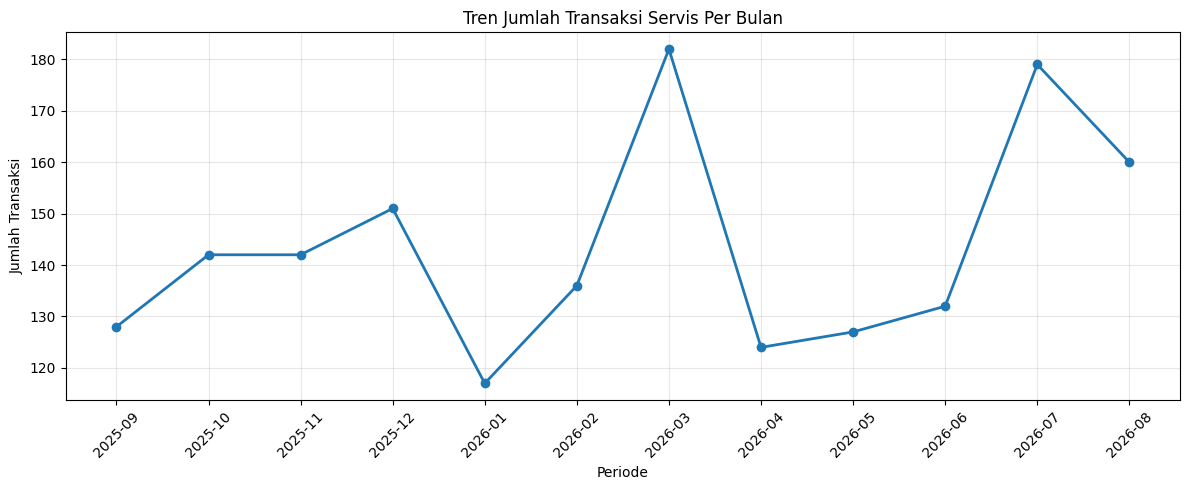

In [13]:

# VISUALISASI TRANSAKSI BULANAN - GRAFIK GARIS

plt.figure(figsize=(12, 5))

plt.plot(
    transaksi_bulanan["Bulan"].astype(str),
    transaksi_bulanan["Jumlah_Transaksi"],
    marker="o",
    linewidth=2
)

plt.title("Tren Jumlah Transaksi Servis Per Bulan")
plt.xlabel("Periode")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "01_transaksi_bulanan.png",
    dpi=300
)

plt.show()


In [14]:
# MEMERIKSA FILE GRAFIK

file_grafik = (
    GRAPH_DIR / "01_transaksi_bulanan.png"
)

print("Grafik berhasil disimpan:", file_grafik.exists())

Grafik berhasil disimpan: True


## 2. Pemeriksaan Status Transaksi

Pada tahap ini dilakukan pemeriksaan terhadap
status transaksi untuk mengetahui kondisi setiap
transaksi servis.

Pemeriksaan ini bertujuan untuk membedakan transaksi
yang telah selesai, transaksi yang masih dalam proses,
transaksi yang dibatalkan, serta transaksi yang
memerlukan pemeriksaan lebih lanjut.

Hasil pemeriksaan akan menjadi dasar dalam menentukan
data yang layak digunakan untuk analisis potensi
penjualan sparepart.

In [15]:
# PEMBERSIHAN KOLOM STATUS

df["Status_Bersih"] = (
    df["Status"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("KOSONG")
)

print("Pembersihan status selesai!")

display(
    df[["Status", "Status_Bersih"]].head(10)
)

Pembersihan status selesai!


,Status,Status_Bersih
164,Paid,PAID
165,Paid,PAID
166,Paid,PAID
167,Paid,PAID
168,Paid,PAID
169,Paid,PAID
170,Paid,PAID
171,Paid,PAID
172,Paid,PAID
173,No Action / Cancel,NO ACTION / CANCEL


In [16]:
# REKAPITULASI STATUS TRANSAKSI

status_summary = (
    df.groupby("Status_Bersih")
    .agg(
        Jumlah_Transaksi=("Status_Bersih", "size"),
        Deskripsi_Terisi=("Description", "count"),
        Amount_Terisi=("Amount", "count")
    )
    .reset_index()
    .sort_values(
        "Jumlah_Transaksi",
        ascending=False
    )
)

display(status_summary)

,Status_Bersih,Jumlah_Transaksi,Deskripsi_Terisi,Amount_Terisi
7,PAID,1558,1556,1546
6,NO ACTION / CANCEL,69,65,1
3,DP,51,51,51
2,DONE,18,18,0
8,PROGRESS,13,13,1
9,REFUND,5,5,3
5,KOSONG,3,2,2
0,CICILAN,1,1,1
1,COMPLAIN,1,1,1
4,FREE,1,1,0


Berdasarkan hasil pemeriksaan status transaksi pada periode September 2025 sampai Agustus 2026, diperoleh sebanyak 1.720 transaksi. Status PAID merupakan status dengan jumlah terbanyak, yaitu 1.558 transaksi. Selain itu, ditemukan 7 transaksi dengan deskripsi kosong. Pemeriksaan ini dilakukan untuk mengetahui kondisi transaksi sebelum dilanjutkan ke tahap preprocessing dan identifikasi sparepart.

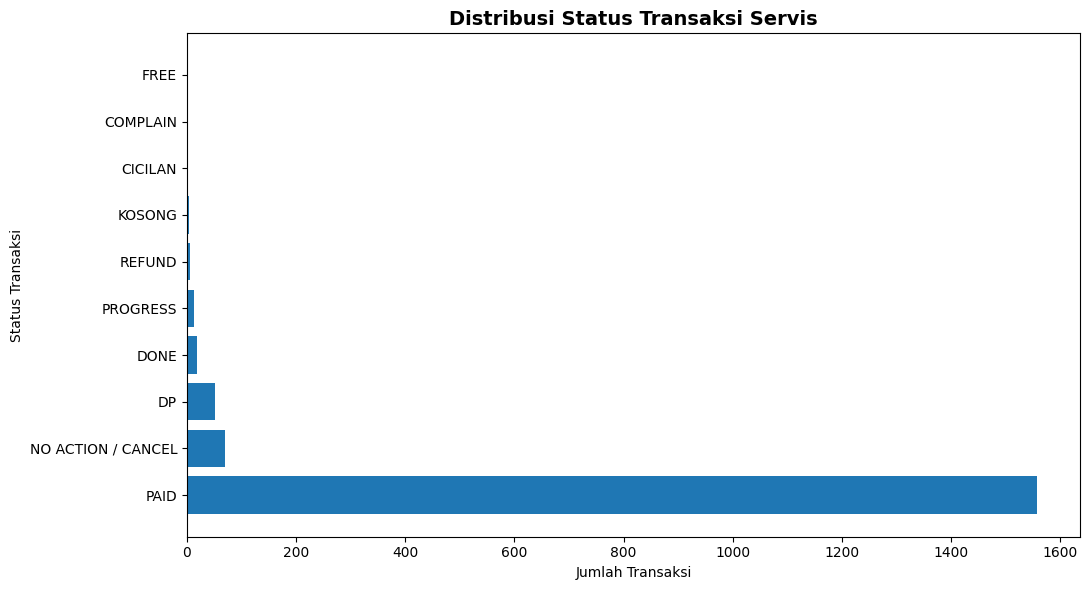

In [17]:
# VISUALISASI DISTRIBUSI STATUS TRANSAKSI

plt.figure(figsize=(11, 6))

plt.barh(
    status_summary["Status_Bersih"].astype(str),
    status_summary["Jumlah_Transaksi"]
)

plt.title(
    "Distribusi Status Transaksi Servis",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Jumlah Transaksi")
plt.ylabel("Status Transaksi")

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "02_distribusi_status.png",
    dpi=300
)

plt.show()


Grafik ini menunjukkan distribusi transaksi berdasarkan statusnya. Dari hasil pengolahan, mayoritas transaksi berstatus PAID sebanyak 1.558 transaksi. Kami melakukan pemeriksaan ini untuk memastikan transaksi yang dianalisis benar-benar sesuai dengan definisi penjualan yang digunakan dalam penelitian.

## 3. Pemeriksaan Transaksi yang Memerlukan Review

Tahap ini dilakukan untuk memeriksa transaksi
yang memiliki status atau kondisi khusus.

Pemeriksaan bertujuan untuk memastikan bahwa data
yang digunakan dalam analisis tidak mencampurkan
transaksi penjualan yang berhasil dengan transaksi
yang belum selesai atau dibatalkan.

In [18]:
# MENAMPILKAN TRANSAKSI YANG PERLU DIPERIKSA

status_review = [
    "DONE",
    "DP",
    "NO ACTION / CANCEL",
    "PROGRESS",
    "REFUND",
    "FREE",
    "CICILAN",
    "COMPLAIN",
    "KOSONG"
]

df_review_status = df[
    df["Status_Bersih"].isin(status_review)
].copy()

kolom_review = [
    "Tanggal_Diperbaiki",
    "Name",
    "Device",
    "Description",
    "Status_Bersih",
    "Payment Date",
    "Amount"
]

display(
    df_review_status[kolom_review]
    .sort_values("Tanggal_Diperbaiki")
)

,Tanggal_Diperbaiki,Name,Device,Description,Status_Bersih,Payment Date,Amount
173,2025-09-03,P0145,Applewatch S3 42 MM GPS,Mati Total,NO ACTION / CANCEL,NaN,NaN
189,2025-09-08,P0157,iPhone 11 Pro Max,Cek Restart,NO ACTION / CANCEL,2025-09-08 00:00:00,NaN
191,2025-09-08,P0159,iPhone 11,NaN,NO ACTION / CANCEL,2025-09-08 00:00:00,NaN
194,2025-09-08,P0161,iPhone X,Mati Total ex.service,NO ACTION / CANCEL,NaN,NaN
197,2025-09-09,P0087,iPhone 7+,Mati Total,PROGRESS,NaN,NaN
...,...,...,...,...,...,...,...
1863,2026-08-28,P1059,iPhone 13,DP LCD ORI APPLE,DP,2026-08-28 00:00:00,1000000.0
1867,2026-08-29,P1052,iPhone 14,LCD Ori Apple + Free Ag Black,NO ACTION / CANCEL,2026-08-29 00:00:00,NaN
1878,2026-08-30,P1062,iPhone 13,Baterai OEM + AG Black,KOSONG,2026-08-30 00:00:00,680000.0
1876,2026-08-30,P1061,iPhone 12 Pro,Cek mati total,PROGRESS,NaN,NaN


## 4. Pemeriksaan Kelengkapan Deskripsi Transaksi

Pada tahap ini dilakukan pemeriksaan terhadap
kelengkapan deskripsi transaksi servis.

Kolom deskripsi merupakan sumber informasi utama
untuk mengidentifikasi komponen dan sparepart
yang tercatat dalam transaksi.

In [19]:
# MEMERIKSA DESKRIPSI KOSONG

jumlah_deskripsi_kosong = (
    df["Description"].isna().sum()
)

jumlah_deskripsi_terisi = (
    df["Description"].notna().sum()
)

print("Deskripsi kosong:", jumlah_deskripsi_kosong)
print("Deskripsi terisi:", jumlah_deskripsi_terisi)

Deskripsi kosong: 7
Deskripsi terisi: 1713


In [20]:
# MENAMPILKAN DATA DESKRIPSI KOSONG

df_deskripsi_kosong = df[
    df["Description"].isna()
]

display(
    df_deskripsi_kosong[
        [
            "Tanggal_Diperbaiki",
            "Name",
            "Device",
            "Damage Type",
            "Status",
            "Amount"
        ]
    ]
)

,Tanggal_Diperbaiki,Name,Device,Damage Type,Status,Amount
191,2025-09-08,P0159,iPhone 11,Interface,No Action / Cancel,NaN
585,2025-12-03,P0365,iPhone XR,NaN,Paid,950000.0
786,2026-01-16,P0471,iPhone XS,NaN,Paid,400000.0
975,2026-02-28,NaN,NaN,NaN,NaN,NaN
1424,2026-06-04,P0747,iPhone 12,Machine,No Action / Cancel,NaN
1553,2026-07-02,P0922,iPhone 6s,NaN,No Action / Cancel,NaN
1766,2026-08-06,P0121,iPhone XR,NaN,No Action / Cancel,NaN


In [21]:
# MENYIMPAN HASIL PEMERIKSAAN

FILE_AUDIT = (
    OUTPUT_DIR / "Hasil_Audit_Transaksi.xlsx"
)

with pd.ExcelWriter(
    FILE_AUDIT,
    engine="openpyxl"
) as writer:

    status_summary.to_excel(
        writer,
        sheet_name="Distribusi_Status",
        index=False
    )

    df_review_status[kolom_review].to_excel(
        writer,
        sheet_name="Review_Status",
        index=False
    )

    df_deskripsi_kosong.to_excel(
        writer,
        sheet_name="Deskripsi_Kosong",
        index=False
    )

print("Hasil audit berhasil disimpan!")
print(FILE_AUDIT)

Hasil audit berhasil disimpan!
D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\hasil\Hasil_Audit_Transaksi.xlsx


In [22]:
# STATISTIK DESKRIPTIF

print("STATISTIK DESKRIPTIF AMOUNT")
display(df["Amount"].describe())
print("Skewness:", df["Amount"].skew())

for kolom in ["Device", "Damage Type", "Technician"]:
    print(f"\n{kolom}: {df[kolom].nunique()} kategori unik")
    display(df[kolom].value_counts().head(5))

STATISTIK DESKRIPTIF AMOUNT


count    1.606000e+03
mean     7.261582e+05
std      7.543912e+05
min      3.000000e+04
25%      3.500000e+05
50%      5.000000e+05
75%      8.500000e+05
max      9.500000e+06
Name: Amount, dtype: float64

Skewness: 4.280285708196674

Device: 75 kategori unik


Device
iPhone 11        360
iPhone 13        218
iPhone XR        161
iPhone X         109
iPhone 11 Pro    101
Name: count, dtype: int64


Damage Type: 7 kategori unik


Damage Type
Interface              1227
Etc                     279
Machine                 128
Repair LCD               10
Machine + Interface       7
Name: count, dtype: int64


Technician: 10 kategori unik


Technician
T001    837
T008    218
T006    195
T009    150
T002     71
Name: count, dtype: int64

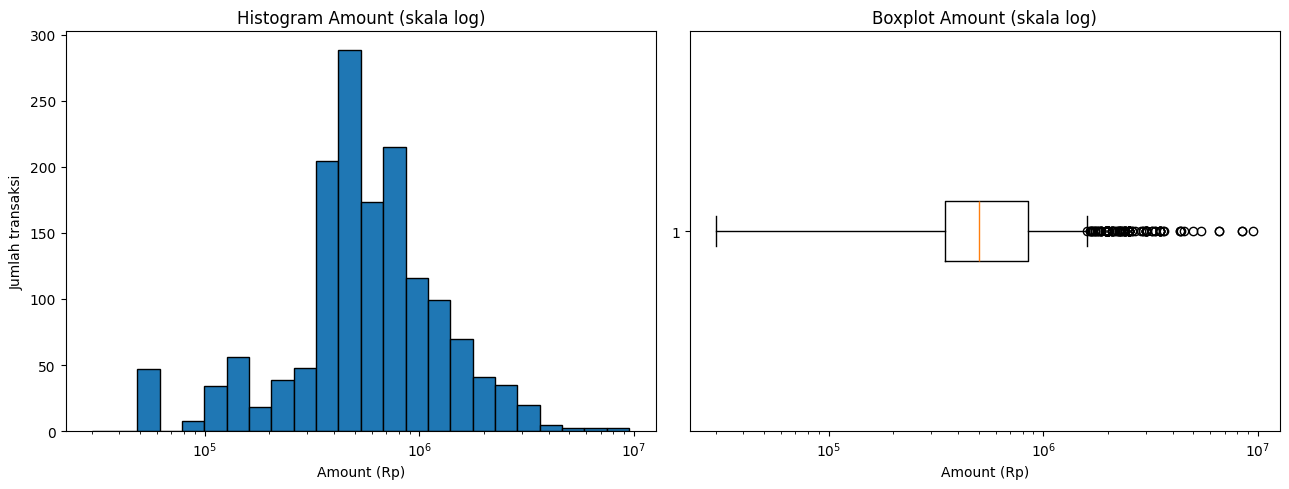

In [23]:
# HISTOGRAM DAN BOXPLOT AMOUNT

amount = df["Amount"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    amount,
    bins=np.logspace(np.log10(amount.min()), np.log10(amount.max()), 25),
    edgecolor="black"
)
axes[0].set_xscale("log")
axes[0].set_title("Histogram Amount (skala log)")
axes[0].set_xlabel("Amount (Rp)")
axes[0].set_ylabel("Jumlah transaksi")

axes[1].boxplot(amount, vert=False)
axes[1].set_xscale("log")
axes[1].set_title("Boxplot Amount (skala log)")
axes[1].set_xlabel("Amount (Rp)")

plt.tight_layout()
plt.savefig(GRAFIK_DIR / "07_distribusi_amount.png", dpi=300, bbox_inches="tight")
plt.show()

# BAGIAN C — DATA PREPROCESSING

## 5. Pembersihan Deskripsi Transaksi (Description Cleaning)

Tahap ini dilakukan untuk membersihkan dan menyeragamkan
format teks pada kolom Description.

Pembersihan meliputi pengubahan huruf menjadi kapital,
penghapusan spasi berlebih, dan penanganan teks kosong.

Tahap ini bertujuan untuk mempermudah proses identifikasi,
klasifikasi, dan normalisasi nama sparepart pada tahap
pengolahan data selanjutnya.

In [24]:
# MEMBUAT SALINAN DATA UNTUK PREPROCESSING

df_preprocess = df.copy()

print("Salinan dataset berhasil dibuat!")
print("Jumlah baris:", len(df_preprocess))

Salinan dataset berhasil dibuat!
Jumlah baris: 1720


In [25]:
# PEMBERSIHAN TEKS DESKRIPSI

df_preprocess["Description_Bersih"] = (
    df_preprocess["Description"]
    .astype("string")
    .str.replace("\u00A0", " ", regex=False)
    .str.upper()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Mengubah teks kosong menjadi missing value
df_preprocess["Description_Bersih"] = (
    df_preprocess["Description_Bersih"]
    .replace("", pd.NA)
)

print("Pembersihan deskripsi berhasil!")

Pembersihan deskripsi berhasil!


In [26]:
# MEMBANDINGKAN DESKRIPSI SEBELUM DAN SESUDAH CLEANING

perbandingan_deskripsi = df_preprocess[
    [
        "Description",
        "Description_Bersih"
    ]
].drop_duplicates()

display(perbandingan_deskripsi.head(30))

,Description,Description_Bersih
164,Lcd Oem + Free Ag Black Biasa,LCD OEM + FREE AG BLACK BIASA
165,LCD Oem + Free Ag Dinamis Privacy,LCD OEM + FREE AG DINAMIS PRIVACY
166,Baterai Ori + Ag Black Biasa,BATERAI ORI + AG BLACK BIASA
167,Fleksibel Charge,FLEKSIBEL CHARGE
168,Cek mati total > Mati total ex. service,CEK MATI TOTAL > MATI TOTAL EX. SERVICE
...,...,...
200,Ag Ceramic Privacy,AG CERAMIC PRIVACY
202,Mati total ex. service,MATI TOTAL EX. SERVICE
203,Mati total > CPU,MATI TOTAL > CPU
205,Lcd Standard + Free Ag Ceramic Privacy,LCD STANDARD + FREE AG CERAMIC PRIVACY


In [27]:
# AUDIT HASIL DESCRIPTION CLEANING

print(
    "Jumlah deskripsi kosong sebelum cleaning:",
    df_preprocess["Description"].isna().sum()
)

print(
    "Jumlah deskripsi kosong setelah cleaning:",
    df_preprocess["Description_Bersih"].isna().sum()
)

print(
    "Jumlah deskripsi unik sebelum cleaning:",
    df_preprocess["Description"].nunique()
)

print(
    "Jumlah deskripsi unik setelah cleaning:",
    df_preprocess["Description_Bersih"].nunique()
)

Jumlah deskripsi kosong sebelum cleaning: 7
Jumlah deskripsi kosong setelah cleaning: 7
Jumlah deskripsi unik sebelum cleaning: 589
Jumlah deskripsi unik setelah cleaning: 467


In [28]:
# MENAMPILKAN DESKRIPSI YANG BERUBAH

mask_perubahan = (
    df_preprocess["Description"]
    .astype("string")
    .fillna("<KOSONG>")
    !=
    df_preprocess["Description_Bersih"]
    .fillna("<KOSONG>")
)

deskripsi_berubah = df_preprocess.loc[
    mask_perubahan,
    [
        "Description",
        "Description_Bersih"
    ]
]

print(
    "Jumlah baris yang mengalami perubahan:",
    len(deskripsi_berubah)
)

display(deskripsi_berubah.head(30))

Jumlah baris yang mengalami perubahan: 1686


,Description,Description_Bersih
164,Lcd Oem + Free Ag Black Biasa,LCD OEM + FREE AG BLACK BIASA
165,LCD Oem + Free Ag Dinamis Privacy,LCD OEM + FREE AG DINAMIS PRIVACY
166,Baterai Ori + Ag Black Biasa,BATERAI ORI + AG BLACK BIASA
167,Fleksibel Charge,FLEKSIBEL CHARGE
168,Cek mati total > Mati total ex. service,CEK MATI TOTAL > MATI TOTAL EX. SERVICE
...,...,...
189,Cek Restart,CEK RESTART
190,Baterai Ori,BATERAI ORI
192,Jasa Pasang Baterai,JASA PASANG BATERAI
193,Lcd Oem,LCD OEM


## 6. Pembuatan ID Transaksi

Tahap ini dilakukan untuk memberikan identitas unik
pada setiap transaksi servis.

ID transaksi digunakan untuk menghubungkan beberapa
komponen sparepart yang berasal dari transaksi yang sama
serta mencegah terjadinya penghitungan ganda.

In [29]:
# MEMBUAT ID TRANSAKSI

kolom_id = [
    "Sumber_File",
    "Sheet_Asal",
    "Baris_Asal"
]

if all(kolom in df_preprocess.columns for kolom in kolom_id):

    df_preprocess["ID_Transaksi"] = (
        df_preprocess[kolom_id]
        .fillna("")
        .astype(str)
        .agg("|".join, axis=1)
    )

else:

    df_preprocess["ID_Transaksi"] = (
        df_preprocess.index.astype(str)
    )

print("ID transaksi berhasil dibuat!")

display(
    df_preprocess[
        [
            "ID_Transaksi",
            "Tanggal_Diperbaiki",
            "Description_Bersih"
        ]
    ].head(10)
)

ID transaksi berhasil dibuat!


,ID_Transaksi,Tanggal_Diperbaiki,Description_Bersih
164,Sumber_01.xlsx|SEPTEMBER|2,2025-09-01,LCD OEM + FREE AG BLACK BIASA
165,Sumber_01.xlsx|SEPTEMBER|3,2025-09-02,LCD OEM + FREE AG DINAMIS PRIVACY
166,Sumber_01.xlsx|SEPTEMBER|4,2025-09-02,BATERAI ORI + AG BLACK BIASA
167,Sumber_01.xlsx|SEPTEMBER|5,2025-09-02,FLEKSIBEL CHARGE
168,Sumber_01.xlsx|SEPTEMBER|6,2025-09-02,CEK MATI TOTAL > MATI TOTAL EX. SERVICE
169,Sumber_01.xlsx|SEPTEMBER|7,2025-09-02,RESTART > SWAPBOARD + FREE AG CERAMIC PRIVACY
170,Sumber_01.xlsx|SEPTEMBER|8,2025-09-03,LCD OEM + BATERAI OEM
171,Sumber_01.xlsx|SEPTEMBER|9,2025-09-03,LCD OEM + BATERAI OEM + SPEAKER ATAS
172,Sumber_01.xlsx|SEPTEMBER|10,2025-09-03,BATERAI ORI
173,Sumber_01.xlsx|SEPTEMBER|11,2025-09-03,MATI TOTAL


Di sini kami menggunakan informasi file sumber, sheet, dan nomor baris untuk mengenali asal transaksi, apabila kolom tersebut tidak tersedia, program menggunakan indeks baris sebagai identitas alternatif.

## 7. Pemisahan Komponen Transaksi

Tahap ini dilakukan untuk mengidentifikasi beberapa
komponen yang tercatat dalam satu deskripsi transaksi.

Pemisahan dilakukan terhadap tanda "+" dan "&"
yang berfungsi sebagai pemisah kandidat komponen.

Tanda ">" dipertahankan terlebih dahulu untuk
menghindari kesalahan identifikasi antara diagnosis
kerusakan dan tindakan servis.

In [30]:
# MEMISAHKAN KANDIDAT KOMPONEN TRANSAKSI

df_kandidat = df_preprocess[
    df_preprocess["Description_Bersih"].notna()
].copy()

# Memisahkan komponen berdasarkan tanda + dan &
df_kandidat["Komponen_Kandidat"] = (
    df_kandidat["Description_Bersih"]
    .str.split(r"\s*(?:\+|&)\s*", regex=True)
)

# Mengubah daftar komponen menjadi baris terpisah
df_kandidat = df_kandidat.explode(
    "Komponen_Kandidat"
)

# Membersihkan hasil pemisahan
df_kandidat["Komponen_Kandidat"] = (
    df_kandidat["Komponen_Kandidat"]
    .str.strip()
)

# Menghapus komponen kosong
df_kandidat = df_kandidat[
    df_kandidat["Komponen_Kandidat"].notna()
    & (df_kandidat["Komponen_Kandidat"] != "")
].copy()

print("Pemisahan komponen selesai!")

display(
    df_kandidat[
        [
            "ID_Transaksi",
            "Description_Bersih",
            "Komponen_Kandidat"
        ]
    ].head(20)
)

Pemisahan komponen selesai!


,ID_Transaksi,Description_Bersih,Komponen_Kandidat
164,Sumber_01.xlsx|SEPTEMBER|2,LCD OEM + FREE AG BLACK BIASA,LCD OEM
164,Sumber_01.xlsx|SEPTEMBER|2,LCD OEM + FREE AG BLACK BIASA,FREE AG BLACK BIASA
165,Sumber_01.xlsx|SEPTEMBER|3,LCD OEM + FREE AG DINAMIS PRIVACY,LCD OEM
165,Sumber_01.xlsx|SEPTEMBER|3,LCD OEM + FREE AG DINAMIS PRIVACY,FREE AG DINAMIS PRIVACY
166,Sumber_01.xlsx|SEPTEMBER|4,BATERAI ORI + AG BLACK BIASA,BATERAI ORI
166,Sumber_01.xlsx|SEPTEMBER|4,BATERAI ORI + AG BLACK BIASA,AG BLACK BIASA
167,Sumber_01.xlsx|SEPTEMBER|5,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE
168,Sumber_01.xlsx|SEPTEMBER|6,CEK MATI TOTAL > MATI TOTAL EX. SERVICE,CEK MATI TOTAL > MATI TOTAL EX. SERVICE
169,Sumber_01.xlsx|SEPTEMBER|7,RESTART > SWAPBOARD + FREE AG CERAMIC PRIVACY,RESTART > SWAPBOARD
169,Sumber_01.xlsx|SEPTEMBER|7,RESTART > SWAPBOARD + FREE AG CERAMIC PRIVACY,FREE AG CERAMIC PRIVACY


## 8. Rekapitulasi Frekuensi Kandidat Komponen

Tahap ini dilakukan untuk menghitung frekuensi
kemunculan setiap kandidat komponen berdasarkan
transaksi servis.

Hasil rekapitulasi digunakan untuk membantu proses
identifikasi, klasifikasi, dan normalisasi sparepart.

In [31]:
# MENGHITUNG FREKUENSI KANDIDAT

df_kandidat = df_kandidat.drop_duplicates(
    subset=[
        "ID_Transaksi",
        "Komponen_Kandidat"
    ]
)

rekap_kandidat = (
    df_kandidat
    .groupby("Komponen_Kandidat")
    .agg(
        Jumlah_Transaksi=(
            "ID_Transaksi",
            "nunique"
        )
    )
    .reset_index()
    .sort_values(
        "Jumlah_Transaksi",
        ascending=False
    )
)

print(
    "Jumlah kandidat komponen unik:",
    len(rekap_kandidat)
)

display(rekap_kandidat.head(30))

Jumlah kandidat komponen unik: 336


,Komponen_Kandidat,Jumlah_Transaksi
32,BATERAI OEM,350
243,LCD STANDARD,344
168,FREE AG BLACK BIASA,209
35,BATERAI ORI,110
4,AG BLACK BIASA,94
...,...,...
223,KACA KAMERA BAWAH,11
173,FREE AG DINAMIS PRIVACY,10
187,GREENSCREEN > REPAIR LCD,9
109,CLEAR CASE,9


## 9. Klasifikasi dan Review Kandidat Komponen

Tahap ini dilakukan untuk mengelompokkan kandidat
komponen berdasarkan jenisnya.

Klasifikasi dilakukan melalui pemeriksaan deskripsi
untuk membedakan sparepart, aksesori, diagnosis
kerusakan, jasa atau tindakan servis, serta deskripsi
yang masih memerlukan konfirmasi.

In [32]:
# MEMBUAT TEMPLATE REVIEW MANUAL

template_review = rekap_kandidat.copy()

template_review["Kategori"] = ""

template_review["Nama_Normalisasi"] = ""

template_review["Catatan"] = ""

display(template_review.head(30))

,Komponen_Kandidat,Jumlah_Transaksi,Kategori,Nama_Normalisasi,Catatan
32,BATERAI OEM,350,,,
243,LCD STANDARD,344,,,
168,FREE AG BLACK BIASA,209,,,
35,BATERAI ORI,110,,,
4,AG BLACK BIASA,94,,,
...,...,...,...,...,...
223,KACA KAMERA BAWAH,11,,,
173,FREE AG DINAMIS PRIVACY,10,,,
187,GREENSCREEN > REPAIR LCD,9,,,
109,CLEAR CASE,9,,,


In [33]:
# MENENTUKAN FOLDER REVIEW MANUAL

from pathlib import Path

BASE_DIR = Path.cwd()

REVIEW_DIR = BASE_DIR / "review_manual"

REVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Folder review:", REVIEW_DIR.resolve())
print("Folder berhasil disiapkan!")

Folder review: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\review_manual
Folder berhasil disiapkan!


In [34]:
# MENYIMPAN TEMPLATE REVIEW

FILE_TEMPLATE = (
    REVIEW_DIR / "Review_Klasifikasi_Sparepart.xlsx"
)

template_review.to_excel(
    FILE_TEMPLATE,
    index=False
)

print("Template berhasil disimpan!")
print("Lokasi file:", FILE_TEMPLATE.resolve())

Template berhasil disimpan!
Lokasi file: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\review_manual\Review_Klasifikasi_Sparepart.xlsx


## 9. Klasifikasi Otomatis Kandidat Komponen

Tahap ini dilakukan untuk mengelompokkan kandidat
komponen menggunakan aturan pencocokan kata kunci
(rule-based classification).

Kandidat dikelompokkan ke dalam kategori sparepart,
aksesori, diagnosis, jasa atau tindakan servis,
serta komponen yang memerlukan pemeriksaan manual.

Hasil klasifikasi otomatis selanjutnya divalidasi
untuk memastikan kesesuaian kategori dan nama komponen.

In [35]:
# PERBAIKAN ATURAN KLASIFIKASI KOMPONEN

def klasifikasi_komponen(teks):

    if pd.isna(teks):
        return "Perlu Konfirmasi"

    teks = str(teks).upper().strip()

    # 1. AKSESORI
    aksesori = [
        "FREE AG",
        "AG BLACK",
        "AG BLUE LIGHT",
        "AG CERAMIC",
        "AG DINAMIS",
        "BLUE LIGHT",
        "TEMPERED GLASS",
        "ANTIGORE",
        "HYDROGEL",
        "CASE",
        "CASING",
        "USB C LIGHTNING CABLE",
        "USB C TO LIGHTNING CABLE",
        "USB C TO LIGHNTING CABLE",
        "USB CABLE APPLE WATCH",
        "LIGHTNING CABLE"
    ]

    if any(kata in teks for kata in aksesori):
        return "Aksesori"

    # 2. DIAGNOSIS KERUSAKAN
    diagnosis = [
        "MATI TOTAL",
        "NO SIGNAL",
        "BOOTLOOP",
        "BOOT LOOP",
        "GHOST TOUCH",
        "KEN A AIR",
        "KENA AIR",
        "BERGARIS",
        "LCD BLANK",
        "GREENSCREEN",
        "GREEN SCREEN"
    ]

    # Deskripsi gabungan diagnosis dan tindakan
    # harus diperiksa lebih lanjut
    if ">" in teks:
        return "Perlu Konfirmasi"

    if any(kata in teks for kata in diagnosis):
        return "Diagnosis"

    # 3. JASA / TINDAKAN
    tindakan = [
        "REPAIR",
        "SERVICE",
        "SERVIS",
        "CEK ",
        "RESET",
        "FLASH",
        "INSTALL",
        "UPDATE IOS",
        "CLEANING",
        "RESTART",
        "PERBAIKAN",
        "SWAPBOARD"
    ]

    if any(kata in teks for kata in tindakan):
        return "Jasa/Tindakan"

    # 4. SPAREPART
    sparepart = [
        "BATERAI",
        "BATTERY",
        "BATREI",
        "LCD",
        "DISPLAY",
        "KAMERA",
        "CAMERA",
        "SPEAKER",
        "FLEKSIBEL",
        "FLEKSIBLE",
        "FLEX",
        "CHARGING PORT",
        "PORT CHARGER",
        "KONEKTOR",
        "CONNECTOR",
        "MIC ",
        "MICROPHONE",
        "VIBRATOR",
        "BUZZER",
        "ANTENA",
        "ANTENNA",
        "BACKGLASS",
        "BACK GLASS",
        "SIM TRAY",
        "TOUCHSCREEN",
        "TOUCH SCREEN"
    ]

    if any(kata in teks for kata in sparepart):
        return "Sparepart"

    # 5. BELUM DIKENALI
    return "Perlu Konfirmasi"

In [36]:
# MENJALANKAN KEMBALI KLASIFIKASI

template_auto = rekap_kandidat.copy()

template_auto["Kategori"] = (
    template_auto["Komponen_Kandidat"]
    .apply(klasifikasi_komponen)
)

template_auto["Nama_Normalisasi"] = np.where(
    template_auto["Kategori"] == "Sparepart",
    template_auto["Komponen_Kandidat"],
    ""
)

template_auto["Catatan"] = ""

print("Klasifikasi diperbarui!")

display(template_auto.head(30))

Klasifikasi diperbarui!


,Komponen_Kandidat,Jumlah_Transaksi,Kategori,Nama_Normalisasi,Catatan
32,BATERAI OEM,350,Sparepart,BATERAI OEM,
243,LCD STANDARD,344,Sparepart,LCD STANDARD,
168,FREE AG BLACK BIASA,209,Aksesori,,
35,BATERAI ORI,110,Sparepart,BATERAI ORI,
4,AG BLACK BIASA,94,Aksesori,,
...,...,...,...,...,...
223,KACA KAMERA BAWAH,11,Sparepart,KACA KAMERA BAWAH,
173,FREE AG DINAMIS PRIVACY,10,Aksesori,,
187,GREENSCREEN > REPAIR LCD,9,Perlu Konfirmasi,,
109,CLEAR CASE,9,Aksesori,,


In [37]:
# REKAPITULASI KLASIFIKASI TERBARU

rekap_klasifikasi = (
    template_auto
    .groupby("Kategori")
    .agg(
        Jumlah_Kandidat=("Komponen_Kandidat", "count"),
        Jumlah_Transaksi=("Jumlah_Transaksi", "sum")
    )
    .reset_index()
)

display(rekap_klasifikasi)

,Kategori,Jumlah_Kandidat,Jumlah_Transaksi
0,Aksesori,33,633
1,Diagnosis,14,83
2,Jasa/Tindakan,27,79
3,Perlu Konfirmasi,159,260
4,Sparepart,103,1305


hasilnya digunakan untuk mengetahui berapa saja kandidat yang sudah dikenali sebagai sparepart, aksesori, diagnosis, dan kategori lainnya.

In [38]:
# KANDIDAT YANG MASIH PERLU REVIEW

data_review_manual = template_auto[
    template_auto["Kategori"] == "Perlu Konfirmasi"
].copy()

print(
    "Jumlah kandidat perlu konfirmasi:",
    len(data_review_manual)
)

display(data_review_manual)

Jumlah kandidat perlu konfirmasi: 159


,Komponen_Kandidat,Jumlah_Transaksi,Kategori,Nama_Normalisasi,Catatan
187,GREENSCREEN > REPAIR LCD,9,Perlu Konfirmasi,,
75,CEK MATI TOTAL > LCD STANDARD,7,Perlu Konfirmasi,,
328,USB-C POWER ADAPTOR,7,Perlu Konfirmasi,,
68,CEK MATI TOTAL > IC CHARGE,6,Perlu Konfirmasi,,
319,USB CABLE IWATCH,5,Perlu Konfirmasi,,
...,...,...,...,...,...
29,BAKCGLASS PURPLE,1,Perlu Konfirmasi,,
30,BATERA ORI,1,Perlu Konfirmasi,,
304,TIDAK BISA CHARGER > FLEXIBLE CHARGER,1,Perlu Konfirmasi,,
305,TIDAK BISA SENTUH > IC TOUCH,1,Perlu Konfirmasi,,


In [39]:
# MENYIMPAN HASIL KLASIFIKASI TERBARU

FILE_REVIEW_AUTO = (
    REVIEW_DIR / "Review_Klasifikasi_Otomatis.xlsx"
)

with pd.ExcelWriter(
    FILE_REVIEW_AUTO,
    engine="openpyxl"
) as writer:

    template_auto.to_excel(
        writer,
        sheet_name="Semua_Kandidat",
        index=False
    )

    data_review_manual.to_excel(
        writer,
        sheet_name="Perlu_Review",
        index=False
    )

    rekap_klasifikasi.to_excel(
        writer,
        sheet_name="Rekap_Kategori",
        index=False
    )

print("Hasil klasifikasi terbaru berhasil disimpan!")

Hasil klasifikasi terbaru berhasil disimpan!


## 13. Normalisasi Nama Sparepart

Tahap ini dilakukan untuk menyeragamkan variasi
penulisan nama sparepart yang merujuk pada komponen
yang sama.

Normalisasi dilakukan berdasarkan kesamaan jenis
komponen, model perangkat, dan spesifikasi barang.

In [40]:
print("Kolom template_auto:")
print(template_auto.columns.tolist())

Kolom template_auto:
['Komponen_Kandidat', 'Jumlah_Transaksi', 'Kategori', 'Nama_Normalisasi', 'Catatan']


In [41]:
# TAHAP 26 — MENGAMBIL KANDIDAT SPAREPART

if "template_auto" not in globals():

    print("Variabel template_auto belum tersedia.")
    print("Jalankan Kernel > Restart Kernel and Run All Cells.")

else:

    df_kandidat_sparepart = template_auto[
        template_auto["Kategori"] == "Sparepart"
    ].copy()

    df_kandidat_sparepart = (
        df_kandidat_sparepart
        .sort_values(
            "Jumlah_Transaksi",
            ascending=False
        )
    )

    print(
        "Jumlah kandidat sparepart:",
        len(df_kandidat_sparepart)
    )

    display(
        df_kandidat_sparepart[
            [
                "Komponen_Kandidat",
                "Jumlah_Transaksi",
                "Nama_Normalisasi"
            ]
        ].head(50)
    )

Jumlah kandidat sparepart: 103


,Komponen_Kandidat,Jumlah_Transaksi,Nama_Normalisasi
32,BATERAI OEM,350,BATERAI OEM
243,LCD STANDARD,344,LCD STANDARD
35,BATERAI ORI,110,BATERAI ORI
235,LCD OEM,72,LCD OEM
242,LCD ORI OLED,50,LCD ORI OLED
...,...,...,...
23,BACKGLASS PINK,2,BACKGLASS PINK
251,LCD TDK BISA DISENTUH,2,LCD TDK BISA DISENTUH
239,LCD ORI 1:1,2,LCD ORI 1:1
246,LCD STANDARD JK INCELL,2,LCD STANDARD JK INCELL


hasil ini berfungsi untuk mengambil komponen yang sudah diklasifikasi sebagai Sparepart dan mengurutkannya berdasarkan frekuensi transaksi, kemudian ini menampilkan 50 kandidat teratas yang di mana hasil klasifikasi sebelumnya terdapat 103 kandidat Sparepart

In [42]:
# TAHAP 27 — MEMBUAT TEMPLATE NORMALISASI

template_normalisasi = (
    df_kandidat_sparepart[
        [
            "Komponen_Kandidat",
            "Jumlah_Transaksi"
        ]
    ].copy()
)

template_normalisasi["Nama_Normalisasi"] = (
    template_normalisasi["Komponen_Kandidat"]
)

template_normalisasi["Status_Validasi"] = (
    "Belum Diperiksa"
)

template_normalisasi["Catatan_Validasi"] = ""

display(
    template_normalisasi.head(30)
)

,Komponen_Kandidat,Jumlah_Transaksi,Nama_Normalisasi,Status_Validasi,Catatan_Validasi
32,BATERAI OEM,350,BATERAI OEM,Belum Diperiksa,
243,LCD STANDARD,344,LCD STANDARD,Belum Diperiksa,
35,BATERAI ORI,110,BATERAI ORI,Belum Diperiksa,
235,LCD OEM,72,LCD OEM,Belum Diperiksa,
242,LCD ORI OLED,50,LCD ORI OLED,Belum Diperiksa,
...,...,...,...,...,...
206,IC DISPLAY,4,IC DISPLAY,Belum Diperiksa,
143,FLEKSIBEL CHARGER,4,FLEKSIBEL CHARGER,Belum Diperiksa,
247,LCD STANDARD WHITE,4,LCD STANDARD WHITE,Belum Diperiksa,
244,LCD STANDARD BLACK,4,LCD STANDARD BLACK,Belum Diperiksa,


In [43]:
# MENYIMPAN TEMPLATE NORMALISASI KE EXCEL

from pathlib import Path

REVIEW_DIR = Path.cwd() / "review_manual"

REVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FILE_NORMALISASI = (
    REVIEW_DIR / "Template_Normalisasi_Sparepart.xlsx"
)

template_normalisasi.to_excel(
    FILE_NORMALISASI,
    index=False
)

print("Template normalisasi berhasil disimpan!")
print("Lokasi file:", FILE_NORMALISASI.resolve())

Template normalisasi berhasil disimpan!
Lokasi file: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\review_manual\Template_Normalisasi_Sparepart.xlsx


In [44]:
# TAHAP 28 — MENYIMPAN TEMPLATE NORMALISASI

if "REVIEW_DIR" not in globals():
    print("Folder REVIEW_DIR belum tersedia.")

else:
    REVIEW_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    FILE_NORMALISASI = (
        REVIEW_DIR / "Template_Normalisasi_Sparepart.xlsx"
    )

    template_normalisasi.to_excel(
        FILE_NORMALISASI,
        index=False,
        engine="openpyxl"
    )

    print("Template berhasil disimpan!")
    print("Lokasi file:")
    print(FILE_NORMALISASI.resolve())

Template berhasil disimpan!
Lokasi file:
D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\review_manual\Template_Normalisasi_Sparepart.xlsx


In [45]:

# TAHAP 28 — NORMALISASI NAMA 

import re
from difflib import SequenceMatcher

# 1. MEMBERSIHKAN FORMAT PENULISAN NAMA

def bersihkan_nama(nama):
    nama = str(nama).upper().strip()
    nama = re.sub(r"\s+", " ", nama)
    return nama


# 2. DAFTAR KOREKSI EJAAN YANG JELAS

alias_ejaan = {
    "BATREI OEM": "BATERAI OEM",
    "KAMERA BELAKANNG": "KAMERA BELAKANG",
    "LCD STANDARDR": "LCD STANDARD",
    "LCD STANDRAD": "LCD STANDARD",
    "LCD STNADARD": "LCD STANDARD",
    "FLEKSIBLE CHARGER": "FLEKSIBEL CHARGE"
}


# 3. MENYIAPKAN DATA NORMALISASI

template_normalisasi_auto = template_normalisasi.copy()

nama_awal = (
    template_normalisasi_auto["Komponen_Kandidat"]
    .apply(bersihkan_nama)
)

template_normalisasi_auto["Nama_Normalisasi"] = (
    nama_awal.map(
        lambda x: alias_ejaan.get(x, x)
    )
)


# 4. MENCARI NAMA YANG MIRIP SECARA OTOMATIS

def cari_kandidat_mirip(nama, daftar_nama):
    hasil = []

    for pembanding in daftar_nama:

        if nama == pembanding:
            continue

        skor = SequenceMatcher(
            None,
            nama,
            pembanding
        ).ratio()

        if skor >= 0.82:
            hasil.append((pembanding, skor))

    hasil.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return "; ".join(
        [
            f"{nama_mirip} ({skor:.0%})"
            for nama_mirip, skor in hasil[:3]
        ]
    )


template_normalisasi_auto["Kandidat_Mirip"] = [
    cari_kandidat_mirip(nama, nama_awal.tolist())
    for nama in nama_awal
]


# 5. MEMBERIKAN STATUS REVIEW

template_normalisasi_auto["Status_Validasi"] = (
    "Perlu Review"
)

template_normalisasi_auto["Catatan_Validasi"] = [
    (
        "Ada koreksi ejaan otomatis. Tetap periksa."
        if bersih != awal
        else (
            "Ada kandidat nama mirip. Periksa kesamaan barang."
            if mirip
            else "Periksa nama dan spesifikasi barang."
        )
    )
    for awal, bersih, mirip in zip(
        nama_awal,
        template_normalisasi_auto["Nama_Normalisasi"],
        template_normalisasi_auto["Kandidat_Mirip"]
    )
]


# 6. MENAMPILKAN HASIL

display(
    template_normalisasi_auto.sort_values(
        "Jumlah_Transaksi",
        ascending=False
    ).head(30)
)

print(
    "Total kandidat:",
    len(template_normalisasi_auto)
)

print(
    "Nama yang mendapat koreksi ejaan otomatis:",
    (
        template_normalisasi_auto["Komponen_Kandidat"].apply(bersihkan_nama)
        != template_normalisasi_auto["Nama_Normalisasi"]
    ).sum()
)


,Komponen_Kandidat,Jumlah_Transaksi,Nama_Normalisasi,Status_Validasi,Catatan_Validasi,Kandidat_Mirip
32,BATERAI OEM,350,BATERAI OEM,Perlu Review,Ada kandidat nama mirip. Periksa kesamaan barang.,BATREI OEM (86%)
243,LCD STANDARD,344,LCD STANDARD,Perlu Review,Ada kandidat nama mirip. Periksa kesamaan barang.,LCD STANDARDR (96%); LCD STANDRAD (92%); LCD S...
35,BATERAI ORI,110,BATERAI ORI,Perlu Review,Periksa nama dan spesifikasi barang.,
235,LCD OEM,72,LCD OEM,Perlu Review,Ada kandidat nama mirip. Periksa kesamaan barang.,DP LCD OEM (82%); LCD OEM GX (82%)
242,LCD ORI OLED,50,LCD ORI OLED,Perlu Review,Ada kandidat nama mirip. Periksa kesamaan barang.,DP LCD ORI OLED (89%)
...,...,...,...,...,...,...
206,IC DISPLAY,4,IC DISPLAY,Perlu Review,Periksa nama dan spesifikasi barang.,
143,FLEKSIBEL CHARGER,4,FLEKSIBEL CHARGER,Perlu Review,Ada kandidat nama mirip. Periksa kesamaan barang.,FLEKSIBEL CHARGE (97%); FLEKSIBLE CHARGER (94%...
247,LCD STANDARD WHITE,4,LCD STANDARD WHITE,Perlu Review,Ada kandidat nama mirip. Periksa kesamaan barang.,LCD STANDARD JH (85%)
244,LCD STANDARD BLACK,4,LCD STANDARD BLACK,Perlu Review,Periksa nama dan spesifikasi barang.,


Total kandidat: 103
Nama yang mendapat koreksi ejaan otomatis: 6


In [46]:

# TAHAP 29 — MENYIMPAN HASIL NORMALISASI OTOMATIS

FILE_NORMALISASI_AUTO = (
    REVIEW_DIR / "Normalisasi_Sparepart_Auto.xlsx"
)

template_normalisasi_auto.to_excel(
    FILE_NORMALISASI_AUTO,
    index=False,
    engine="openpyxl"
)

print("Hasil normalisasi otomatis berhasil disimpan!")
print("Lokasi:", FILE_NORMALISASI_AUTO.resolve())


Hasil normalisasi otomatis berhasil disimpan!
Lokasi: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\review_manual\Normalisasi_Sparepart_Auto.xlsx


In [47]:

# TAHAP 30 — MENANDAI KANDIDAT YANG PERLU PEMERIKSAAN KATEGORI

import re

def tandai_kategori(nama):

    nama = str(nama).upper().strip()

    # Kemungkinan jasa atau tindakan
    if re.search(r"\bJASA\b|\bPASANG\b", nama):
        return "Periksa: kemungkinan Jasa/Tindakan"

    # Arti DP belum diketahui
    elif nama.startswith("DP "):
        return "Periksa: arti DP belum dipastikan"

    # Keterangan klaim garansi
    elif "KLAIM GARANSI" in nama:
        return "Periksa: kemungkinan keterangan garansi"

    # Kemungkinan keluhan atau diagnosis
    elif re.search(r"\b(TDK|TIDAK)\s+BISA\b", nama):
        return "Periksa: kemungkinan keluhan/diagnosis"

    else:
        return "Periksa nama dan spesifikasi barang"


template_normalisasi_auto["Pemeriksaan_Kategori"] = (
    template_normalisasi_auto["Komponen_Kandidat"]
    .apply(tandai_kategori)
)

# MENAMPILKAN KANDIDAT YANG PERLU PERHATIAN KHUSUS

hasil_perlu_perhatian = template_normalisasi_auto[
    template_normalisasi_auto["Pemeriksaan_Kategori"] !=
    "Periksa nama dan spesifikasi barang"
]

display(
    hasil_perlu_perhatian[
        [
            "Komponen_Kandidat",
            "Jumlah_Transaksi",
            "Nama_Normalisasi",
            "Kandidat_Mirip",
            "Pemeriksaan_Kategori"
        ]
    ].sort_values(
        "Jumlah_Transaksi",
        ascending=False
    )
)

print("Jumlah kandidat perlu perhatian:", len(hasil_perlu_perhatian))


,Komponen_Kandidat,Jumlah_Transaksi,Nama_Normalisasi,Kandidat_Mirip,Pemeriksaan_Kategori
133,DP LCD ORI APPLE,8,DP LCD ORI APPLE,LCD ORI APPLE (90%); DP LCD ORI APPLE 50% (89%...,Periksa: arti DP belum dipastikan
219,JASA PASANG LCD,6,JASA PASANG LCD,FREE JASA PASANG LCD (86%),Periksa: kemungkinan Jasa/Tindakan
128,DP KAMERA BELAKANG,6,DP KAMERA BELAKANG,KAMERA BELAKANG (91%); KAMERA BELAKANNG (88%);...,Periksa: arti DP belum dipastikan
217,JASA PASANG KAMERA,4,JASA PASANG KAMERA,JASA PASANG BATERAI (86%); JASA PASANG KAMERA ...,Periksa: kemungkinan Jasa/Tindakan
214,JASA PASANG BATERAI,4,JASA PASANG BATERAI,JASA PASANG KAMERA (86%),Periksa: kemungkinan Jasa/Tindakan
...,...,...,...,...,...
213,JASA PASANG BACKGLASS,1,JASA PASANG BACKGLASS,,Periksa: kemungkinan Jasa/Tindakan
215,JASA PASANG FLEKSIBLE,1,JASA PASANG FLEKSIBLE,JASA PASANG FLEKSIBLE VOLUME (86%),Periksa: kemungkinan Jasa/Tindakan
216,JASA PASANG FLEKSIBLE VOLUME,1,JASA PASANG FLEKSIBLE VOLUME,JASA PASANG FLEKSIBLE (86%),Periksa: kemungkinan Jasa/Tindakan
218,JASA PASANG KAMERA DEPAN,1,JASA PASANG KAMERA DEPAN,JASA PASANG KAMERA (86%),Periksa: kemungkinan Jasa/Tindakan


Jumlah kandidat perlu perhatian: 28


pada kandidat_mirip ini hanya menunjukkan kemiripan teks aja jadi bukan berarti bukti bahwa barangnya sama, sehingga nama yang bukan sparepart bisa teridentifikasi.

In [48]:

# TAHAP 31 — MEMBERIKAN USULAN KATEGORI OTOMATIS

def usulan_kategori(nama):

    nama = str(nama).upper().strip()

    # Jasa atau tindakan
    if re.search(r"\bJASA\b|\bPASANG\b", nama):
        return "Jasa/Tindakan"

    # Keterangan garansi
    elif "KLAIM GARANSI" in nama:
        return "Perlu Konfirmasi - Garansi"

    # Keluhan atau diagnosis
    elif re.search(r"\b(TDK|TIDAK)\s+BISA\b", nama):
        return "Perlu Konfirmasi - Keluhan"

    # Istilah DP belum dipastikan
    elif nama.startswith("DP "):
        return "Perlu Konfirmasi - DP"

    # Kandidat lainnya tetap sparepart sementara
    else:
        return "Sparepart - Sementara"


template_normalisasi_auto["Usulan_Kategori"] = (
    template_normalisasi_auto["Komponen_Kandidat"]
    .apply(usulan_kategori)
)


# MENAMPILKAN REKAP USULAN KATEGORI

rekap_usulan_kategori = (
    template_normalisasi_auto
    .groupby("Usulan_Kategori")
    .agg(
        Jumlah_Kandidat=("Komponen_Kandidat", "count"),
        Jumlah_Frekuensi=("Jumlah_Transaksi", "sum")
    )
    .reset_index()
    .sort_values(
        "Jumlah_Kandidat",
        ascending=False
    )
)

display(rekap_usulan_kategori)


,Usulan_Kategori,Jumlah_Kandidat,Jumlah_Frekuensi
4,Sparepart - Sementara,75,1244
1,Perlu Konfirmasi - DP,17,36
0,Jasa/Tindakan,9,22
2,Perlu Konfirmasi - Garansi,1,1
3,Perlu Konfirmasi - Keluhan,1,2


In [49]:

# TAHAP 32 — MENYIMPAN HASIL REVIEW

FILE_HASIL_REVIEW = (
    REVIEW_DIR / "Hasil_Review_Klasifikasi_Normalisasi.xlsx"
)

with pd.ExcelWriter(
    FILE_HASIL_REVIEW,
    engine="openpyxl"
) as writer:

    template_normalisasi_auto.to_excel(
        writer,
        sheet_name="Semua_Kandidat",
        index=False
    )

    hasil_perlu_perhatian.to_excel(
        writer,
        sheet_name="Perlu_Perhatian",
        index=False
    )

    rekap_usulan_kategori.to_excel(
        writer,
        sheet_name="Rekap_Kategori",
        index=False
    )

print("File hasil review berhasil disimpan!")
print(FILE_HASIL_REVIEW.resolve())


File hasil review berhasil disimpan!
D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\review_manual\Hasil_Review_Klasifikasi_Normalisasi.xlsx


In [50]:
# TAHAP 33 — MEMERIKSA KANDIDAT DP

data_review_dp = template_normalisasi_auto[
    template_normalisasi_auto["Usulan_Kategori"]
    == "Perlu Konfirmasi - DP"
].copy()

data_review_dp = data_review_dp.sort_values(
    "Jumlah_Transaksi",
    ascending=False
)

display(
    data_review_dp[
        [
            "Komponen_Kandidat",
            "Jumlah_Transaksi",
            "Nama_Normalisasi",
            "Kandidat_Mirip",
            "Usulan_Kategori"
        ]
    ]
)

print("Total kandidat DP:", len(data_review_dp))
print(
    "Total frekuensi:",
    data_review_dp["Jumlah_Transaksi"].sum()
)

,Komponen_Kandidat,Jumlah_Transaksi,Nama_Normalisasi,Kandidat_Mirip,Usulan_Kategori
133,DP LCD ORI APPLE,8,DP LCD ORI APPLE,LCD ORI APPLE (90%); DP LCD ORI APPLE 50% (89%...,Perlu Konfirmasi - DP
128,DP KAMERA BELAKANG,6,DP KAMERA BELAKANG,KAMERA BELAKANG (91%); KAMERA BELAKANNG (88%);...,Perlu Konfirmasi - DP
112,DP BATERAI OFFICIAL,3,DP BATERAI OFFICIAL,BATERAI OFFICIAL (91%),Perlu Konfirmasi - DP
111,DP BATERAI,2,DP BATERAI,BATERAI (82%),Perlu Konfirmasi - DP
113,DP BATERAI ORI USED,2,DP BATERAI ORI USED,BATERAI ORI USED (91%),Perlu Konfirmasi - DP
131,DP LCD ORI,2,DP LCD ORI,DP LCD ORI 1:1 (83%); LCD ORI (82%),Perlu Konfirmasi - DP
132,DP LCD ORI 1:1,2,DP LCD ORI 1:1,LCD ORI 1:1 (88%); DP LCD ORI (83%),Perlu Konfirmasi - DP
135,DP LCD ORI COPOTAN,2,DP LCD ORI COPOTAN,LCD ORI COPOTAN (91%),Perlu Konfirmasi - DP
129,DP LCD FULL SET,1,DP LCD FULL SET,LCD FULL SET (89%),Perlu Konfirmasi - DP
130,DP LCD OEM,1,DP LCD OEM,LCD OEM (82%),Perlu Konfirmasi - DP


Total kandidat DP: 17
Total frekuensi: 36


In [51]:

# TAHAP 35 — NORMALISASI NAMA PRODUK DAN IDENTIFIKASI PRE-ORDER

import re
import pandas as pd

# Koreksi ejaan yang sudah kita identifikasi
alias_ejaan_po = {
    "BATREI OEM": "BATERAI OEM",
    "KAMERA BELAKANNG": "KAMERA BELAKANG",
    "LCD STANDARDR": "LCD STANDARD",
    "LCD STANDRAD": "LCD STANDARD",
    "LCD STNADARD": "LCD STANDARD",
    "FLEKSIBLE CHARGER": "FLEKSIBEL CHARGE"
}


def normalisasi_produk_po(nama):

    # Membersihkan format teks
    nama = str(nama).upper().strip()
    nama = re.sub(r"\s+", " ", nama)

    # Memeriksa apakah nama diawali DP
    is_preorder = bool(
        re.match(r"^DP\s+", nama)
    )

    # Menghilangkan awalan DP dari nama produk
    nama_produk = re.sub(
        r"^DP\s+",
        "",
        nama
    )

    # Menghilangkan keterangan 50% di akhir
    # khusus untuk nama yang diawali DP
    if is_preorder:
        nama_produk = re.sub(
            r"\s+50%$",
            "",
            nama_produk
        )

    # Memperbaiki ejaan jika cocok dengan daftar
    nama_produk = alias_ejaan_po.get(
        nama_produk,
        nama_produk
    )

    return pd.Series({
        "Nama_Produk_Normalisasi": nama_produk,
        "Flag_Pre_Order": is_preorder,
        "Jenis_Pemesanan": (
            "Pre-Order (DP)"
            if is_preorder
            else "Tidak tercatat DP"
        )
    })


# Membuat salinan agar data sebelumnya tetap aman
hasil_normalisasi_dp = template_normalisasi_auto.copy()

# Menerapkan normalisasi
hasil_tambahan = (
    hasil_normalisasi_dp["Komponen_Kandidat"]
    .apply(normalisasi_produk_po)
)

hasil_normalisasi_dp = pd.concat(
    [
        hasil_normalisasi_dp.reset_index(drop=True),
        hasil_tambahan.reset_index(drop=True)
    ],
    axis=1
)


# Menampilkan seluruh kandidat DP
display(
    hasil_normalisasi_dp[
        hasil_normalisasi_dp["Flag_Pre_Order"] == True
    ][
        [
            "Komponen_Kandidat",
            "Jumlah_Transaksi",
            "Nama_Produk_Normalisasi",
            "Jenis_Pemesanan"
        ]
    ].sort_values(
        "Jumlah_Transaksi",
        ascending=False
    )
)

print(
    "Jumlah kandidat Pre-Order:",
    hasil_normalisasi_dp["Flag_Pre_Order"].sum()
)


,Komponen_Kandidat,Jumlah_Transaksi,Nama_Produk_Normalisasi,Jenis_Pemesanan
14,DP LCD ORI APPLE,8,LCD ORI APPLE,Pre-Order (DP)
21,DP KAMERA BELAKANG,6,KAMERA BELAKANG,Pre-Order (DP)
37,DP BATERAI OFFICIAL,3,BATERAI OFFICIAL,Pre-Order (DP)
50,DP BATERAI,2,BATERAI,Pre-Order (DP)
51,DP BATERAI ORI USED,2,BATERAI ORI USED,Pre-Order (DP)
53,DP LCD ORI,2,LCD ORI,Pre-Order (DP)
54,DP LCD ORI 1:1,2,LCD ORI 1:1,Pre-Order (DP)
55,DP LCD ORI COPOTAN,2,LCD ORI COPOTAN,Pre-Order (DP)
67,DP LCD FULL SET,1,LCD FULL SET,Pre-Order (DP)
68,DP LCD OEM,1,LCD OEM,Pre-Order (DP)


Jumlah kandidat Pre-Order: 17


In [52]:

# TAHAP 36 — MENYIMPAN HASIL NORMALISASI PRE-ORDER

FILE_HASIL_PO = (
    REVIEW_DIR / "Hasil_Normalisasi_PreOrder.xlsx"
)

hasil_normalisasi_dp.to_excel(
    FILE_HASIL_PO,
    index=False,
    engine="openpyxl"
)

print("Hasil normalisasi Pre-Order berhasil disimpan!")
print("Lokasi:", FILE_HASIL_PO.resolve())


Hasil normalisasi Pre-Order berhasil disimpan!
Lokasi: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\review_manual\Hasil_Normalisasi_PreOrder.xlsx


In [53]:
# CEK POSISI NOTEBOOK SEBELUM LANJUT

variabel_penting = [
    "df_preprocess",
    "df_kandidat",
    "template_normalisasi_auto",
    "hasil_normalisasi_dp",
    "mapping_sparepart",
    "df_transaksi_sparepart"
]

for nama_var in variabel_penting:
    objek = globals().get(nama_var)

    if objek is not None:
        print(f"\n✅ {nama_var}")
        if hasattr(objek, "shape"):
            print("Ukuran data:", objek.shape)
            print("Kolom:", objek.columns.tolist())
    else:
        print(f"\n❌ {nama_var} belum tersedia")


✅ df_preprocess
Ukuran data: (1720, 19)
Kolom: ['Sumber_File', 'Sheet_Asal', 'Baris_Asal', 'Tanggal_Asli', 'Tanggal_Diperbaiki', 'Name', 'Device', 'Damage Type', 'Technician', 'Description', 'Status', 'Payment Date', 'Amount', 'Status_Perbaikan', 'Periode', 'Bulan', 'Status_Bersih', 'Description_Bersih', 'ID_Transaksi']

✅ df_kandidat
Ukuran data: (2360, 20)
Kolom: ['Sumber_File', 'Sheet_Asal', 'Baris_Asal', 'Tanggal_Asli', 'Tanggal_Diperbaiki', 'Name', 'Device', 'Damage Type', 'Technician', 'Description', 'Status', 'Payment Date', 'Amount', 'Status_Perbaikan', 'Periode', 'Bulan', 'Status_Bersih', 'Description_Bersih', 'ID_Transaksi', 'Komponen_Kandidat']

✅ template_normalisasi_auto
Ukuran data: (103, 8)
Kolom: ['Komponen_Kandidat', 'Jumlah_Transaksi', 'Nama_Normalisasi', 'Status_Validasi', 'Catatan_Validasi', 'Kandidat_Mirip', 'Pemeriksaan_Kategori', 'Usulan_Kategori']

✅ hasil_normalisasi_dp
Ukuran data: (103, 11)
Kolom: ['Komponen_Kandidat', 'Jumlah_Transaksi', 'Nama_Normalisasi',

In [54]:
# TAHAP 37 - MEMBUAT MAPPING SPAREPART

# Kategori yang akan dimasukkan sebagai kandidat sparepart
kategori_dipakai = [
    "Sparepart - Sementara",
    "Perlu Konfirmasi - DP"
]

# Mengambil data hasil normalisasi yang termasuk kategori tersebut
mapping_sparepart = hasil_normalisasi_dp[
    hasil_normalisasi_dp["Usulan_Kategori"].isin(kategori_dipakai)
].copy()

# Mengambil kolom yang diperlukan
mapping_sparepart = mapping_sparepart[
    [
        "Komponen_Kandidat",
        "Nama_Produk_Normalisasi",
        "Flag_Pre_Order",
        "Jenis_Pemesanan",
        "Usulan_Kategori"
    ]
].copy()

# Mengganti nama kolom kategori agar lebih mudah dibaca
mapping_sparepart = mapping_sparepart.rename(
    columns={"Usulan_Kategori": "Kategori_Produk"}
)

# Memastikan satu kandidat hanya memiliki satu mapping
mapping_sparepart = mapping_sparepart.drop_duplicates(
    subset=["Komponen_Kandidat"]
).reset_index(drop=True)

# Menampilkan hasil
print("Jumlah mapping sparepart:", len(mapping_sparepart))
print("\nJumlah berdasarkan kategori:")
print(mapping_sparepart["Kategori_Produk"].value_counts())

display(mapping_sparepart.head(15))

Jumlah mapping sparepart: 92

Jumlah berdasarkan kategori:
Kategori_Produk
Sparepart - Sementara    75
Perlu Konfirmasi - DP    17
Name: count, dtype: int64


,Komponen_Kandidat,Nama_Produk_Normalisasi,Flag_Pre_Order,Jenis_Pemesanan,Kategori_Produk
0,BATERAI OEM,BATERAI OEM,False,Tidak tercatat DP,Sparepart - Sementara
1,LCD STANDARD,LCD STANDARD,False,Tidak tercatat DP,Sparepart - Sementara
2,BATERAI ORI,BATERAI ORI,False,Tidak tercatat DP,Sparepart - Sementara
3,LCD OEM,LCD OEM,False,Tidak tercatat DP,Sparepart - Sementara
4,LCD ORI OLED,LCD ORI OLED,False,Tidak tercatat DP,Sparepart - Sementara
5,KAMERA BELAKANG,KAMERA BELAKANG,False,Tidak tercatat DP,Sparepart - Sementara
6,BATERAI ORI USED,BATERAI ORI USED,False,Tidak tercatat DP,Sparepart - Sementara
7,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,False,Tidak tercatat DP,Sparepart - Sementara
8,FLEKSIBLE CHARGER,FLEKSIBEL CHARGE,False,Tidak tercatat DP,Sparepart - Sementara
9,LCD ORI,LCD ORI,False,Tidak tercatat DP,Sparepart - Sementara


In [55]:
# TAHAP 38 - MENERAPKAN MAPPING KE DATA TRANSAKSI

df_transaksi_sparepart = df_kandidat.merge(
    mapping_sparepart,
    on="Komponen_Kandidat",
    how="inner",
    validate="many_to_one"
)

print("Jumlah baris transaksi sparepart:", len(df_transaksi_sparepart))

print(
    "Jumlah ID transaksi unik:",
    df_transaksi_sparepart["ID_Transaksi"].nunique()
)

print(
    "Jumlah nama produk hasil normalisasi:",
    df_transaksi_sparepart["Nama_Produk_Normalisasi"].nunique()
)

print("\nJumlah transaksi berdasarkan status:")

rekap_status_sparepart = (
    df_transaksi_sparepart
    .groupby("Status_Bersih")
    .agg(
        Jumlah_Baris=("ID_Transaksi", "size"),
        Jumlah_Transaksi=("ID_Transaksi", "nunique")
    )
    .reset_index()
    .sort_values("Jumlah_Transaksi", ascending=False)
)

display(rekap_status_sparepart)

print("\nContoh hasil mapping transaksi:")

display(
    df_transaksi_sparepart[
        [
            "ID_Transaksi",
            "Tanggal_Diperbaiki",
            "Name",
            "Device",
            "Status_Bersih",
            "Komponen_Kandidat",
            "Nama_Produk_Normalisasi",
            "Flag_Pre_Order"
        ]
    ].head(20)
)

Jumlah baris transaksi sparepart: 1280
Jumlah ID transaksi unik: 1174
Jumlah nama produk hasil normalisasi: 71

Jumlah transaksi berdasarkan status:


,Status_Bersih,Jumlah_Baris,Jumlah_Transaksi
6,PAID,1219,1117
3,DP,44,42
5,NO ACTION / CANCEL,6,5
8,REFUND,3,3
4,KOSONG,2,2
7,PROGRESS,3,2
0,CICILAN,1,1
1,COMPLAIN,1,1
2,DONE,1,1



Contoh hasil mapping transaksi:


,ID_Transaksi,Tanggal_Diperbaiki,Name,Device,Status_Bersih,Komponen_Kandidat,Nama_Produk_Normalisasi,Flag_Pre_Order
0,Sumber_01.xlsx|SEPTEMBER|2,2025-09-01,P0138,iPhone 11 Pro Max,PAID,LCD OEM,LCD OEM,False
1,Sumber_01.xlsx|SEPTEMBER|3,2025-09-02,P0042,iPhone 11,PAID,LCD OEM,LCD OEM,False
2,Sumber_01.xlsx|SEPTEMBER|4,2025-09-02,P0139,iPhone XS Max,PAID,BATERAI ORI,BATERAI ORI,False
3,Sumber_01.xlsx|SEPTEMBER|5,2025-09-02,P0022,iPhone XS Max,PAID,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,False
4,Sumber_01.xlsx|SEPTEMBER|8,2025-09-03,P0142,iPhone 11,PAID,LCD OEM,LCD OEM,False
5,Sumber_01.xlsx|SEPTEMBER|8,2025-09-03,P0142,iPhone 11,PAID,BATERAI OEM,BATERAI OEM,False
6,Sumber_01.xlsx|SEPTEMBER|9,2025-09-03,P0143,iPhone XR,PAID,LCD OEM,LCD OEM,False
7,Sumber_01.xlsx|SEPTEMBER|9,2025-09-03,P0143,iPhone XR,PAID,BATERAI OEM,BATERAI OEM,False
8,Sumber_01.xlsx|SEPTEMBER|9,2025-09-03,P0143,iPhone XR,PAID,SPEAKER ATAS,SPEAKER ATAS,False
9,Sumber_01.xlsx|SEPTEMBER|10,2025-09-03,P0144,iPhone X,PAID,BATERAI ORI,BATERAI ORI,False


kandidat yang berjumlah 92 bisa jadi 72 terjadi karena beberapa variasi nama digabungkan menjadi satu nama normalisasi.

In [56]:
# TAHAP 39 - MEMERIKSA DP YANG BELUM TERPETAKAN

# Mengambil seluruh transaksi dengan status DP
dp_semua = df_preprocess[
    df_preprocess["Status_Bersih"]
    .astype(str)
    .str.strip()
    .str.upper()
    == "DP"
].copy()

# Mengambil ID transaksi DP yang sudah masuk mapping sparepart
id_dp_mapped = set(
    df_transaksi_sparepart.loc[
        df_transaksi_sparepart["Status_Bersih"]
        .astype(str)
        .str.strip()
        .str.upper()
        == "DP",
        "ID_Transaksi"
    ].dropna()
)

# Mencari transaksi DP yang belum masuk mapping
dp_belum_terpetakan = dp_semua[
    ~dp_semua["ID_Transaksi"].isin(id_dp_mapped)
].copy()

print("Total transaksi DP:", dp_semua["ID_Transaksi"].nunique())

print("Transaksi DP yang sudah terpetakan:", len(id_dp_mapped))

print(
    "Transaksi DP yang belum terpetakan:",
    dp_belum_terpetakan["ID_Transaksi"].nunique()
)

# Menampilkan detail transaksi yang belum terpetakan
kolom_tampil = [
    "ID_Transaksi",
    "Tanggal_Diperbaiki",
    "Name",
    "Device",
    "Damage Type",
    "Description",
    "Description_Bersih",
    "Status_Bersih"
]

if dp_belum_terpetakan.empty:
    print("Semua transaksi DP sudah berhasil terpetakan.")
    print("Tidak ada transaksi DP yang perlu diperiksa.")
else:
    display(dp_belum_terpetakan[kolom_tampil])

Total transaksi DP: 51
Transaksi DP yang sudah terpetakan: 42
Transaksi DP yang belum terpetakan: 9


,ID_Transaksi,Tanggal_Diperbaiki,Name,Device,Damage Type,Description,Description_Bersih,Status_Bersih
209,Sumber_01.xlsx|SEPTEMBER|47,2025-09-12,P0171,MacBook Air A1466,Interface,Keyboard,KEYBOARD,DP
230,Sumber_01.xlsx|SEPTEMBER|68,2025-09-17,P0189,iPhone 15,Interface,DP Housing Blue 4G,DP HOUSING BLUE 4G,DP
563,Sumber_01.xlsx|NOVEMBER|129,2025-11-27,P0401,iPhone 15 Pro Max,NaN,DP Fleksibel Flash,DP FLEKSIBEL FLASH,DP
956,Sumber_01.xlsx|FEBRUARI|116,2026-02-24,P0495,iPhone 13,Interface,DP Housing Green,DP HOUSING GREEN,DP
1062,Sumber_01.xlsx|MARET|84,2026-03-14,P0677,iPhone 12 Pro Max,NaN,Housing 4G,HOUSING 4G,DP
1184,Sumber_02.xlsx|April|24,2026-04-07,P0160,iPhone 12 Pro Max,Interface,DP Housing Pacific Blue 4G,DP HOUSING PACIFIC BLUE 4G,DP
1489,Sumber_02.xlsx|Juni|78,2026-06-19,P0897,iPhone 12 Pro Max,NaN,DP Housing Graphite 5G,DP HOUSING GRAPHITE 5G,DP
1501,Sumber_02.xlsx|Juni|90,2026-06-21,P0607,iPhone 13,NaN,DP Housing Pink 5G,DP HOUSING PINK 5G,DP
1827,Sumber_02.xlsx|Agustus|104,2026-08-21,P0261,iPhone 12 Pro Max,NaN,DP Housing Pacific Blue 5G,DP HOUSING PACIFIC BLUE 5G,DP


In [57]:
# TAHAP 40 - CEK KATEGORI 9 TRANSAKSI DP

# Mengambil ID transaksi DP yang belum terpetakan
id_dp_belum = dp_belum_terpetakan["ID_Transaksi"].unique()

# Mengambil komponen dari transaksi tersebut
dp_kandidat_belum = df_kandidat[
    df_kandidat["ID_Transaksi"].isin(id_dp_belum)
].copy()

# Mengambil informasi hasil normalisasi
kolom_normalisasi = [
    "Komponen_Kandidat",
    "Nama_Produk_Normalisasi",
    "Flag_Pre_Order",
    "Usulan_Kategori",
    "Status_Validasi",
    "Catatan_Validasi"
]

# Menggabungkan komponen dengan informasi normalisasinya
cek_dp_belum = dp_kandidat_belum.merge(
    hasil_normalisasi_dp[kolom_normalisasi],
    on="Komponen_Kandidat",
    how="left",
    indicator=True
)

# Membuat keterangan penyebab belum masuk mapping
def cek_alasan(row):
    if row["_merge"] == "left_only":
        return "Belum ada di tabel normalisasi"

    elif row["Usulan_Kategori"] in [
        "Sparepart - Sementara",
        "Perlu Konfirmasi - DP"
    ]:
        return "Kategori sudah sesuai mapping, perlu diperiksa kembali"

    else:
        return f"Tidak masuk kategori mapping: {row['Usulan_Kategori']}"

cek_dp_belum["Alasan_Belum_Mapping"] = cek_dp_belum.apply(
    cek_alasan,
    axis=1
)

# Menampilkan hasil
kolom_hasil = [
    "ID_Transaksi",
    "Tanggal_Diperbaiki",
    "Name",
    "Device",
    "Description",
    "Komponen_Kandidat",
    "Nama_Produk_Normalisasi",
    "Flag_Pre_Order",
    "Usulan_Kategori",
    "Status_Validasi",
    "Catatan_Validasi",
    "Alasan_Belum_Mapping"
]

if cek_dp_belum.empty:
    print("Tidak ada kandidat DP yang belum terpetakan.")
else:
    display(cek_dp_belum[kolom_hasil])

,ID_Transaksi,Tanggal_Diperbaiki,Name,Device,Description,Komponen_Kandidat,Nama_Produk_Normalisasi,Flag_Pre_Order,Usulan_Kategori,Status_Validasi,Catatan_Validasi,Alasan_Belum_Mapping
0,Sumber_01.xlsx|SEPTEMBER|47,2025-09-12,P0171,MacBook Air A1466,Keyboard,KEYBOARD,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi
1,Sumber_01.xlsx|SEPTEMBER|68,2025-09-17,P0189,iPhone 15,DP Housing Blue 4G,DP HOUSING BLUE 4G,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi
2,Sumber_01.xlsx|NOVEMBER|129,2025-11-27,P0401,iPhone 15 Pro Max,DP Fleksibel Flash,DP FLEKSIBEL FLASH,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi
3,Sumber_01.xlsx|FEBRUARI|116,2026-02-24,P0495,iPhone 13,DP Housing Green,DP HOUSING GREEN,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi
4,Sumber_01.xlsx|MARET|84,2026-03-14,P0677,iPhone 12 Pro Max,Housing 4G,HOUSING 4G,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi
5,Sumber_02.xlsx|April|24,2026-04-07,P0160,iPhone 12 Pro Max,DP Housing Pacific Blue 4G,DP HOUSING PACIFIC BLUE 4G,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi
6,Sumber_02.xlsx|Juni|78,2026-06-19,P0897,iPhone 12 Pro Max,DP Housing Graphite 5G,DP HOUSING GRAPHITE 5G,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi
7,Sumber_02.xlsx|Juni|90,2026-06-21,P0607,iPhone 13,DP Housing Pink 5G,DP HOUSING PINK 5G,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi
8,Sumber_02.xlsx|Agustus|104,2026-08-21,P0261,iPhone 12 Pro Max,DP Housing Pacific Blue 5G,DP HOUSING PACIFIC BLUE 5G,NaN,NaN,NaN,NaN,NaN,Belum ada di tabel normalisasi


In [58]:

# TAHAP 41 - MENAMBAHKAN 9 KANDIDAT SECARA AMAN

# 1. Daftar keputusan normalisasi
keputusan_normalisasi = {
    "KEYBOARD": {
        "nama_produk": "KEYBOARD",
        "kategori": "Sparepart - Sementara",
        "catatan": "Keyboard MacBook, perlu validasi tindakan penggantian."
    },
    "DP HOUSING BLUE 4G": {
        "nama_produk": "HOUSING BLUE 4G",
        "kategori": "Perlu Konfirmasi - DP",
        "catatan": "Housing dengan penanda DP pada nama komponen."
    },
    "DP FLEKSIBEL FLASH": {
        "nama_produk": "FLEKSIBEL FLASH",
        "kategori": "Perlu Konfirmasi - DP",
        "catatan": "Fleksibel flash dengan penanda DP pada nama komponen."
    },
    "DP HOUSING GREEN": {
        "nama_produk": "HOUSING GREEN",
        "kategori": "Perlu Konfirmasi - DP",
        "catatan": "Housing dengan penanda DP pada nama komponen."
    },
    "HOUSING 4G": {
        "nama_produk": "HOUSING 4G",
        "kategori": "Sparepart - Sementara",
        "catatan": "Housing, transaksi berstatus DP meskipun nama komponen tanpa awalan DP."
    },
    "DP HOUSING PACIFIC BLUE 4G": {
        "nama_produk": "HOUSING PACIFIC BLUE 4G",
        "kategori": "Perlu Konfirmasi - DP",
        "catatan": "Housing dengan penanda DP pada nama komponen."
    },
    "DP HOUSING GRAPHITE 5G": {
        "nama_produk": "HOUSING GRAPHITE 5G",
        "kategori": "Perlu Konfirmasi - DP",
        "catatan": "Housing dengan penanda DP pada nama komponen."
    },
    "DP HOUSING PINK 5G": {
        "nama_produk": "HOUSING PINK 5G",
        "kategori": "Perlu Konfirmasi - DP",
        "catatan": "Housing dengan penanda DP pada nama komponen."
    },
    "DP HOUSING PACIFIC BLUE 5G": {
        "nama_produk": "HOUSING PACIFIC BLUE 5G",
        "kategori": "Perlu Konfirmasi - DP",
        "catatan": "Housing dengan penanda DP pada nama komponen."
    }
}

# 2. Menghitung jumlah transaksi unik
jumlah_kandidat = (
    df_kandidat.groupby("Komponen_Kandidat")["ID_Transaksi"]
    .nunique()
)

# 3. Membuat seluruh baris kandidat
baris_semua = []

for komponen, informasi in keputusan_normalisasi.items():

    baris_semua.append({
        "Komponen_Kandidat": komponen,
        "Jumlah_Transaksi": jumlah_kandidat.get(komponen, 0),
        "Nama_Normalisasi": komponen,
        "Status_Validasi": "Perlu Validasi Manual",
        "Catatan_Validasi": informasi["catatan"],
        "Kandidat_Mirip": "",
        "Pemeriksaan_Kategori": "Kandidat sparepart, perlu pemeriksaan",
        "Usulan_Kategori": informasi["kategori"],
        "Nama_Produk_Normalisasi": informasi["nama_produk"],
        "Flag_Pre_Order": komponen.startswith("DP "),
        "Jenis_Pemesanan": (
            "Pre-Order (DP)"
            if komponen.startswith("DP ")
            else "Tidak tercatat DP"
        )
    })

tabel_kandidat_baru = pd.DataFrame(baris_semua)

# 4. Menambahkan hanya kandidat yang belum ada di template
kolom_template = template_normalisasi_auto.columns.tolist()

kandidat_baru = tabel_kandidat_baru[
    ~tabel_kandidat_baru["Komponen_Kandidat"].isin(
        template_normalisasi_auto["Komponen_Kandidat"]
    )
].reindex(columns=kolom_template)

if not kandidat_baru.empty:
    template_normalisasi_auto = pd.concat(
        [template_normalisasi_auto, kandidat_baru],
        ignore_index=True
    )

# 5. Menambahkan hanya kandidat yang belum ada di hasil normalisasi
kolom_hasil = hasil_normalisasi_dp.columns.tolist()

hasil_baru = tabel_kandidat_baru[
    ~tabel_kandidat_baru["Komponen_Kandidat"].isin(
        hasil_normalisasi_dp["Komponen_Kandidat"]
    )
].reindex(columns=kolom_hasil)

if not hasil_baru.empty:
    hasil_normalisasi_dp = pd.concat(
        [hasil_normalisasi_dp, hasil_baru],
        ignore_index=True
    )

# 6. Menampilkan hasil
print("Jumlah kandidat dalam daftar:", len(baris_semua))
print("Kandidat baru ditambahkan ke template:", len(kandidat_baru))
print("Kandidat baru ditambahkan ke hasil normalisasi:", len(hasil_baru))

print("Total kandidat template:", len(template_normalisasi_auto))
print("Total hasil normalisasi:", len(hasil_normalisasi_dp))

print("\nPEMERIKSAAN 9 KANDIDAT:")
display(
    hasil_normalisasi_dp[
        hasil_normalisasi_dp["Komponen_Kandidat"].isin(
            keputusan_normalisasi.keys()
        )
    ]
)


Jumlah kandidat dalam daftar: 9
Kandidat baru ditambahkan ke template: 9
Kandidat baru ditambahkan ke hasil normalisasi: 9
Total kandidat template: 112
Total hasil normalisasi: 112

PEMERIKSAAN 9 KANDIDAT:


,Komponen_Kandidat,Jumlah_Transaksi,Nama_Normalisasi,Status_Validasi,Catatan_Validasi,Kandidat_Mirip,Pemeriksaan_Kategori,Usulan_Kategori,Nama_Produk_Normalisasi,Flag_Pre_Order,Jenis_Pemesanan
103,KEYBOARD,1,KEYBOARD,Perlu Validasi Manual,"Keyboard MacBook, perlu validasi tindakan peng...",,"Kandidat sparepart, perlu pemeriksaan",Sparepart - Sementara,KEYBOARD,False,Tidak tercatat DP
104,DP HOUSING BLUE 4G,1,DP HOUSING BLUE 4G,Perlu Validasi Manual,Housing dengan penanda DP pada nama komponen.,,"Kandidat sparepart, perlu pemeriksaan",Perlu Konfirmasi - DP,HOUSING BLUE 4G,True,Pre-Order (DP)
105,DP FLEKSIBEL FLASH,1,DP FLEKSIBEL FLASH,Perlu Validasi Manual,Fleksibel flash dengan penanda DP pada nama ko...,,"Kandidat sparepart, perlu pemeriksaan",Perlu Konfirmasi - DP,FLEKSIBEL FLASH,True,Pre-Order (DP)
106,DP HOUSING GREEN,1,DP HOUSING GREEN,Perlu Validasi Manual,Housing dengan penanda DP pada nama komponen.,,"Kandidat sparepart, perlu pemeriksaan",Perlu Konfirmasi - DP,HOUSING GREEN,True,Pre-Order (DP)
107,HOUSING 4G,1,HOUSING 4G,Perlu Validasi Manual,"Housing, transaksi berstatus DP meskipun nama ...",,"Kandidat sparepart, perlu pemeriksaan",Sparepart - Sementara,HOUSING 4G,False,Tidak tercatat DP
108,DP HOUSING PACIFIC BLUE 4G,1,DP HOUSING PACIFIC BLUE 4G,Perlu Validasi Manual,Housing dengan penanda DP pada nama komponen.,,"Kandidat sparepart, perlu pemeriksaan",Perlu Konfirmasi - DP,HOUSING PACIFIC BLUE 4G,True,Pre-Order (DP)
109,DP HOUSING GRAPHITE 5G,1,DP HOUSING GRAPHITE 5G,Perlu Validasi Manual,Housing dengan penanda DP pada nama komponen.,,"Kandidat sparepart, perlu pemeriksaan",Perlu Konfirmasi - DP,HOUSING GRAPHITE 5G,True,Pre-Order (DP)
110,DP HOUSING PINK 5G,1,DP HOUSING PINK 5G,Perlu Validasi Manual,Housing dengan penanda DP pada nama komponen.,,"Kandidat sparepart, perlu pemeriksaan",Perlu Konfirmasi - DP,HOUSING PINK 5G,True,Pre-Order (DP)
111,DP HOUSING PACIFIC BLUE 5G,1,DP HOUSING PACIFIC BLUE 5G,Perlu Validasi Manual,Housing dengan penanda DP pada nama komponen.,,"Kandidat sparepart, perlu pemeriksaan",Perlu Konfirmasi - DP,HOUSING PACIFIC BLUE 5G,True,Pre-Order (DP)


In [59]:
# TAHAP 42 - MEMPERBARUI MAPPING SPAREPART

kategori_dipakai = [
    "Sparepart - Sementara",
    "Perlu Konfirmasi - DP"
]

mapping_sparepart = (
    hasil_normalisasi_dp[
        hasil_normalisasi_dp["Usulan_Kategori"].isin(kategori_dipakai)
    ][
        [
            "Komponen_Kandidat",
            "Nama_Produk_Normalisasi",
            "Flag_Pre_Order",
            "Jenis_Pemesanan",
            "Usulan_Kategori"
        ]
    ]
    .rename(columns={
        "Usulan_Kategori": "Kategori_Produk"
    })
    .drop_duplicates(subset=["Komponen_Kandidat"])
    .reset_index(drop=True)
)

print("Jumlah mapping sparepart:", len(mapping_sparepart))

print("\nJumlah berdasarkan kategori:")
print(mapping_sparepart["Kategori_Produk"].value_counts())

print("\nJumlah nama produk normalisasi:")
print(mapping_sparepart["Nama_Produk_Normalisasi"].nunique())

display(mapping_sparepart)

Jumlah mapping sparepart: 101

Jumlah berdasarkan kategori:
Kategori_Produk
Sparepart - Sementara    77
Perlu Konfirmasi - DP    24
Name: count, dtype: int64

Jumlah nama produk normalisasi:
80


,Komponen_Kandidat,Nama_Produk_Normalisasi,Flag_Pre_Order,Jenis_Pemesanan,Kategori_Produk
0,BATERAI OEM,BATERAI OEM,False,Tidak tercatat DP,Sparepart - Sementara
1,LCD STANDARD,LCD STANDARD,False,Tidak tercatat DP,Sparepart - Sementara
2,BATERAI ORI,BATERAI ORI,False,Tidak tercatat DP,Sparepart - Sementara
3,LCD OEM,LCD OEM,False,Tidak tercatat DP,Sparepart - Sementara
4,LCD ORI OLED,LCD ORI OLED,False,Tidak tercatat DP,Sparepart - Sementara
...,...,...,...,...,...
96,HOUSING 4G,HOUSING 4G,False,Tidak tercatat DP,Sparepart - Sementara
97,DP HOUSING PACIFIC BLUE 4G,HOUSING PACIFIC BLUE 4G,True,Pre-Order (DP),Perlu Konfirmasi - DP
98,DP HOUSING GRAPHITE 5G,HOUSING GRAPHITE 5G,True,Pre-Order (DP),Perlu Konfirmasi - DP
99,DP HOUSING PINK 5G,HOUSING PINK 5G,True,Pre-Order (DP),Perlu Konfirmasi - DP


In [60]:
# TAHAP 43 - MEMPERBARUI DATA TRANSAKSI SPAREPART

df_transaksi_sparepart = df_kandidat.merge(
    mapping_sparepart,
    on="Komponen_Kandidat",
    how="inner",
    validate="many_to_one"
)

print("Jumlah baris transaksi sparepart:",
      len(df_transaksi_sparepart))

print("Jumlah ID transaksi unik:",
      df_transaksi_sparepart["ID_Transaksi"].nunique())

print("Jumlah produk normalisasi:",
      df_transaksi_sparepart["Nama_Produk_Normalisasi"].nunique())


# Memeriksa transaksi DP yang sudah berhasil dipetakan
id_dp_mapped = set(
    df_transaksi_sparepart.loc[
        df_transaksi_sparepart["Status_Bersih"]
        .astype(str).str.strip().str.upper() == "DP",
        "ID_Transaksi"
    ].dropna()
)

dp_semua = df_preprocess[
    df_preprocess["Status_Bersih"]
    .astype(str).str.strip().str.upper() == "DP"
].copy()

id_dp_semua = set(dp_semua["ID_Transaksi"].dropna())

id_dp_belum = id_dp_semua - id_dp_mapped

print("\nPEMERIKSAAN TRANSAKSI DP")
print("Total ID transaksi DP:", len(id_dp_semua))
print("ID transaksi DP terpetakan:",
      len(id_dp_mapped))
print("ID transaksi DP belum terpetakan:",
      len(id_dp_belum))


# Menampilkan transaksi DP yang masih belum terpetakan
if id_dp_belum:
    print("\nDP yang belum terpetakan:")
    display(
        dp_semua[
            dp_semua["ID_Transaksi"].isin(id_dp_belum)
        ][
            [
                "ID_Transaksi",
                "Tanggal_Diperbaiki",
                "Name",
                "Device",
                "Description",
                "Status_Bersih"
            ]
        ]
    )
else:
    print("\nSemua transaksi DP sudah berhasil dipetakan.")

Jumlah baris transaksi sparepart: 1289
Jumlah ID transaksi unik: 1183
Jumlah produk normalisasi: 80

PEMERIKSAAN TRANSAKSI DP
Total ID transaksi DP: 51
ID transaksi DP terpetakan: 51
ID transaksi DP belum terpetakan: 0

Semua transaksi DP sudah berhasil dipetakan.


In [61]:
# CEK NORMALISASI FLEKSIBEL CHARGE

nama = (
    df_transaksi_sparepart["Nama_Produk_Normalisasi"]
    .astype(str)
    .str.strip()
    .str.upper()
)

print("FLEKSIBEL CHARGE:",
      (nama == "FLEKSIBEL CHARGE").sum())

print("FLEKSIBLE CHARGER:",
      (nama == "FLEKSIBLE CHARGER").sum())

FLEKSIBEL CHARGE: 36
FLEKSIBLE CHARGER: 0


In [62]:
# TAHAP 44 - MEMBUAT CALON PASANGAN TRANSAKSI DP

# Batas waktu pencarian calon transaksi lanjutan
JANGKA_HARI = 60

# 1. Mengambil transaksi berstatus DP
dp = df_preprocess[
    df_preprocess["Status_Bersih"].astype(str).str.strip().str.upper()
    == "DP"
][
    [
        "ID_Transaksi",
        "Tanggal_Diperbaiki",
        "Name",
        "Device",
        "Description",
        "Status_Bersih"
    ]
].copy()

# 2. Mengambil transaksi selain DP
transaksi_lanjutan = df_preprocess[
    df_preprocess["Status_Bersih"].astype(str).str.strip().str.upper()
    != "DP"
][
    [
        "ID_Transaksi",
        "Tanggal_Diperbaiki",
        "Name",
        "Device",
        "Description",
        "Status_Bersih"
    ]
].copy()

# 3. Memastikan kolom tanggal berbentuk datetime
dp["Tanggal_Diperbaiki"] = pd.to_datetime(
    dp["Tanggal_Diperbaiki"], errors="coerce"
)

transaksi_lanjutan["Tanggal_Diperbaiki"] = pd.to_datetime(
    transaksi_lanjutan["Tanggal_Diperbaiki"], errors="coerce"
)

# 4. Membuat kunci pencocokan nama pelanggan dan perangkat
def bersihkan_kunci(teks):
    return (
        teks.fillna("")
        .astype(str)
        .str.strip()
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )

dp["Kunci_Nama"] = bersihkan_kunci(dp["Name"])
dp["Kunci_Device"] = bersihkan_kunci(dp["Device"])

transaksi_lanjutan["Kunci_Nama"] = bersihkan_kunci(
    transaksi_lanjutan["Name"]
)

transaksi_lanjutan["Kunci_Device"] = bersihkan_kunci(
    transaksi_lanjutan["Device"]
)

# 5. Mengubah nama kolom agar mudah dibedakan
dp = dp.rename(columns={
    "ID_Transaksi": "ID_DP",
    "Tanggal_Diperbaiki": "Tanggal_DP",
    "Name": "Nama_Pelanggan",
    "Device": "Perangkat",
    "Description": "Deskripsi_DP",
    "Status_Bersih": "Status_DP"
})

transaksi_lanjutan = transaksi_lanjutan.rename(columns={
    "ID_Transaksi": "ID_Calon",
    "Tanggal_Diperbaiki": "Tanggal_Calon",
    "Description": "Deskripsi_Calon",
    "Status_Bersih": "Status_Calon"
})

# 6. Mencocokkan nama pelanggan dan perangkat
pasangan = dp.merge(
    transaksi_lanjutan,
    on=["Kunci_Nama", "Kunci_Device"],
    how="inner"
)

# 7. Menghitung jarak hari antara DP dan transaksi calon
pasangan["Selisih_Hari"] = (
    pasangan["Tanggal_Calon"] - pasangan["Tanggal_DP"]
).dt.days

# 8. Mengambil transaksi pada hari yang sama atau setelah DP,
#    dengan batas pencarian maksimal 60 hari
pasangan = pasangan[
    (pasangan["Selisih_Hari"] >= 0)
    & (pasangan["Selisih_Hari"] <= JANGKA_HARI)
    & (pasangan["ID_DP"] != pasangan["ID_Calon"])
].copy()

# 9. Membuat tabel pemeriksaan manual
review_link_dp = pasangan[
    [
        "ID_DP",
        "ID_Calon",
        "Nama_Pelanggan",
        "Perangkat",
        "Tanggal_DP",
        "Tanggal_Calon",
        "Selisih_Hari",
        "Deskripsi_DP",
        "Deskripsi_Calon",
        "Status_Calon"
    ]
].copy()

review_link_dp = review_link_dp.sort_values(
    ["Tanggal_DP", "Nama_Pelanggan", "Tanggal_Calon"]
).reset_index(drop=True)

# Menambahkan kolom untuk keputusan manual
review_link_dp["Keputusan_Manual"] = "Belum diperiksa"
review_link_dp["Catatan_Manual"] = ""

# 10. Menghitung DP yang memiliki dan belum memiliki calon transaksi
id_dp_dengan_calon = set(review_link_dp["ID_DP"].unique())

dp_tanpa_kandidat = dp[
    ~dp["ID_DP"].isin(id_dp_dengan_calon)
][
    [
        "ID_DP",
        "Tanggal_DP",
        "Nama_Pelanggan",
        "Perangkat",
        "Deskripsi_DP"
    ]
].copy()

# 11. Menampilkan hasil pemeriksaan
print("TOTAL TRANSAKSI DP:", dp["ID_DP"].nunique())

print(
    "DP DENGAN CALON TRANSAKSI:",
    len(id_dp_dengan_calon)
)

print(
    "DP TANPA CALON TRANSAKSI:",
    len(dp_tanpa_kandidat)
)

print(
    "JUMLAH PASANGAN CALON:",
    len(review_link_dp)
)

print("\nTABEL CALON PASANGAN DP:")
display(review_link_dp)

print("\nDP YANG BELUM MEMILIKI CALON TRANSAKSI:")
display(dp_tanpa_kandidat)

TOTAL TRANSAKSI DP: 51
DP DENGAN CALON TRANSAKSI: 43
DP TANPA CALON TRANSAKSI: 8
JUMLAH PASANGAN CALON: 49

TABEL CALON PASANGAN DP:


,ID_DP,ID_Calon,Nama_Pelanggan,Perangkat,Tanggal_DP,Tanggal_Calon,Selisih_Hari,Deskripsi_DP,Deskripsi_Calon,Status_Calon,Keputusan_Manual,Catatan_Manual
0,Sumber_01.xlsx|SEPTEMBER|47,Sumber_01.xlsx|SEPTEMBER|90,P0171,MacBook Air A1466,2025-09-12,2025-09-20,8,Keyboard,Cek Keyboard > Keyboard,PAID,Belum diperiksa,
1,Sumber_01.xlsx|SEPTEMBER|52,Sumber_01.xlsx|SEPTEMBER|51,P0175,iPhone 7+,2025-09-13,2025-09-13,0,Kamera Belakang,Baterai Ori,PAID,Belum diperiksa,
2,Sumber_01.xlsx|SEPTEMBER|52,Sumber_01.xlsx|SEPTEMBER|91,P0175,iPhone 7+,2025-09-13,2025-09-20,7,Kamera Belakang,Kamera Belakang,PAID,Belum diperiksa,
3,Sumber_01.xlsx|SEPTEMBER|68,Sumber_01.xlsx|SEPTEMBER|95,P0189,iPhone 15,2025-09-17,2025-09-21,4,DP Housing Blue 4G,Housing Blue 4G + Ag Ceramic Privacy,PAID,Belum diperiksa,
4,Sumber_01.xlsx|SEPTEMBER|101,Sumber_01.xlsx|SEPTEMBER|107,P0211,iPhone 11,2025-09-23,2025-09-25,2,LCD Ori Copotan,Lcd Ori Copotan + Free Ag Black Biasa,PAID,Belum diperiksa,
...,...,...,...,...,...,...,...,...,...,...,...,...
44,Sumber_02.xlsx|Juli|155,Sumber_02.xlsx|Juli|178,P0985,iPhone 13,2026-07-27,2026-07-30,3,DP Baterai Ori Used,Baterai Ori Used,PAID,Belum diperiksa,
45,Sumber_02.xlsx|Agustus|75,Sumber_02.xlsx|Agustus|92,P1031,iPhone 13,2026-08-13,2026-08-18,5,DP LCD ORI APPLE + USB Power Adaptor,LCD Ori Apple,PAID,Belum diperiksa,
46,Sumber_02.xlsx|Agustus|104,Sumber_02.xlsx|Agustus|139,P0261,iPhone 12 Pro Max,2026-08-21,2026-08-28,7,DP Housing Pacific Blue 5G,Housing blue,PAID,Belum diperiksa,
47,Sumber_02.xlsx|Agustus|122,Sumber_02.xlsx|Agustus|144,P1052,iPhone 14,2026-08-24,2026-08-29,5,DP LCD ORI APPLE,LCD Ori Apple + Free Ag Black,NO ACTION / CANCEL,Belum diperiksa,



DP YANG BELUM MEMILIKI CALON TRANSAKSI:


,ID_DP,Tanggal_DP,Nama_Pelanggan,Perangkat,Deskripsi_DP
311,Sumber_01.xlsx|OKTOBER|21,2025-10-03,P0083,iPad Air 4 Model A2316,Dp Baterai
1062,Sumber_01.xlsx|MARET|84,2026-03-14,P0677,iPhone 12 Pro Max,Housing 4G
1125,Sumber_01.xlsx|MARET|145,2026-03-26,P0295,Macbook Air M1 Model A2337,LCD Gold Full Set
1199,Sumber_02.xlsx|April|39,2026-04-11,P0750,iPad Model A2602 Gen 9,DP Baterai
1256,Sumber_02.xlsx|April|92,2026-04-24,P0780,iPhone 16 Pro,DP FLEKSIBLE CHARGER
1519,Sumber_02.xlsx|Juni|108,2026-06-24,P0907,MacBook Air A2337,LCD Full Set
1541,Sumber_02.xlsx|Juni|131,2026-06-29,P0916,iPhone 15 Pro,DP Fleksible Volume
1863,Sumber_02.xlsx|Agustus|140,2026-08-28,P1059,iPhone 13,DP LCD ORI APPLE


In [63]:
# TAHAP 45 - MENAMBAHKAN CALON PASANGAN DENGAN VARIASI NAMA PERANGKAT

import re
import pandas as pd

# Pasangan ID yang ditemukan dari pemeriksaan ulang file
pasangan_tambahan = [
    {
        "ID_DP": "Sumber_01.xlsx|OKTOBER|21",
        "ID_Calon": "Sumber_01.xlsx|OKTOBER|79"
    },
    {
        "ID_DP": "Sumber_01.xlsx|MARET|145",
        "ID_Calon": "Sumber_02.xlsx|April|51"
    },
    {
        "ID_DP": "Sumber_02.xlsx|April|39",
        "ID_Calon": "Sumber_02.xlsx|April|61"
    }
]

# Fungsi mengambil satu transaksi berdasarkan ID
def ambil_transaksi(id_transaksi):
    hasil = df_preprocess[
        df_preprocess["ID_Transaksi"] == id_transaksi
    ]

    if hasil.empty:
        raise ValueError(
            f"ID transaksi tidak ditemukan: {id_transaksi}"
        )

    return hasil.iloc[0]


# Membuat baris calon pasangan tambahan
baris_tambahan = []

for pasangan in pasangan_tambahan:

    dp_row = ambil_transaksi(pasangan["ID_DP"])
    calon_row = ambil_transaksi(pasangan["ID_Calon"])

    tanggal_dp = pd.to_datetime(
        dp_row["Tanggal_Diperbaiki"]
    )

    tanggal_calon = pd.to_datetime(
        calon_row["Tanggal_Diperbaiki"]
    )

    selisih_hari = (tanggal_calon - tanggal_dp).days

    # Mengambil kode model perangkat, misalnya A2316
    kode_dp = re.search(
        r"A\d{4}",
        str(dp_row["Device"]).upper()
    )

    kode_calon = re.search(
        r"A\d{4}",
        str(calon_row["Device"]).upper()
    )

    kode_dp = kode_dp.group(0) if kode_dp else "-"
    kode_calon = kode_calon.group(0) if kode_calon else "-"

    amount_sama = (
        pd.notna(dp_row["Amount"])
        and pd.notna(calon_row["Amount"])
        and dp_row["Amount"] == calon_row["Amount"]
    )

    catatan = (
        f"Perlu konfirmasi manual. "
        f"Perangkat DP: {dp_row['Device']}; "
        f"perangkat calon: {calon_row['Device']}; "
        f"kode model: {kode_dp} dan {kode_calon}; "
        f"Amount sama: {amount_sama}. "
        f"Deskripsi DP: {dp_row['Description']}; "
        f"deskripsi calon: {calon_row['Description']}."
    )

    baris_tambahan.append({
        "ID_DP": pasangan["ID_DP"],
        "ID_Calon": pasangan["ID_Calon"],
        "Nama_Pelanggan": dp_row["Name"],
        "Perangkat": dp_row["Device"],
        "Tanggal_DP": tanggal_dp,
        "Tanggal_Calon": tanggal_calon,
        "Selisih_Hari": selisih_hari,
        "Deskripsi_DP": dp_row["Description"],
        "Deskripsi_Calon": calon_row["Description"],
        "Status_Calon": calon_row["Status_Bersih"],
        "Keputusan_Manual": "Belum diperiksa",
        "Catatan_Manual": catatan
    })


# Mengubah hasil menjadi DataFrame
review_link_dp_tambahan = pd.DataFrame(baris_tambahan)

# Menggabungkan dengan tabel review sebelumnya
review_link_dp = pd.concat(
    [review_link_dp, review_link_dp_tambahan],
    ignore_index=True
)

# Menghindari pasangan ID yang tercatat dua kali
review_link_dp = review_link_dp.drop_duplicates(
    subset=["ID_DP", "ID_Calon"],
    keep="first"
).reset_index(drop=True)

# Menampilkan hasil
print("Jumlah calon pasangan tambahan:",
      len(review_link_dp_tambahan))

print("Total pasangan dalam tabel review:",
      len(review_link_dp))

display(
    review_link_dp_tambahan[
        [
            "Nama_Pelanggan",
            "Tanggal_DP",
            "Tanggal_Calon",
            "Selisih_Hari",
            "Deskripsi_DP",
            "Deskripsi_Calon",
            "Status_Calon",
            "Catatan_Manual"
        ]
    ]
)

Jumlah calon pasangan tambahan: 3
Total pasangan dalam tabel review: 52


,Nama_Pelanggan,Tanggal_DP,Tanggal_Calon,Selisih_Hari,Deskripsi_DP,Deskripsi_Calon,Status_Calon,Catatan_Manual
0,P0083,2025-10-03,2025-10-16,13,Dp Baterai,Baterai,PAID,Perlu konfirmasi manual. Perangkat DP: iPad Ai...
1,P0295,2026-03-26,2026-04-14,19,LCD Gold Full Set,LCD,PAID,Perlu konfirmasi manual. Perangkat DP: Macbook...
2,P0750,2026-04-11,2026-04-17,6,DP Baterai,Baterai,PAID,Perlu konfirmasi manual. Perangkat DP: iPad Mo...


In [64]:

# TAHAP 44A - PENCOCOKAN TRANSAKSI DP SECARA OTOMATIS

import re
from difflib import SequenceMatcher
import pandas as pd

# --------------------------------------------------
# 1. FUNGSI NORMALISASI TEKS
# --------------------------------------------------

def normalisasi_teks(teks):
    if pd.isna(teks):
        return ""

    teks = str(teks).upper().strip()
    teks = re.sub(r"\s+", " ", teks)
    return teks


def normalisasi_produk(teks):
    teks = normalisasi_teks(teks)

    # Menghilangkan awalan DP
    teks = re.sub(r"^DP\s+", "", teks)

    # Menyamakan beberapa variasi ejaan
    teks = teks.replace("FLEKSIBLE", "FLEKSIBEL")
    teks = teks.replace("BATTERY", "BATERAI")
    teks = teks.replace("BATREI", "BATERAI")
    teks = teks.replace("BATRE", "BATERAI")

    return teks.strip()


# --------------------------------------------------
# 2. MENGENALI JENIS SPAREPART
# --------------------------------------------------

def kelompok_produk(teks):
    teks = normalisasi_produk(teks)

    if "LCD" in teks:
        return "LCD"

    if any(x in teks for x in ["BATERAI", "BATTERY"]):
        return "BATERAI"

    if "HOUSING" in teks:
        return "HOUSING"

    if "FLEKSIBEL" in teks or "FLEXIBLE" in teks:
        if "FLASH" in teks:
            return "FLEKSIBEL FLASH"
        if "VOLUME" in teks:
            return "FLEKSIBEL VOLUME"
        if "CHARGE" in teks:
            return "FLEKSIBEL CHARGE"
        return "FLEKSIBEL"

    if "KAMERA" in teks or "CAMERA" in teks:
        return "KAMERA"

    if "KEYBOARD" in teks:
        return "KEYBOARD"

    if "SPEAKER" in teks:
        return "SPEAKER"

    if "BACKGLASS" in teks:
        return "BACKGLASS"

    return teks


# --------------------------------------------------
# 3. FUNGSI SKOR KECocOKAN PERANGKAT
# --------------------------------------------------

def skor_perangkat(device_dp, device_calon):

    a = normalisasi_teks(device_dp)
    b = normalisasi_teks(device_calon)

    if not a or not b:
        return 0

    # Nama perangkat sama persis
    if a == b:
        return 25

    # Mencocokkan kode model seperti A2316
    kode_a = set(re.findall(r"A\d{4}", a))
    kode_b = set(re.findall(r"A\d{4}", b))

    if kode_a and kode_b and kode_a.intersection(kode_b):
        return 25

    # Membersihkan kata MODEL dan kode model
    a_bersih = re.sub(r"\bMODEL\b", "", a)
    b_bersih = re.sub(r"\bMODEL\b", "", b)

    a_bersih = re.sub(r"A\d{4}", "", a_bersih)
    b_bersih = re.sub(r"A\d{4}", "", b_bersih)

    a_bersih = re.sub(r"\s+", " ", a_bersih).strip()
    b_bersih = re.sub(r"\s+", " ", b_bersih).strip()

    if a_bersih == b_bersih:
        return 22

    # Membandingkan kemiripan teks perangkat
    rasio = SequenceMatcher(
        None,
        a_bersih,
        b_bersih
    ).ratio()

    # Kemiripan dibatasi agar tidak terlalu mudah cocok
    if rasio >= 0.90:
        return 18
    elif rasio >= 0.80:
        return 12

    return 0


# --------------------------------------------------
# 4. FUNGSI SKOR KECocOKAN PRODUK
# --------------------------------------------------

def skor_produk(produk_dp, produk_calon):

    produk_dp = {
        normalisasi_produk(x)
        for x in produk_dp
        if normalisasi_produk(x)
    }

    produk_calon = {
        normalisasi_produk(x)
        for x in produk_calon
        if normalisasi_produk(x)
    }

    # Produk normalisasi sama persis
    if produk_dp.intersection(produk_calon):
        return 45

    # Membandingkan kelompok sparepart
    kelompok_dp = {
        kelompok_produk(x) for x in produk_dp
    }

    kelompok_calon = {
        kelompok_produk(x) for x in produk_calon
    }

    if kelompok_dp.intersection(kelompok_calon):
        return 30

    return 0


# --------------------------------------------------
# 5. MENYIAPKAN DAFTAR PRODUK SETIAP TRANSAKSI
# --------------------------------------------------

produk_per_id = (
    df_transaksi_sparepart
    .groupby("ID_Transaksi")["Nama_Produk_Normalisasi"]
    .apply(
        lambda x: sorted({
            normalisasi_produk(v)
            for v in x.dropna()
            if normalisasi_produk(v)
        })
    )
    .to_dict()
)


# --------------------------------------------------
# 6. MEMISAHKAN TRANSAKSI DP DAN NON-DP
# --------------------------------------------------

data_pencocokan = df_preprocess.copy()

data_pencocokan["Tanggal_Diperbaiki"] = pd.to_datetime(
    data_pencocokan["Tanggal_Diperbaiki"],
    errors="coerce"
)

data_pencocokan["Kunci_Nama"] = (
    data_pencocokan["Name"]
    .apply(normalisasi_teks)
)

data_pencocokan["Produk"] = (
    data_pencocokan["ID_Transaksi"]
    .map(produk_per_id)
)

data_pencocokan["Produk"] = data_pencocokan["Produk"].apply(
    lambda x: x if isinstance(x, list) else []
)

dp_auto = data_pencocokan[
    data_pencocokan["Status_Bersih"] == "DP"
].copy()

calon_auto = data_pencocokan[
    data_pencocokan["Status_Bersih"] != "DP"
].copy()

# Menghapus nama kosong agar tidak saling tercocokkan
dp_auto = dp_auto[dp_auto["Kunci_Nama"] != ""]
calon_auto = calon_auto[calon_auto["Kunci_Nama"] != ""]


# --------------------------------------------------
# 7. MEMBUAT CALON PASANGAN BERDASARKAN NAMA
# --------------------------------------------------

pasangan_auto = dp_auto.merge(
    calon_auto,
    on="Kunci_Nama",
    suffixes=("_DP", "_Calon"),
    how="inner"
)

# Menghitung jarak tanggal
pasangan_auto["Selisih_Hari"] = (
    pasangan_auto["Tanggal_Diperbaiki_Calon"]
    - pasangan_auto["Tanggal_Diperbaiki_DP"]
).dt.days

# Hanya transaksi pada hari yang sama atau setelah DP,
# maksimal 60 hari
pasangan_auto = pasangan_auto[
    (pasangan_auto["Selisih_Hari"] >= 0)
    & (pasangan_auto["Selisih_Hari"] <= 60)
    & (
        pasangan_auto["ID_Transaksi_DP"]
        != pasangan_auto["ID_Transaksi_Calon"]
    )
].copy()


# --------------------------------------------------
# 8. MENGHITUNG SKOR SETIAP PASANGAN
# --------------------------------------------------

hasil_skor = []

for _, row in pasangan_auto.iterrows():

    skor_device = skor_perangkat(
        row["Device_DP"],
        row["Device_Calon"]
    )

    skor_sparepart = skor_produk(
        row["Produk_DP"],
        row["Produk_Calon"]
    )

    selisih = row["Selisih_Hari"]

    if selisih <= 7:
        skor_tanggal = 10
    elif selisih <= 30:
        skor_tanggal = 7
    else:
        skor_tanggal = 3

    total_skor = (
        skor_device
        + skor_sparepart
        + skor_tanggal
    )

    hasil_skor.append({
        "ID_DP": row["ID_Transaksi_DP"],
        "ID_Calon": row["ID_Transaksi_Calon"],
        "Nama_Pelanggan": row["Name_DP"],
        "Tanggal_DP": row["Tanggal_Diperbaiki_DP"],
        "Tanggal_Calon": row["Tanggal_Diperbaiki_Calon"],
        "Perangkat_DP": row["Device_DP"],
        "Perangkat_Calon": row["Device_Calon"],
        "Produk_DP": ", ".join(row["Produk_DP"]),
        "Produk_Calon": ", ".join(row["Produk_Calon"]),
        "Deskripsi_DP": row["Description_DP"],
        "Deskripsi_Calon": row["Description_Calon"],
        "Status_Calon": row["Status_Bersih_Calon"],
        "Selisih_Hari": selisih,
        "Skor_Perangkat": skor_device,
        "Skor_Produk": skor_sparepart,
        "Skor_Tanggal": skor_tanggal,
        "Skor_Total": total_skor
    })


hasil_link_dp_otomatis = pd.DataFrame(hasil_skor)


# --------------------------------------------------
# 9. MEMBERIKAN PERINGKAT CALON PASANGAN
# --------------------------------------------------

if not hasil_link_dp_otomatis.empty:

    hasil_link_dp_otomatis["Peringkat_Calon"] = (
        hasil_link_dp_otomatis
        .groupby("ID_DP")["Skor_Total"]
        .rank(method="min", ascending=False)
    )

    # Menghitung selisih skor tertinggi dan kedua
    def selisih_dua_teratas(nilai):
        skor_unik = sorted(
            nilai.unique(),
            reverse=True
        )

        if len(skor_unik) < 2:
            return skor_unik[0]

        return skor_unik[0] - skor_unik[1]

    margin = (
        hasil_link_dp_otomatis
        .groupby("ID_DP")["Skor_Total"]
        .apply(selisih_dua_teratas)
        .to_dict()
    )

    hasil_link_dp_otomatis["Margin_Skor"] = (
        hasil_link_dp_otomatis["ID_DP"].map(margin)
    )

    # Kategori rekomendasi otomatis
    def kategori_kecocokan(row):

        if (
            row["Skor_Total"] >= 70
            and row["Peringkat_Calon"] == 1
            and row["Margin_Skor"] >= 10
        ):
            return "Kandidat Kuat"

        elif row["Skor_Total"] >= 50:
            return "Kandidat Sedang"

        else:
            return "Kandidat Lemah"

    hasil_link_dp_otomatis["Rekomendasi"] = (
        hasil_link_dp_otomatis.apply(
            kategori_kecocokan,
            axis=1
        )
    )

    hasil_link_dp_otomatis = (
        hasil_link_dp_otomatis
        .sort_values(
            ["ID_DP", "Skor_Total"],
            ascending=[True, False]
        )
        .reset_index(drop=True)
    )


# --------------------------------------------------
# 10. MENAMPILKAN RINGKASAN
# --------------------------------------------------

print("TOTAL TRANSAKSI DP:", dp_auto["ID_Transaksi"].nunique())

print(
    "TOTAL DP DENGAN CALON:",
    hasil_link_dp_otomatis["ID_DP"].nunique()
    if not hasil_link_dp_otomatis.empty else 0
)

print(
    "TOTAL PASANGAN YANG DITEMUKAN:",
    len(hasil_link_dp_otomatis)
)

if not hasil_link_dp_otomatis.empty:

    print("\nJUMLAH REKOMENDASI:")
    print(
        hasil_link_dp_otomatis["Rekomendasi"]
        .value_counts()
    )

    print("\nHASIL PENCOCOKAN OTOMATIS:")
    display(
        hasil_link_dp_otomatis[
            [
                "Nama_Pelanggan",
                "Produk_DP",
                "Produk_Calon",
                "Selisih_Hari",
                "Skor_Perangkat",
                "Skor_Produk",
                "Skor_Total",
                "Peringkat_Calon",
                "Rekomendasi"
            ]
        ]
    )
else:
    print("Belum ditemukan pasangan transaksi.")


TOTAL TRANSAKSI DP: 51
TOTAL DP DENGAN CALON: 48
TOTAL PASANGAN YANG DITEMUKAN: 63

JUMLAH REKOMENDASI:
Rekomendasi
Kandidat Kuat      35
Kandidat Lemah     25
Kandidat Sedang     3
Name: count, dtype: int64

HASIL PENCOCOKAN OTOMATIS:


,Nama_Pelanggan,Produk_DP,Produk_Calon,Selisih_Hari,Skor_Perangkat,Skor_Produk,Skor_Total,Peringkat_Calon,Rekomendasi
0,P0432,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,8,25,45,77,1.0,Kandidat Kuat
1,P0438,KAMERA BELAKANG,KAMERA BELAKANG,4,25,45,80,1.0,Kandidat Kuat
2,P0495,HOUSING GREEN,,8,25,0,32,1.0,Kandidat Lemah
3,P0578,"BACKGLASS TITANIUM BLACK, KAMERA BELAKANG","BACKGLASS BLACK TITANIUM, KAMERA BELAKANG",5,25,45,80,1.0,Kandidat Kuat
4,P0294,KAMERA BELAKANG,KAMERA BELAKANG,2,25,45,80,1.0,Kandidat Kuat
...,...,...,...,...,...,...,...,...,...
58,P0106,BATERAI OFFICIAL,,21,0,0,7,2.0,Kandidat Lemah
59,P0106,BATERAI OFFICIAL,LCD STANDARD,56,0,0,3,3.0,Kandidat Lemah
60,P0627,BACKGLASS WHITE,"BACKGLASS WHITE, LCD ORI OLED",34,25,45,73,1.0,Kandidat Kuat
61,P0818,LCD ORI APPLE,LCD ORI APPLE,4,25,45,80,1.0,Kandidat Kuat


hasil angka 35 di sini merupakan jumlah pasangan calon, bukan jumlah pesanan yang sudah terbukti cocok karena satu transaksi DP bisa mempunyai beberapa calon transaksi.

In [65]:

# TAHAP 47 - RINGKASAN PENCOCOKAN PER TRANSAKSI DP

# 1. Memastikan seluruh 51 transaksi DP tersedia
semua_dp = df_preprocess[
    df_preprocess["Status_Bersih"]
    .astype(str).str.strip().str.upper() == "DP"
][
    [
        "ID_Transaksi",
        "Tanggal_Diperbaiki",
        "Name",
        "Device",
        "Description"
    ]
].drop_duplicates(subset=["ID_Transaksi"]).copy()

semua_dp = semua_dp.rename(columns={
    "ID_Transaksi": "ID_DP",
    "Tanggal_Diperbaiki": "Tanggal_DP",
    "Name": "Nama_Pelanggan",
    "Device": "Perangkat_DP",
    "Description": "Deskripsi_DP"
})


# 2. Membuat ringkasan dari hasil pencocokan
daftar_ringkasan = []

for id_dp, grup in hasil_link_dp_otomatis.groupby("ID_DP"):

    # Mengurutkan skor dari tertinggi ke terendah
    grup = grup.sort_values(
        "Skor_Total",
        ascending=False
    )

    skor_tertinggi = grup["Skor_Total"].max()

    # Mengambil semua kandidat yang memperoleh skor tertinggi
    calon_terbaik = grup[
        grup["Skor_Total"] == skor_tertinggi
    ]

    # Memeriksa jumlah kandidat teratas
    jumlah_teratas = len(calon_terbaik)

    if jumlah_teratas > 1:
        kesimpulan_awal = "Ambigu - beberapa calon memiliki skor sama"

    elif (
        skor_tertinggi >= 70
        and calon_terbaik.iloc[0]["Rekomendasi"] == "Kandidat Kuat"
    ):
        kesimpulan_awal = "Satu kandidat kuat - perlu verifikasi"

    elif skor_tertinggi >= 50:
        kesimpulan_awal = "Kandidat sedang - perlu pemeriksaan"

    else:
        kesimpulan_awal = "Kandidat lemah - belum dapat dipastikan"

    daftar_ringkasan.append({
        "ID_DP": id_dp,
        "Jumlah_Calon": len(grup),
        "Jumlah_Kandidat_Kuat": (
            grup["Rekomendasi"] == "Kandidat Kuat"
        ).sum(),
        "Jumlah_Kandidat_Sedang": (
            grup["Rekomendasi"] == "Kandidat Sedang"
        ).sum(),
        "Jumlah_Kandidat_Lemah": (
            grup["Rekomendasi"] == "Kandidat Lemah"
        ).sum(),
        "Skor_Tertinggi": skor_tertinggi,
        "Jumlah_Calon_Skor_Tertinggi": jumlah_teratas,
        "ID_Calon_Terbaik": " || ".join(
            calon_terbaik["ID_Calon"].astype(str).tolist()
        ),
        "Kesimpulan_Awal": kesimpulan_awal
    })


ringkasan_link_dp = pd.DataFrame(daftar_ringkasan)


# 3. Menggabungkan dengan seluruh transaksi DP
ringkasan_link_dp = semua_dp.merge(
    ringkasan_link_dp,
    on="ID_DP",
    how="left"
)

# 4. Mengisi transaksi DP yang tidak mempunyai calon
ringkasan_link_dp["Jumlah_Calon"] = (
    ringkasan_link_dp["Jumlah_Calon"].fillna(0).astype(int)
)

ringkasan_link_dp["Kesimpulan_Awal"] = (
    ringkasan_link_dp["Kesimpulan_Awal"]
    .fillna("Tidak ditemukan calon transaksi")
)

# 5. Mengurutkan hasil
ringkasan_link_dp = ringkasan_link_dp.sort_values(
    ["Tanggal_DP", "Nama_Pelanggan"]
).reset_index(drop=True)


# 6. Menampilkan hasil
print("TOTAL TRANSAKSI DP:",
      len(ringkasan_link_dp))

print("\nDISTRIBUSI KESIMPULAN AWAL:")

print(
    ringkasan_link_dp["Kesimpulan_Awal"].value_counts()
)

print("\nRINGKASAN PER TRANSAKSI DP:")

display(
    ringkasan_link_dp[
        [
            "Nama_Pelanggan",
            "Tanggal_DP",
            "Deskripsi_DP",
            "Jumlah_Calon",
            "Jumlah_Kandidat_Kuat",
            "Skor_Tertinggi",
            "Jumlah_Calon_Skor_Tertinggi",
            "Kesimpulan_Awal"
        ]
    ]
)


TOTAL TRANSAKSI DP: 51

DISTRIBUSI KESIMPULAN AWAL:
Kesimpulan_Awal
Satu kandidat kuat - perlu verifikasi         33
Kandidat lemah - belum dapat dipastikan       11
Kandidat sedang - perlu pemeriksaan            3
Tidak ditemukan calon transaksi                3
Ambigu - beberapa calon memiliki skor sama     1
Name: count, dtype: int64

RINGKASAN PER TRANSAKSI DP:


,Nama_Pelanggan,Tanggal_DP,Deskripsi_DP,Jumlah_Calon,Jumlah_Kandidat_Kuat,Skor_Tertinggi,Jumlah_Calon_Skor_Tertinggi,Kesimpulan_Awal
0,P0171,2025-09-12,Keyboard,2,0.0,32.0,1.0,Kandidat lemah - belum dapat dipastikan
1,P0175,2025-09-13,Kamera Belakang,2,1.0,80.0,1.0,Satu kandidat kuat - perlu verifikasi
2,P0189,2025-09-17,DP Housing Blue 4G,3,0.0,35.0,1.0,Kandidat lemah - belum dapat dipastikan
3,P0211,2025-09-23,LCD Ori Copotan,1,1.0,80.0,1.0,Satu kandidat kuat - perlu verifikasi
4,P0232,2025-09-30,DP LCD Ori Copotan,2,0.0,62.0,1.0,Kandidat sedang - perlu pemeriksaan
...,...,...,...,...,...,...,...,...
46,P1031,2026-08-13,DP LCD ORI APPLE + USB Power Adaptor,1,1.0,80.0,1.0,Satu kandidat kuat - perlu verifikasi
47,P0261,2026-08-21,DP Housing Pacific Blue 5G,1,0.0,35.0,1.0,Kandidat lemah - belum dapat dipastikan
48,P1052,2026-08-24,DP LCD ORI APPLE,1,1.0,80.0,1.0,Satu kandidat kuat - perlu verifikasi
49,P1057,2026-08-27,DP Housing Sierra Blue 4g + Baterai Official,1,1.0,80.0,1.0,Satu kandidat kuat - perlu verifikasi


In [66]:

# TAHAP 48 - FINALISASI PENCOCOKAN DP OTOMATIS

# 1. Menentukan status transaksi lanjutan yang layak
status_layak = ["PAID", "DONE", "PROGRESS", "CICILAN"]

kandidat_layak = hasil_link_dp_otomatis[
    hasil_link_dp_otomatis["Status_Calon"].isin(status_layak)
].copy()

# 2. Mengambil kandidat dengan skor tertinggi untuk setiap DP
skor_maksimal = (
    kandidat_layak.groupby("ID_DP")["Skor_Total"]
    .transform("max")
)

kandidat_teratas = kandidat_layak[
    kandidat_layak["Skor_Total"] == skor_maksimal
].copy()

# 3. Memastikan hanya ada satu kandidat dengan skor tertinggi
jumlah_teratas = (
    kandidat_teratas.groupby("ID_DP")
    .size()
)

kandidat_unik = kandidat_teratas[
    kandidat_teratas["ID_DP"].map(jumlah_teratas) == 1
].copy()

# 4. Menerapkan kriteria kecocokan ketat
pasangan_kuat = kandidat_unik[
    (kandidat_unik["Skor_Perangkat"] >= 18)
    & (kandidat_unik["Skor_Produk"] == 45)
    & (kandidat_unik["Skor_Total"] >= 70)
].copy()

# 5. Mencegah satu transaksi lanjutan dipakai untuk dua DP
jumlah_pemakaian_calon = (
    pasangan_kuat.groupby("ID_Calon")["ID_DP"]
    .nunique()
)

calon_tidak_ambigu = jumlah_pemakaian_calon[
    jumlah_pemakaian_calon == 1
].index

link_dp_otomatis_final = pasangan_kuat[
    pasangan_kuat["ID_Calon"].isin(calon_tidak_ambigu)
].copy()

# 6. Mencari produk yang benar-benar sama pada kedua transaksi
baris_link_produk = []

for _, row in link_dp_otomatis_final.iterrows():

    produk_dp = produk_per_id.get(row["ID_DP"], [])
    produk_calon = produk_per_id.get(row["ID_Calon"], [])

    produk_sama = [
        produk for produk in produk_dp
        if produk in produk_calon
    ]

    for produk in produk_sama:
        baris_link_produk.append({
            "ID_DP": row["ID_DP"],
            "ID_Calon": row["ID_Calon"],
            "Nama_Pelanggan": row["Nama_Pelanggan"],
            "Nama_Produk_Normalisasi": produk,
            "Tanggal_DP": row["Tanggal_DP"],
            "Tanggal_Calon": row["Tanggal_Calon"],
            "Status_Calon": row["Status_Calon"],
            "Skor_Total": row["Skor_Total"]
        })

link_produk_dp_otomatis = pd.DataFrame(baris_link_produk)

# 7. Membuat ID kelompok pesanan per produk
if not link_produk_dp_otomatis.empty:

    link_produk_dp_otomatis = (
        link_produk_dp_otomatis
        .drop_duplicates(
            subset=["ID_DP", "ID_Calon", "Nama_Produk_Normalisasi"]
        )
        .reset_index(drop=True)
    )

    link_produk_dp_otomatis["ID_Kelompok_Pesanan"] = [
        f"ORD-{i+1:04d}"
        for i in range(len(link_produk_dp_otomatis))
    ]

# 8. Ringkasan hasil
print("TOTAL TRANSAKSI DP:",
      df_preprocess.loc[
          df_preprocess["Status_Bersih"] == "DP",
          "ID_Transaksi"
      ].nunique())

print("DP DENGAN PASANGAN OTOMATIS KUAT:",
      link_produk_dp_otomatis["ID_DP"].nunique()
      if not link_produk_dp_otomatis.empty else 0)

print("JUMLAH HUBUNGAN PRODUK:",
      len(link_produk_dp_otomatis))

print("JUMLAH PRODUK NORMALISASI YANG TERTAUT:",
      link_produk_dp_otomatis["Nama_Produk_Normalisasi"].nunique()
      if not link_produk_dp_otomatis.empty else 0)

print("\nHASIL TAUTAN OTOMATIS:")
display(link_produk_dp_otomatis)


TOTAL TRANSAKSI DP: 51
DP DENGAN PASANGAN OTOMATIS KUAT: 32
JUMLAH HUBUNGAN PRODUK: 32
JUMLAH PRODUK NORMALISASI YANG TERTAUT: 14

HASIL TAUTAN OTOMATIS:


,ID_DP,ID_Calon,Nama_Pelanggan,Nama_Produk_Normalisasi,Tanggal_DP,Tanggal_Calon,Status_Calon,Skor_Total,ID_Kelompok_Pesanan
0,Sumber_01.xlsx|DESEMBER|37,Sumber_01.xlsx|DESEMBER|67,P0432,FLEKSIBEL CHARGE,2025-12-07,2025-12-15,PAID,77,ORD-0001
1,Sumber_01.xlsx|DESEMBER|46,Sumber_01.xlsx|DESEMBER|62,P0438,KAMERA BELAKANG,2025-12-09,2025-12-13,PAID,80,ORD-0002
2,Sumber_01.xlsx|FEBRUARI|20,Sumber_01.xlsx|FEBRUARI|45,P0578,KAMERA BELAKANG,2026-02-04,2026-02-09,PAID,80,ORD-0003
3,Sumber_01.xlsx|JANUARI|24,Sumber_01.xlsx|JANUARI|33,P0294,KAMERA BELAKANG,2026-01-05,2026-01-07,PAID,80,ORD-0004
4,Sumber_01.xlsx|JANUARI|74,Sumber_01.xlsx|JANUARI|90,P0548,LCD ORI 1:1,2026-01-21,2026-01-25,PAID,80,ORD-0005
...,...,...,...,...,...,...,...,...,...
27,Sumber_02.xlsx|Juni|97,Sumber_02.xlsx|Juni|111,P0009,BATERAI OFFICIAL,2026-06-22,2026-06-24,PAID,80,ORD-0028
28,Sumber_02.xlsx|Mei|14,Sumber_02.xlsx|Mei|48,P0106,BATERAI OFFICIAL,2026-05-03,2026-05-10,PAID,80,ORD-0029
29,Sumber_02.xlsx|Mei|16,Sumber_02.xlsx|Juni|26,P0627,BACKGLASS WHITE,2026-05-03,2026-06-06,PAID,73,ORD-0030
30,Sumber_02.xlsx|Mei|45,Sumber_02.xlsx|Mei|56,P0818,LCD ORI APPLE,2026-05-09,2026-05-13,PAID,80,ORD-0031


In [67]:

# TAHAP 49 - MEMBENTUK DATA PERMINTAAN TANPA DUPLIKASI

# 1. Satu baris per ID transaksi dan nama produk
df_transaksi_event = df_transaksi_sparepart.drop_duplicates(
    subset=["ID_Transaksi", "Nama_Produk_Normalisasi"]
).copy()

# 2. Membuat ID kelompok awal untuk transaksi yang belum tertaut
df_transaksi_event["ID_Kelompok_Pesanan"] = (
    df_transaksi_event["ID_Transaksi"].astype(str)
    + "||"
    + df_transaksi_event["Nama_Produk_Normalisasi"].astype(str)
)

# 3. Menghubungkan ID DP dan ID lanjutan untuk produk yang sama
if not link_produk_dp_otomatis.empty:

    for _, row in link_produk_dp_otomatis.iterrows():

        kelompok = row["ID_Kelompok_Pesanan"]
        produk = row["Nama_Produk_Normalisasi"]

        # Menandai baris transaksi DP
        mask_dp = (
            (df_transaksi_event["ID_Transaksi"] == row["ID_DP"])
            & (
                df_transaksi_event["Nama_Produk_Normalisasi"]
                == produk
            )
        )

        # Menandai baris transaksi lanjutan
        mask_calon = (
            (df_transaksi_event["ID_Transaksi"] == row["ID_Calon"])
            & (
                df_transaksi_event["Nama_Produk_Normalisasi"]
                == produk
            )
        )

        df_transaksi_event.loc[
            mask_dp | mask_calon,
            "ID_Kelompok_Pesanan"
        ] = kelompok

# 4. Membentuk satu catatan untuk setiap kelompok pesanan dan produk
df_permintaan = (
    df_transaksi_event
    .groupby(
        ["ID_Kelompok_Pesanan", "Nama_Produk_Normalisasi"],
        as_index=False
    )
    .agg(
        Tanggal_Permintaan=("Tanggal_Diperbaiki", "min"),
        Jumlah_ID_Transaksi=("ID_Transaksi", "nunique"),
        Daftar_Status=(
            "Status_Bersih",
            lambda x: ", ".join(sorted(set(x.dropna().astype(str))))
        ),
        Daftar_ID_Asal=(
            "ID_Transaksi",
            lambda x: " || ".join(sorted(set(x.astype(str))))
        )
    )
)

print("JUMLAH BARIS SEBELUM PENGELOMPOKAN:",
      len(df_transaksi_event))

print("JUMLAH KEJADIAN PERMINTAAN SETELAH PENGELOMPOKAN:",
      len(df_permintaan))

print("\nCONTOH HASIL:")
display(df_permintaan.head(20))


JUMLAH BARIS SEBELUM PENGELOMPOKAN: 1289
JUMLAH KEJADIAN PERMINTAAN SETELAH PENGELOMPOKAN: 1257

CONTOH HASIL:


,ID_Kelompok_Pesanan,Nama_Produk_Normalisasi,Tanggal_Permintaan,Jumlah_ID_Transaksi,Daftar_Status,Daftar_ID_Asal
0,ORD-0001,FLEKSIBEL CHARGE,2025-12-07,2,"DP, PAID",Sumber_01.xlsx|DESEMBER|37 || Sumber_01.xlsx|D...
1,ORD-0002,KAMERA BELAKANG,2025-12-09,2,"DP, PAID",Sumber_01.xlsx|DESEMBER|46 || Sumber_01.xlsx|D...
2,ORD-0003,KAMERA BELAKANG,2026-02-04,2,"DP, PAID",Sumber_01.xlsx|FEBRUARI|20 || Sumber_01.xlsx|F...
3,ORD-0004,KAMERA BELAKANG,2026-01-05,2,"DP, PAID",Sumber_01.xlsx|JANUARI|24 || Sumber_01.xlsx|JA...
4,ORD-0005,LCD ORI 1:1,2026-01-21,2,"DP, PAID",Sumber_01.xlsx|JANUARI|74 || Sumber_01.xlsx|JA...
5,ORD-0006,LCD ORI APPLE,2026-03-25,2,"DP, PAID",Sumber_01.xlsx|MARET|140 || Sumber_01.xlsx|MAR...
6,ORD-0007,KACA KAMERA ATAS,2026-03-09,2,"DP, PAID",Sumber_01.xlsx|MARET|47 || Sumber_01.xlsx|MARE...
7,ORD-0008,LCD ORI APPLE,2026-03-13,2,"DP, PAID",Sumber_01.xlsx|MARET|160 || Sumber_01.xlsx|MAR...
8,ORD-0009,LCD ORI COPOTAN,2025-11-25,2,"DP, PAID",Sumber_01.xlsx|DESEMBER|32 || Sumber_01.xlsx|N...
9,ORD-0010,KAMERA BELAKANG,2025-11-28,2,"DP, PAID",Sumber_01.xlsx|DESEMBER|4 || Sumber_01.xlsx|NO...


In [68]:
# TAHAP 67 - FILTER DATA PERMINTAAN UTAMA

status_valid = {"DP", "DONE", "PAID", "CICILAN"}

def cek_status_valid(teks):
    if pd.isna(teks):
        return False

    daftar = {
        x.strip().upper()
        for x in str(teks).split(",")
        if x.strip()
    }

    return bool(daftar) and daftar.issubset(status_valid)

mask_valid = df_permintaan["Daftar_Status"].apply(
    cek_status_valid
)

# Data utama penelitian
df_permintaan_utama = df_permintaan[mask_valid].copy()

# Data yang dikecualikan, tetap disimpan untuk audit
df_permintaan_dikecualikan = df_permintaan[~mask_valid].copy()

print("RINGKASAN FILTER DATA")
print("Total kelompok awal:", len(df_permintaan))
print("Kelompok permintaan utama:", len(df_permintaan_utama))
print("Kelompok yang dikecualikan:", len(df_permintaan_dikecualikan))

print("\nRINCIAN STATUS YANG DIKECUALIKAN:")
display(
    df_permintaan_dikecualikan["Daftar_Status"]
    .value_counts()
    .reset_index()
)

print("\nCONTOH DATA PERMINTAAN UTAMA:")
display(df_permintaan_utama.head())

RINGKASAN FILTER DATA
Total kelompok awal: 1257
Kelompok permintaan utama: 1242
Kelompok yang dikecualikan: 15

RINCIAN STATUS YANG DIKECUALIKAN:


,Daftar_Status,count
0,NO ACTION / CANCEL,6
1,PROGRESS,3
2,REFUND,3
3,KOSONG,2
4,COMPLAIN,1



CONTOH DATA PERMINTAAN UTAMA:


,ID_Kelompok_Pesanan,Nama_Produk_Normalisasi,Tanggal_Permintaan,Jumlah_ID_Transaksi,Daftar_Status,Daftar_ID_Asal
0,ORD-0001,FLEKSIBEL CHARGE,2025-12-07,2,"DP, PAID",Sumber_01.xlsx|DESEMBER|37 || Sumber_01.xlsx|D...
1,ORD-0002,KAMERA BELAKANG,2025-12-09,2,"DP, PAID",Sumber_01.xlsx|DESEMBER|46 || Sumber_01.xlsx|D...
2,ORD-0003,KAMERA BELAKANG,2026-02-04,2,"DP, PAID",Sumber_01.xlsx|FEBRUARI|20 || Sumber_01.xlsx|F...
3,ORD-0004,KAMERA BELAKANG,2026-01-05,2,"DP, PAID",Sumber_01.xlsx|JANUARI|24 || Sumber_01.xlsx|JA...
4,ORD-0005,LCD ORI 1:1,2026-01-21,2,"DP, PAID",Sumber_01.xlsx|JANUARI|74 || Sumber_01.xlsx|JA...


In [69]:

# TAHAP 50 - ANALISIS TOP 10 SPAREPART

# 1. Menyiapkan data permintaan
data_analisis = df_permintaan_utama.copy()

data_analisis["Tanggal_Permintaan"] = pd.to_datetime(
    data_analisis["Tanggal_Permintaan"],
    errors="coerce"
)

# 2. Membatasi periode penelitian
data_analisis = data_analisis[
    (data_analisis["Tanggal_Permintaan"] >= "2025-09-01")
    & (data_analisis["Tanggal_Permintaan"] <= "2026-08-31")
].copy()

# 3. Menghitung frekuensi permintaan setiap sparepart
rekap_top_sparepart = (
    data_analisis.groupby("Nama_Produk_Normalisasi")
    .agg(
        Jumlah_Permintaan=(
            "ID_Kelompok_Pesanan", "nunique"
        ),
        Jumlah_ID_Transaksi=(
            "Jumlah_ID_Transaksi", "sum"
        )
    )
    .reset_index()
    .sort_values("Jumlah_Permintaan", ascending=False)
)

# 4. Mengambil 10 sparepart teratas
top_10_sparepart = rekap_top_sparepart.head(10).copy()

top_10_sparepart.insert(
    0,
    "Peringkat",
    range(1, len(top_10_sparepart) + 1)
)

print("JUMLAH KEJADIAN PERMINTAAN:", len(data_analisis))

print("\nTOP 10 SPAREPART TERATAS:")
display(top_10_sparepart)

# 5. Membuat daftar nama produk Top 10
daftar_top10 = top_10_sparepart[
    "Nama_Produk_Normalisasi"
].tolist()


JUMLAH KEJADIAN PERMINTAAN: 1242

TOP 10 SPAREPART TERATAS:


,Peringkat,Nama_Produk_Normalisasi,Jumlah_Permintaan,Jumlah_ID_Transaksi
15,1,BATERAI OEM,347,347
69,2,LCD STANDARD,346,346
17,3,BATERAI ORI,109,109
61,4,LCD OEM,72,73
68,5,LCD ORI OLED,49,50
54,6,KAMERA BELAKANG,44,52
19,7,FLEKSIBEL CHARGE,34,35
18,8,BATERAI ORI USED,29,30
66,9,LCD ORI APPLE,16,21
64,10,LCD ORI,16,18


In [70]:

# TAHAP 51 - ANALISIS TREN BULANAN TOP 10

# 1. Membuat kolom periode bulanan
data_analisis["Bulan_Analisis"] = (
    data_analisis["Tanggal_Permintaan"].dt.to_period("M")
)

# 2. Menentukan periode penelitian 12 bulan
daftar_bulan = pd.period_range(
    start="2025-09",
    end="2026-08",
    freq="M"
)

# 3. Menyaring hanya produk Top 10
data_top10 = data_analisis[
    data_analisis["Nama_Produk_Normalisasi"].isin(daftar_top10)
].copy()

# 4. Membuat tabel tren bulanan
tren_bulanan_top10 = pd.pivot_table(
    data_top10,
    index="Nama_Produk_Normalisasi",
    columns="Bulan_Analisis",
    values="ID_Kelompok_Pesanan",
    aggfunc="nunique",
    fill_value=0
)

# 5. Memastikan semua 12 bulan tampil
tren_bulanan_top10 = tren_bulanan_top10.reindex(
    columns=daftar_bulan,
    fill_value=0
)

# 6. Mengurutkan produk sesuai peringkat Top 10
tren_bulanan_top10 = tren_bulanan_top10.reindex(
    daftar_top10
)

# 7. Mengubah format nama kolom bulan
tren_bulanan_top10.columns = [
    bulan.strftime("%b %Y")
    for bulan in tren_bulanan_top10.columns
]

# 8. Menampilkan hasil
print("TABEL TREN BULANAN 10 SPAREPART TERATAS:")
display(tren_bulanan_top10)

# 9. Menghitung total permintaan seluruh sparepart per bulan

rekap_bulanan = (
    data_analisis.groupby("Bulan_Analisis")
    ["ID_Kelompok_Pesanan"]
    .nunique()
    .reindex(daftar_bulan, fill_value=0)
    .rename("Total_Permintaan")
    .rename_axis("Bulan_Analisis")  # Memastikan nama indeks benar
    .reset_index()
)

rekap_bulanan["Bulan_Analisis"] = (
    rekap_bulanan["Bulan_Analisis"].astype(str)
)

print("\nTOTAL PERMINTAAN SPAREPART PER BULAN:")
display(rekap_bulanan)

TABEL TREN BULANAN 10 SPAREPART TERATAS:


,Sep 2025,Oct 2025,Nov 2025,Dec 2025,Jan 2026,Feb 2026,Mar 2026,Apr 2026,May 2026,Jun 2026,Jul 2026,Aug 2026
Nama_Produk_Normalisasi,,,,,,,,,,,,
BATERAI OEM,10,17,24,15,18,36,47,31,27,29,53,40
LCD STANDARD,7,11,6,9,23,31,54,37,43,38,46,41
BATERAI ORI,24,33,24,23,5,0,0,0,0,0,0,0
LCD OEM,20,12,16,19,4,0,0,1,0,0,0,0
LCD ORI OLED,0,0,0,0,5,9,6,7,6,7,7,2
KAMERA BELAKANG,1,3,9,5,3,2,9,4,1,0,5,2
FLEKSIBEL CHARGE,2,2,4,3,3,5,4,3,2,6,0,0
BATERAI ORI USED,0,0,0,0,3,1,3,2,2,2,9,7
LCD ORI APPLE,0,0,0,0,0,0,3,2,1,3,3,4



TOTAL PERMINTAAN SPAREPART PER BULAN:


,Bulan_Analisis,Total_Permintaan
0,2025-09,81
1,2025-10,100
2,2025-11,100
3,2025-12,91
4,2026-01,73
5,2026-02,100
6,2026-03,150
7,2026-04,94
8,2026-05,90
9,2026-06,100


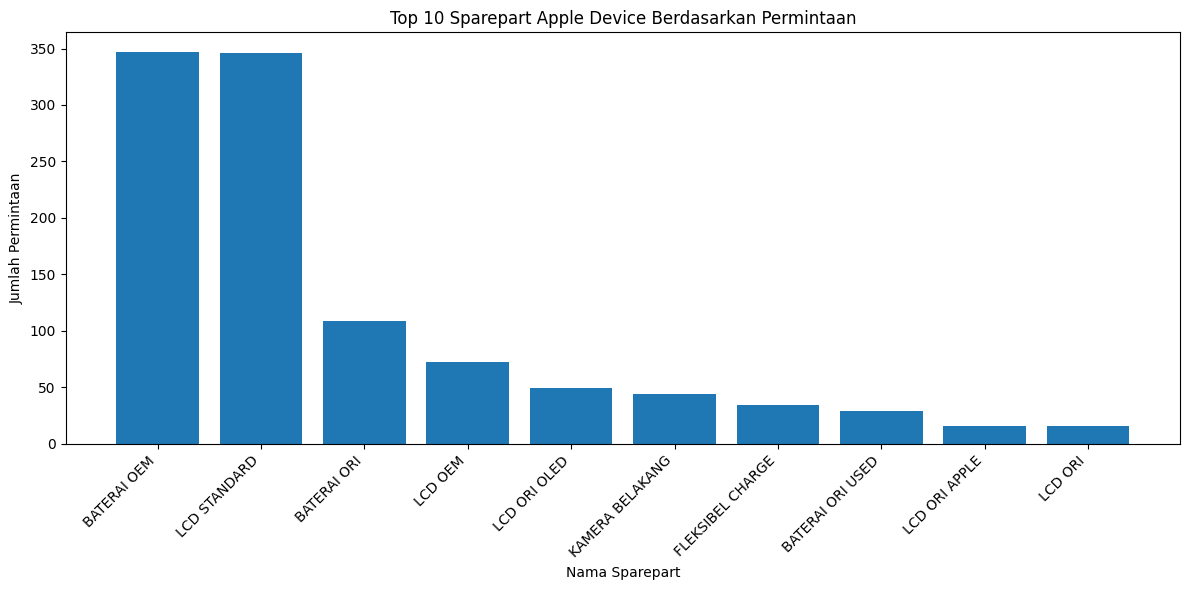

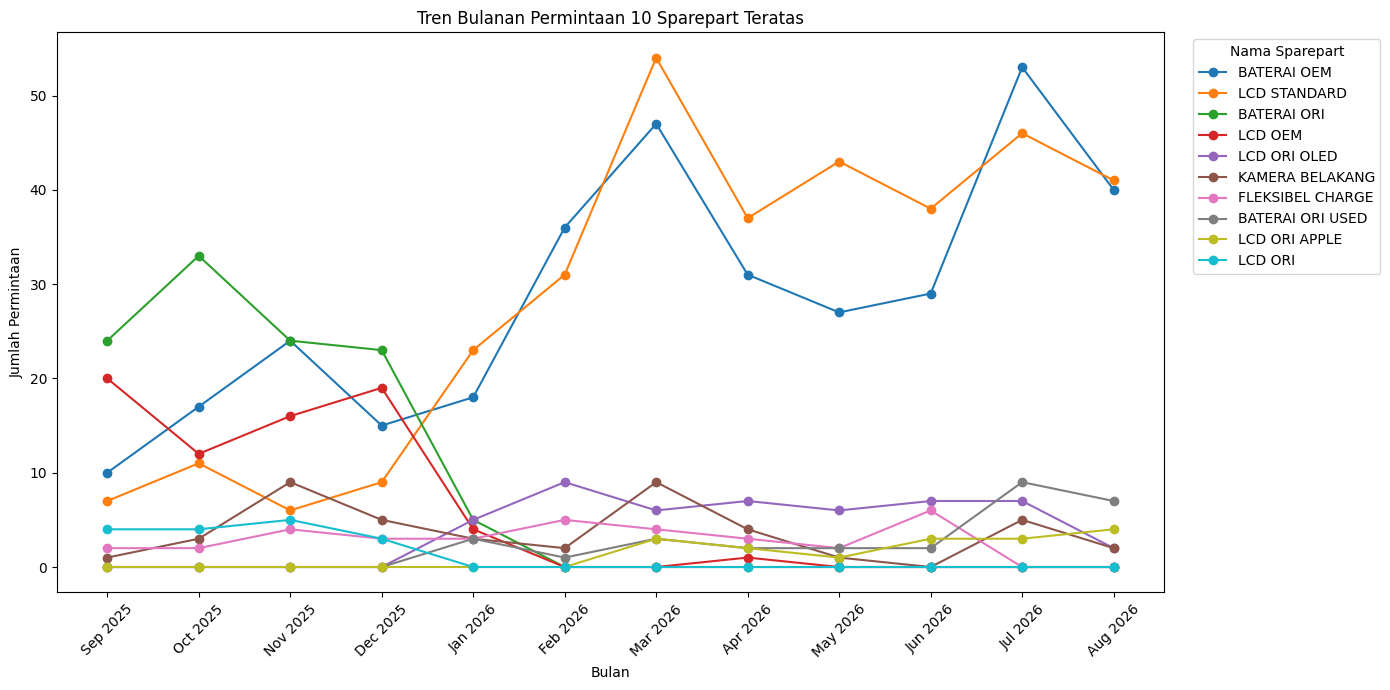

In [71]:

# TAHAP 52 - VISUALISASI TOP 10 DAN TREN BULANAN

import matplotlib.pyplot as plt

# VISUALISASI 1: TOP 10 SPAREPART
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_sparepart["Nama_Produk_Normalisasi"],
    top_10_sparepart["Jumlah_Permintaan"]
)

plt.title("Top 10 Sparepart Apple Device Berdasarkan Permintaan")
plt.xlabel("Nama Sparepart")
plt.ylabel("Jumlah Permintaan")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "03_top10_sparepart.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# VISUALISASI 2: TREN BULANAN TOP 10
plt.figure(figsize=(14, 7))

for produk in daftar_top10:

    plt.plot(
        tren_bulanan_top10.columns,
        tren_bulanan_top10.loc[produk],
        marker="o",
        label=produk
    )

plt.title("Tren Bulanan Permintaan 10 Sparepart Teratas")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Permintaan")
plt.xticks(rotation=45)
plt.legend(
    title="Nama Sparepart",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "04_tren_bulanan_top10.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [72]:

# TAHAP 53 - MEMBENTUK DATASET LOGISTIC REGRESSION

import pandas as pd
import numpy as np

# 1. Menentukan periode historis untuk pemilihan produk model
batas_pemilihan = pd.Period("2026-04", freq="M")

data_model_sumber = data_analisis.copy()

data_model_sumber["Bulan_Analisis"] = (
    data_model_sumber["Tanggal_Permintaan"].dt.to_period("M")
)

# 2. Memilih Top 10 berdasarkan data historis sampai April 2026
rekap_produk_model = (
    data_model_sumber[
        data_model_sumber["Bulan_Analisis"] <= batas_pemilihan
    ]
    .groupby("Nama_Produk_Normalisasi")
    ["ID_Kelompok_Pesanan"]
    .nunique()
    .sort_values(ascending=False)
)

top_10_model = rekap_produk_model.head(10).index.tolist()

print("TOP 10 PRODUK UNTUK MODEL:")
print(top_10_model)

# 3. Menghitung permintaan bulanan setiap produk
jumlah_bulanan = (
    data_model_sumber[
        data_model_sumber["Nama_Produk_Normalisasi"].isin(top_10_model)
    ]
    .groupby([
        "Nama_Produk_Normalisasi",
        "Bulan_Analisis"
    ])["ID_Kelompok_Pesanan"]
    .nunique()
)

# 4. Membuat kombinasi seluruh produk dan 12 bulan
indeks_lengkap = pd.MultiIndex.from_product(
    [top_10_model, daftar_bulan],
    names=["Nama_Produk_Normalisasi", "Bulan_Analisis"]
)

dataset_model = (
    jumlah_bulanan
    .reindex(indeks_lengkap, fill_value=0)
    .rename("Jumlah_Permintaan")
    .reset_index()
)

# 5. Mengurutkan data berdasarkan produk dan bulan
dataset_model = dataset_model.sort_values(
    ["Nama_Produk_Normalisasi", "Bulan_Analisis"]
).reset_index(drop=True)

# 6. Membuat fitur historis
group_produk = dataset_model.groupby("Nama_Produk_Normalisasi")

dataset_model["Permintaan_Bulan_Sebelumnya"] = (
    group_produk["Jumlah_Permintaan"].shift(1)
)

dataset_model["Rata_Rata_3_Bulan"] = (
    dataset_model.groupby("Nama_Produk_Normalisasi")
    ["Jumlah_Permintaan"]
    .transform(
        lambda x: x.rolling(window=3, min_periods=1).mean()
    )
)

# 7. Membuat target permintaan bulan berikutnya
permintaan_berikutnya = (
    dataset_model.groupby("Nama_Produk_Normalisasi")
    ["Jumlah_Permintaan"].shift(-1)
)

dataset_model["Bulan_Target"] = (
    dataset_model["Bulan_Analisis"] + 1
)

dataset_model["Target_Potensi"] = (
    permintaan_berikutnya.gt(0).astype("Int64")
)

dataset_model.loc[
    permintaan_berikutnya.isna(),
    "Target_Potensi"
] = pd.NA

# 8. Membuat fitur kalender
bulan_target = dataset_model["Bulan_Target"].dt.month

dataset_model["Bulan_Sin"] = np.sin(
    2 * np.pi * bulan_target / 12
)

dataset_model["Bulan_Cos"] = np.cos(
    2 * np.pi * bulan_target / 12
)

# 9. Mengambil data mulai Oktober 2025
#    September tidak digunakan karena belum mempunyai data bulan sebelumnya
dataset_model = dataset_model[
    (dataset_model["Bulan_Analisis"] >= pd.Period("2025-10", freq="M"))
    & (dataset_model["Target_Potensi"].notna())
].copy()

dataset_model["Target_Potensi"] = (
    dataset_model["Target_Potensi"].astype(int)
)

# 10. Membagi data berdasarkan waktu
dataset_model["Set_Data"] = np.where(
    dataset_model["Bulan_Target"] <= pd.Period("2026-04", freq="M"),
    "Train",
    "Test"
)

# 11. Menampilkan hasil
print("\nUKURAN DATASET MODEL:", dataset_model.shape)

print("\nDISTRIBUSI TARGET:")
print(dataset_model["Target_Potensi"].value_counts())

print("\nDISTRIBUSI TARGET BERDASARKAN DATA TRAIN DAN TEST:")
display(
    pd.crosstab(
        dataset_model["Set_Data"],
        dataset_model["Target_Potensi"]
    )
)

print("\nCONTOH DATASET LOGISTIC REGRESSION:")
display(dataset_model.head(20))


TOP 10 PRODUK UNTUK MODEL:
['BATERAI OEM', 'LCD STANDARD', 'BATERAI ORI', 'LCD OEM', 'KAMERA BELAKANG', 'LCD ORI OLED', 'FLEKSIBEL CHARGE', 'LCD ORI', 'SPEAKER ATAS', 'BATERAI ORI USED']

UKURAN DATASET MODEL: (100, 10)

DISTRIBUSI TARGET:
Target_Potensi
1    68
0    32
Name: count, dtype: int64

DISTRIBUSI TARGET BERDASARKAN DATA TRAIN DAN TEST:


Target_Potensi,0,1
Set_Data,,
Test,16,24
Train,16,44



CONTOH DATASET LOGISTIC REGRESSION:


,Nama_Produk_Normalisasi,Bulan_Analisis,Jumlah_Permintaan,Permintaan_Bulan_Sebelumnya,Rata_Rata_3_Bulan,Bulan_Target,Target_Potensi,Bulan_Sin,Bulan_Cos,Set_Data
1,BATERAI OEM,2025-10,17,10.0,13.500000,2025-11,1,-5.000000e-01,8.660254e-01,Train
2,BATERAI OEM,2025-11,24,17.0,17.000000,2025-12,1,-2.449294e-16,1.000000e+00,Train
3,BATERAI OEM,2025-12,15,24.0,18.666667,2026-01,1,5.000000e-01,8.660254e-01,Train
4,BATERAI OEM,2026-01,18,15.0,19.000000,2026-02,1,8.660254e-01,5.000000e-01,Train
5,BATERAI OEM,2026-02,36,18.0,23.000000,2026-03,1,1.000000e+00,6.123234e-17,Train
6,BATERAI OEM,2026-03,47,36.0,33.666667,2026-04,1,8.660254e-01,-5.000000e-01,Train
7,BATERAI OEM,2026-04,31,47.0,38.000000,2026-05,1,5.000000e-01,-8.660254e-01,Test
8,BATERAI OEM,2026-05,27,31.0,35.000000,2026-06,1,1.224647e-16,-1.000000e+00,Test
9,BATERAI OEM,2026-06,29,27.0,29.000000,2026-07,1,-5.000000e-01,-8.660254e-01,Test
10,BATERAI OEM,2026-07,53,29.0,36.333333,2026-08,1,-8.660254e-01,-5.000000e-01,Test


In [73]:

# TAHAP 54 - PEMODELAN LOGISTIC REGRESSION

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 1. Memisahkan data training dan testing
data_train = dataset_model[
    dataset_model["Set_Data"] == "Train"
].copy()

data_test = dataset_model[
    dataset_model["Set_Data"] == "Test"
].copy()

# 2. Menentukan fitur prediksi
fitur_numerik = [
    "Jumlah_Permintaan",
    "Permintaan_Bulan_Sebelumnya",
    "Rata_Rata_3_Bulan",
    "Bulan_Sin",
    "Bulan_Cos"
]

fitur_kategori = [
    "Nama_Produk_Normalisasi"
]

semua_fitur = fitur_numerik + fitur_kategori

target = "Target_Potensi"

# 3. Memisahkan variabel X dan y
X_train = data_train[semua_fitur]
y_train = data_train[target]

X_test = data_test[semua_fitur]
y_test = data_test[target]

# 4. Membuat preprocessing fitur
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerik",
            StandardScaler(),
            fitur_numerik
        ),
        (
            "kategori",
            OneHotEncoder(handle_unknown="ignore"),
            fitur_kategori
        )
    ]
)

# 5. Membuat pipeline Logistic Regression
model_logreg = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "klasifikasi",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# 6. Melatih model
model_logreg.fit(X_train, y_train)

print("MODEL LOGISTIC REGRESSION BERHASIL DILATIH")

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nDistribusi target training:")
print(y_train.value_counts())

print("\nDistribusi target testing:")
print(y_test.value_counts())


MODEL LOGISTIC REGRESSION BERHASIL DILATIH

Jumlah data training: 60
Jumlah data testing: 40

Distribusi target training:
Target_Potensi
1    44
0    16
Name: count, dtype: int64

Distribusi target testing:
Target_Potensi
1    24
0    16
Name: count, dtype: int64


In [74]:

# TAHAP 55 - PREDIKSI DAN EVALUASI MODEL

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

THRESHOLD_FINAL = 0.20

y_prob = model_logreg.predict_proba(X_test)[:, 1]

y_pred = (y_prob >= THRESHOLD_FINAL).astype(int)

# 3. Menghitung metrik evaluasi
akurasi = accuracy_score(y_test, y_pred)

presisi = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

auc = roc_auc_score(y_test, y_prob)

# 4. Menampilkan hasil evaluasi
hasil_evaluasi = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Nilai": [
        akurasi,
        presisi,
        recall,
        f1,
        auc
    ]
})

print("HASIL EVALUASI LOGISTIC REGRESSION")
display(hasil_evaluasi)

# 5. Menampilkan classification report
print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Tidak Ada Potensi",
            "Ada Potensi"
        ],
        zero_division=0
    )
)

# 6. Membuat confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

tabel_cm = pd.DataFrame(
    cm,
    index=["Aktual 0", "Aktual 1"],
    columns=["Prediksi 0", "Prediksi 1"]
)

print("\nCONFUSION MATRIX:")
display(tabel_cm)

# 7. Membuat tabel hasil prediksi
hasil_prediksi = data_test[
    [
        "Nama_Produk_Normalisasi",
        "Bulan_Target",
        "Target_Potensi"
    ]
].copy()

hasil_prediksi["Hasil_Prediksi"] = y_pred
hasil_prediksi["Probabilitas_Potensi"] = y_prob

hasil_prediksi["Keterangan_Prediksi"] = np.where(
    hasil_prediksi["Hasil_Prediksi"] == 1,
    "Ada Potensi",
    "Tidak Ada Potensi"
)

print("\nDETAIL HASIL PREDIKSI:")
display(hasil_prediksi.reset_index(drop=True))


HASIL EVALUASI LOGISTIC REGRESSION


,Metrik,Nilai
0,Accuracy,0.825000
1,Precision,0.840000
2,Recall,0.875000
3,F1-Score,0.857143
4,ROC-AUC,0.895833



CLASSIFICATION REPORT:
                   precision    recall  f1-score   support

Tidak Ada Potensi       0.80      0.75      0.77        16
      Ada Potensi       0.84      0.88      0.86        24

         accuracy                           0.82        40
        macro avg       0.82      0.81      0.82        40
     weighted avg       0.82      0.82      0.82        40


CONFUSION MATRIX:


,Prediksi 0,Prediksi 1
Aktual 0,12,4
Aktual 1,3,21



DETAIL HASIL PREDIKSI:


,Nama_Produk_Normalisasi,Bulan_Target,Target_Potensi,Hasil_Prediksi,Probabilitas_Potensi,Keterangan_Prediksi
0,BATERAI OEM,2026-05,1,1,0.979826,Ada Potensi
1,BATERAI OEM,2026-06,1,1,0.962054,Ada Potensi
2,BATERAI OEM,2026-07,1,1,0.967460,Ada Potensi
3,BATERAI OEM,2026-08,1,1,0.999546,Ada Potensi
4,BATERAI ORI,2026-05,0,0,0.116622,Tidak Ada Potensi
...,...,...,...,...,...,...
35,LCD STANDARD,2026-08,1,1,0.998492,Ada Potensi
36,SPEAKER ATAS,2026-05,0,0,0.186584,Tidak Ada Potensi
37,SPEAKER ATAS,2026-06,1,0,0.148340,Tidak Ada Potensi
38,SPEAKER ATAS,2026-07,1,0,0.137607,Tidak Ada Potensi


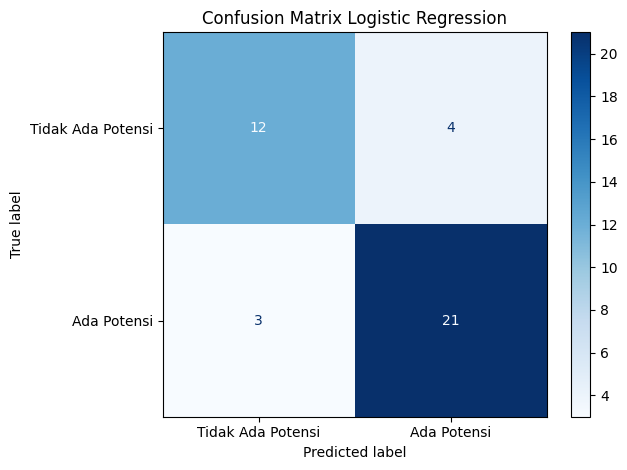

In [75]:

# TAHAP 56 - VISUALISASI CONFUSION MATRIX

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Tidak Ada Potensi",
        "Ada Potensi"
    ]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix Logistic Regression")
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "05_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [76]:
# TAHAP 57 - ANALISIS THRESHOLD LOGISTIC REGRESSION

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Membagi data training menjadi data pengembangan dan validasi
data_dev = data_train[
    data_train["Bulan_Target"] <= pd.Period("2026-02", freq="M")
].copy()

data_validasi = data_train[
    data_train["Bulan_Target"] > pd.Period("2026-02", freq="M")
].copy()

X_dev = data_dev[semua_fitur]
y_dev = data_dev[target]

X_validasi = data_validasi[semua_fitur]
y_validasi = data_validasi[target]

print("Data pengembangan:", len(X_dev))
print("Data validasi:", len(X_validasi))

print("\nDistribusi target validasi:")
print(y_validasi.value_counts())

# 2. Melatih model sementara untuk validasi threshold
model_validasi = clone(model_logreg)
model_validasi.fit(X_dev, y_dev)

prob_validasi = model_validasi.predict_proba(
    X_validasi
)[:, 1]

# 3. Menguji beberapa threshold
daftar_threshold = [0.20, 0.30, 0.40, 0.50, 0.60]

hasil_threshold = []

for threshold in daftar_threshold:

    prediksi_validasi = (
        prob_validasi >= threshold
    ).astype(int)

    hasil_threshold.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_validasi, prediksi_validasi
        ),
        "Precision": precision_score(
            y_validasi, prediksi_validasi,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validasi, prediksi_validasi,
            zero_division=0
        ),
        "F1_Score": f1_score(
            y_validasi, prediksi_validasi,
            zero_division=0
        )
    })

tabel_threshold = pd.DataFrame(hasil_threshold)

print("\nHASIL PENGUJIAN THRESHOLD PADA DATA VALIDASI:")
display(tabel_threshold)

# 4. Menetapkan threshold final berdasarkan tujuan penelitian
THRESHOLD_FINAL = 0.20

print("\nThreshold final yang digunakan:", THRESHOLD_FINAL)

# 5. Menguji threshold final pada data testing
prob_test = model_logreg.predict_proba(X_test)[:, 1]

prediksi_threshold_test = (
    prob_test >= THRESHOLD_FINAL
).astype(int)

print("\nEVALUASI DATA TEST DENGAN THRESHOLD FINAL")

print("Accuracy:",
      accuracy_score(y_test, prediksi_threshold_test))

print("Precision:",
      precision_score(
          y_test, prediksi_threshold_test,
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test, prediksi_threshold_test,
          zero_division=0
      ))

print("F1-Score:",
      f1_score(
          y_test, prediksi_threshold_test,
          zero_division=0
      ))

Data pengembangan: 40
Data validasi: 20

Distribusi target validasi:
Target_Potensi
1    14
0     6
Name: count, dtype: int64

HASIL PENGUJIAN THRESHOLD PADA DATA VALIDASI:


,Threshold,Accuracy,Precision,Recall,F1_Score
0,0.2,0.80,0.777778,1.000000,0.875000
1,0.3,0.80,0.916667,0.785714,0.846154
2,0.4,0.75,1.000000,0.642857,0.782609
3,0.5,0.75,1.000000,0.642857,0.782609
4,0.6,0.70,1.000000,0.571429,0.727273



Threshold final yang digunakan: 0.2

EVALUASI DATA TEST DENGAN THRESHOLD FINAL
Accuracy: 0.825
Precision: 0.84
Recall: 0.875
F1-Score: 0.8571428571428571


pada threshold 0,20, confusion matrix menunjukkan 12 data negatif diprediksi benar, 4 prediksi positif yang sebenarnya negatif, 21 data positif diprediksi benar, dan 3 data positif terlewat. Nilai Recall sebesar 87,50% menunjukkan model berhasil mendeteksi 21 dari 24 data positif pada pengujian.

In [77]:

# TAHAP 58 - EVALUASI FINAL LOGISTIC REGRESSION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Menetapkan threshold berdasarkan data validasi
THRESHOLD_FINAL = 0.20

# 2. Menghitung probabilitas pada data testing
probabilitas_final = model_logreg.predict_proba(X_test)[:, 1]

# 3. Menentukan hasil prediksi menggunakan threshold 0.20
prediksi_final = (
    probabilitas_final >= THRESHOLD_FINAL
).astype(int)

# 4. Menghitung metrik evaluasi
hasil_evaluasi_final = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Nilai": [
        accuracy_score(y_test, prediksi_final),
        precision_score(y_test, prediksi_final, zero_division=0),
        recall_score(y_test, prediksi_final, zero_division=0),
        f1_score(y_test, prediksi_final, zero_division=0),
        roc_auc_score(y_test, probabilitas_final)
    ]
})

print("THRESHOLD FINAL:", THRESHOLD_FINAL)
print("\nHASIL EVALUASI FINAL:")
display(hasil_evaluasi_final)

# 5. Menampilkan classification report
print("\nCLASSIFICATION REPORT FINAL:")

print(
    classification_report(
        y_test,
        prediksi_final,
        labels=[0, 1],
        target_names=[
            "Tidak Ada Potensi",
            "Ada Potensi"
        ],
        zero_division=0
    )
)

# 6. Membuat confusion matrix final
cm_final = confusion_matrix(
    y_test,
    prediksi_final,
    labels=[0, 1]
)

tabel_cm_final = pd.DataFrame(
    cm_final,
    index=["Aktual 0", "Aktual 1"],
    columns=["Prediksi 0", "Prediksi 1"]
)

print("\nCONFUSION MATRIX FINAL:")
display(tabel_cm_final)

# 7. Menyimpan detail prediksi final
hasil_prediksi_final = data_test[
    [
        "Nama_Produk_Normalisasi",
        "Bulan_Target",
        "Target_Potensi"
    ]
].copy()

hasil_prediksi_final["Probabilitas_Potensi"] = probabilitas_final
hasil_prediksi_final["Hasil_Prediksi"] = prediksi_final

hasil_prediksi_final["Keterangan_Prediksi"] = np.where(
    prediksi_final == 1,
    "Ada Potensi",
    "Tidak Ada Potensi"
)

print("\nDETAIL PREDIKSI FINAL:")
display(hasil_prediksi_final.reset_index(drop=True))


THRESHOLD FINAL: 0.2

HASIL EVALUASI FINAL:


,Metrik,Nilai
0,Accuracy,0.825000
1,Precision,0.840000
2,Recall,0.875000
3,F1-Score,0.857143
4,ROC-AUC,0.895833



CLASSIFICATION REPORT FINAL:
                   precision    recall  f1-score   support

Tidak Ada Potensi       0.80      0.75      0.77        16
      Ada Potensi       0.84      0.88      0.86        24

         accuracy                           0.82        40
        macro avg       0.82      0.81      0.82        40
     weighted avg       0.82      0.82      0.82        40


CONFUSION MATRIX FINAL:


,Prediksi 0,Prediksi 1
Aktual 0,12,4
Aktual 1,3,21



DETAIL PREDIKSI FINAL:


,Nama_Produk_Normalisasi,Bulan_Target,Target_Potensi,Probabilitas_Potensi,Hasil_Prediksi,Keterangan_Prediksi
0,BATERAI OEM,2026-05,1,0.979826,1,Ada Potensi
1,BATERAI OEM,2026-06,1,0.962054,1,Ada Potensi
2,BATERAI OEM,2026-07,1,0.967460,1,Ada Potensi
3,BATERAI OEM,2026-08,1,0.999546,1,Ada Potensi
4,BATERAI ORI,2026-05,0,0.116622,0,Tidak Ada Potensi
...,...,...,...,...,...,...
35,LCD STANDARD,2026-08,1,0.998492,1,Ada Potensi
36,SPEAKER ATAS,2026-05,0,0.186584,0,Tidak Ada Potensi
37,SPEAKER ATAS,2026-06,1,0.148340,0,Tidak Ada Potensi
38,SPEAKER ATAS,2026-07,1,0.137607,0,Tidak Ada Potensi


In [78]:

# TAHAP 59 - PREDIKSI POTENSI PERMINTAAN SEPTEMBER 2026

from sklearn.base import clone
import numpy as np
import pandas as pd

# 1. Melatih ulang model menggunakan seluruh data berlabel
model_final = clone(model_logreg)

model_final.fit(
    dataset_model[semua_fitur],
    dataset_model["Target_Potensi"]
)

# 2. Menyiapkan histori permintaan setiap produk
histori_final = (
    data_model_sumber[
        data_model_sumber["Nama_Produk_Normalisasi"].isin(top_10_model)
    ]
    .groupby(
        ["Nama_Produk_Normalisasi", "Bulan_Analisis"]
    )["ID_Kelompok_Pesanan"]
    .nunique()
    .reindex(indeks_lengkap, fill_value=0)
    .rename("Jumlah_Permintaan")
    .reset_index()
    .sort_values(
        ["Nama_Produk_Normalisasi", "Bulan_Analisis"]
    )
)

# 3. Membuat fitur historis
grup = histori_final.groupby("Nama_Produk_Normalisasi")

histori_final["Permintaan_Bulan_Sebelumnya"] = (
    grup["Jumlah_Permintaan"].shift(1)
)

histori_final["Rata_Rata_3_Bulan"] = (
    histori_final.groupby("Nama_Produk_Normalisasi")
    ["Jumlah_Permintaan"]
    .transform(
        lambda x: x.rolling(3, min_periods=1).mean()
    )
)

# 4. Mengambil data bulan Agustus 2026
data_prediksi = histori_final[
    histori_final["Bulan_Analisis"] == pd.Period("2026-08", freq="M")
].copy()

# 5. Membentuk fitur target September 2026
bulan_prediksi = pd.Period("2026-09", freq="M")

data_prediksi["Bulan_Sin"] = np.sin(
    2 * np.pi * bulan_prediksi.month / 12
)

data_prediksi["Bulan_Cos"] = np.cos(
    2 * np.pi * bulan_prediksi.month / 12
)

# 6. Memastikan fitur lengkap
data_prediksi[fitur_numerik] = (
    data_prediksi[fitur_numerik].fillna(0)
)

X_prediksi_final = data_prediksi[semua_fitur]

# 7. Menghitung probabilitas dan prediksi
probabilitas = model_final.predict_proba(
    X_prediksi_final
)[:, 1]

prediksi = (
    probabilitas >= THRESHOLD_FINAL
).astype(int)

# 8. Membuat tabel hasil
hasil_prediksi_september = pd.DataFrame({
    "Nama_Sparepart": data_prediksi[
        "Nama_Produk_Normalisasi"
    ].values,
    "Bulan_Prediksi": "September 2026",
    "Permintaan_Agustus": data_prediksi[
        "Jumlah_Permintaan"
    ].values,
    "Probabilitas_Model": probabilitas,
    "Prediksi_Potensi": prediksi
})

hasil_prediksi_september["Keterangan"] = np.where(
    hasil_prediksi_september["Prediksi_Potensi"] == 1,
    "Ada Potensi",
    "Tidak Ada Potensi"
)

hasil_prediksi_september = (
    hasil_prediksi_september
    .sort_values("Probabilitas_Model", ascending=False)
    .reset_index(drop=True)
)

print("HASIL PREDIKSI POTENSI PERMINTAAN SEPTEMBER 2026")
display(hasil_prediksi_september)


HASIL PREDIKSI POTENSI PERMINTAAN SEPTEMBER 2026


,Nama_Sparepart,Bulan_Prediksi,Permintaan_Agustus,Probabilitas_Model,Prediksi_Potensi,Keterangan
0,LCD STANDARD,September 2026,41,0.999440,1,Ada Potensi
1,BATERAI OEM,September 2026,40,0.999024,1,Ada Potensi
2,BATERAI ORI USED,September 2026,7,0.696096,1,Ada Potensi
3,KAMERA BELAKANG,September 2026,2,0.510881,1,Ada Potensi
4,LCD ORI OLED,September 2026,2,0.426458,1,Ada Potensi
5,FLEKSIBEL CHARGE,September 2026,0,0.349881,1,Ada Potensi
6,SPEAKER ATAS,September 2026,2,0.312578,1,Ada Potensi
7,LCD OEM,September 2026,0,0.101002,0,Tidak Ada Potensi
8,LCD ORI,September 2026,0,0.091199,0,Tidak Ada Potensi
9,BATERAI ORI,September 2026,0,0.060928,0,Tidak Ada Potensi


dari 10 sparepart yg diuji, ada 7 yang diprediksi berpotensi dan 3 tidak ada potensinya yang di mana di sini LEKSIBEL CHARGE tetap diprediksi berpotensi walaupun permintaan Agustus tercatat nol. Alasannya, probabilitas 34,99% masih melewati threshold 20%. Jadi, prediksi positif tidak selalu berarti permintaannya tinggi.

In [84]:
# TAHAP 60 - MENYIMPAN SELURUH HASIL PENELITIAN

from pathlib import Path
import pandas as pd
import joblib

# 1. Membuat folder hasil akhir
folder_hasil = Path(BASE_DIR) / "hasil_akhir"
folder_hasil.mkdir(parents=True, exist_ok=True)

# 2. Ringkasan filter data
ringkasan_filter = pd.DataFrame({
    "Keterangan": [
        "Total kelompok awal",
        "Kelompok permintaan utama",
        "Kelompok dikecualikan"
    ],
    "Jumlah": [
        len(df_permintaan),
        len(df_permintaan_utama),
        len(df_permintaan_dikecualikan)
    ]
})

# 3. Menyiapkan tabel hasil penelitian
daftar_hasil = {
    "00_Ringkasan_Filter": ringkasan_filter,
    "01_Mapping_Sparepart": mapping_sparepart,
    "02_Transaksi_Sparepart": df_transaksi_sparepart,
    "03_Calon_Pasangan_DP": hasil_link_dp_otomatis,
    "04_Link_DP_Final": link_produk_dp_otomatis,
    "05_Ringkasan_DP": ringkasan_link_dp,
    "06_Data_Permintaan_Final": df_permintaan_utama,
    "07_Data_Permintaan_Semua_Status": df_permintaan,
    "08_Data_Dikecualikan": df_permintaan_dikecualikan,
    "09_Top10_Sparepart": top_10_sparepart,
    "10_Tren_Bulanan": tren_bulanan_top10.reset_index(),
    "11_Rekap_Bulanan": rekap_bulanan,
    "12_Dataset_Logistic_Regression": dataset_model,
    "13_Evaluasi_Final": hasil_evaluasi_final,
    "14_Confusion_Matrix": tabel_cm_final.rename_axis(
        "Aktual"
    ).reset_index(),
    "15_Prediksi_Test": hasil_prediksi_final,
    "16_Prediksi_September_2026": hasil_prediksi_september,
    "17_Hasil_Uji_Threshold": tabel_threshold
}

# 4. Menyimpan setiap tabel sebagai CSV
berhasil_disimpan = []

for nama_file, tabel in daftar_hasil.items():

    if isinstance(tabel, pd.DataFrame):

        lokasi_file = folder_hasil / f"{nama_file}.csv"

        tabel.to_csv(
            lokasi_file,
            index=False,
            encoding="utf-8-sig"
        )

        berhasil_disimpan.append(lokasi_file.name)

# 5. Menyimpan model final
joblib.dump(
    model_final,
    folder_hasil / "Model_Logistic_Regression.joblib"
)

# 6. Mengambil nilai evaluasi secara otomatis
nilai_metrik = dict(
    zip(
        hasil_evaluasi_final["Metrik"],
        hasil_evaluasi_final["Nilai"]
    )
)

# 7. Menyimpan informasi metodologi
with open(
    folder_hasil / "Informasi_Model.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write("HASIL PENELITIAN PT X\n")
    file.write("Metode: Logistic Regression\n")
    file.write("Periode: September 2025 - Agustus 2026\n")
    file.write(f"Threshold final: {THRESHOLD_FINAL}\n")
    file.write(f"Accuracy: {nilai_metrik['Accuracy']:.4f}\n")
    file.write(f"Precision: {nilai_metrik['Precision']:.4f}\n")
    file.write(f"Recall: {nilai_metrik['Recall']:.4f}\n")
    file.write(f"F1-Score: {nilai_metrik['F1-Score']:.4f}\n")
    file.write(f"ROC-AUC: {nilai_metrik['ROC-AUC']:.4f}\n")

print("PENYIMPANAN BERHASIL")
print("Lokasi:", folder_hasil.resolve())

for nama in berhasil_disimpan:
    print("Berhasil:", nama)

print("Model: Model_Logistic_Regression.joblib")

PENYIMPANAN BERHASIL
Lokasi: D:\perkuliahan\semester5\Penambangan Data(jumat siang)\Project_Final\hasil_akhir
Berhasil: 00_Ringkasan_Filter.csv
Berhasil: 01_Mapping_Sparepart.csv
Berhasil: 02_Transaksi_Sparepart.csv
Berhasil: 03_Calon_Pasangan_DP.csv
Berhasil: 04_Link_DP_Final.csv
Berhasil: 05_Ringkasan_DP.csv
Berhasil: 06_Data_Permintaan_Final.csv
Berhasil: 07_Data_Permintaan_Semua_Status.csv
Berhasil: 08_Data_Dikecualikan.csv
Berhasil: 09_Top10_Sparepart.csv
Berhasil: 10_Tren_Bulanan.csv
Berhasil: 11_Rekap_Bulanan.csv
Berhasil: 12_Dataset_Logistic_Regression.csv
Berhasil: 13_Evaluasi_Final.csv
Berhasil: 14_Confusion_Matrix.csv
Berhasil: 15_Prediksi_Test.csv
Berhasil: 16_Prediksi_September_2026.csv
Berhasil: 17_Hasil_Uji_Threshold.csv
Model: Model_Logistic_Regression.joblib


In [85]:

# TAHAP 61 - BACKUP SELURUH TABEL PENELITIAN

from pathlib import Path
import pandas as pd
import joblib

folder_hasil = Path(BASE_DIR) / "hasil_akhir"
folder_hasil.mkdir(parents=True, exist_ok=True)

# Seluruh tabel penting penelitian
arsip = {
    "Data_Preprocessing": df_preprocess,
    "Data_Kandidat": df_kandidat,
    "Normalisasi_Auto": template_normalisasi_auto,
    "Normalisasi_DP": hasil_normalisasi_dp,
    "Mapping_Sparepart": mapping_sparepart,
    "Transaksi_Sparepart": df_transaksi_sparepart,
    "Review_Link_DP": review_link_dp,
    "Ringkasan_DP": ringkasan_link_dp,
    "Skor_Pencocokan_DP": hasil_link_dp_otomatis,
    "Link_Produk_DP": link_produk_dp_otomatis,

    "Data_Permintaan_Final": df_permintaan_utama,
    "Data_Permintaan_Semua": df_permintaan,
    "Data_Dikecualikan": df_permintaan_dikecualikan,

    "Top10_Sparepart": top_10_sparepart,
    "Tren_Bulanan": tren_bulanan_top10.reset_index(),
    "Rekap_Bulanan": rekap_bulanan,
    "Dataset_Model": dataset_model,
    "Evaluasi_Final": hasil_evaluasi_final,
    "Confusion_Matrix": tabel_cm_final.reset_index(),
    "Prediksi_Test": hasil_prediksi_final,
    "Prediksi_Sep2026": hasil_prediksi_september,
    "Uji_Threshold": tabel_threshold
}

# Menyimpan seluruh tabel dalam satu workbook Excel
file_arsip = folder_hasil / "Arsip_Lengkap_Penelitian.xlsx"

with pd.ExcelWriter(
    file_arsip,
    engine="openpyxl"
) as writer:

    for nama, tabel in arsip.items():

        tabel_simpan = tabel.copy()

        # Mengubah tipe Period agar kompatibel dengan Excel
        for kolom in tabel_simpan.columns:
            if isinstance(
                tabel_simpan[kolom].dtype,
                pd.PeriodDtype
            ):
                tabel_simpan[kolom] = (
                    tabel_simpan[kolom].astype(str)
                )

        tabel_simpan.to_excel(
            writer,
            sheet_name=nama[:31],
            index=False
        )

# Menyimpan ulang model final
joblib.dump(
    model_final,
    folder_hasil / "Model_Logistic_Regression.joblib"
)

# Menyimpan catatan metodologi dan keterbatasan
nilai_metrik = dict(
    zip(
        hasil_evaluasi_final["Metrik"],
        hasil_evaluasi_final["Nilai"]
    )
)

with open(
    folder_hasil / "CATATAN_PENELITIAN.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write("PROYEK PENELITIAN PT X\n")
    file.write("Metode: Logistic Regression\n")
    file.write("Periode: September 2025 - Agustus 2026\n")
    file.write(f"Threshold final: {THRESHOLD_FINAL}\n")
    file.write(f"Accuracy: {nilai_metrik['Accuracy']:.4f}\n")
    file.write(f"Precision: {nilai_metrik['Precision']:.4f}\n")
    file.write(f"Recall: {nilai_metrik['Recall']:.4f}\n")
    file.write(f"F1-Score: {nilai_metrik['F1-Score']:.4f}\n")
    file.write(f"ROC-AUC: {nilai_metrik['ROC-AUC']:.4f}\n\n")

    file.write("CATATAN KETERBATASAN:\n")
    file.write("- 32 hubungan produk DP tertaut secara otomatis.\n")
    file.write("- 19 transaksi DP belum tertaut otomatis.\n")
    file.write("- Tautan otomatis belum diverifikasi manual seluruhnya.\n")
    file.write("- Prediksi September 2026 merupakan simulasi berdasarkan data sampai Agustus 2026.\n")

In [81]:

# TAHAP 62 - AUDIT DATA PENJUALAN TEREALISASI

import pandas as pd
import numpy as np

# 1. Mengambil transaksi berstatus PAID
df_paid = df_transaksi_sparepart[
    df_transaksi_sparepart["Status_Bersih"]
    .astype(str).str.strip().str.upper() == "PAID"
].copy()

# 2. Menghapus pengulangan produk dalam ID transaksi yang sama
df_paid = df_paid.drop_duplicates(
    subset=[
        "ID_Transaksi",
        "Nama_Produk_Normalisasi"
    ]
).copy()

print("AUDIT PENJUALAN PAID")
print("Jumlah baris produk PAID:", len(df_paid))
print("Jumlah ID PAID:", df_paid["ID_Transaksi"].nunique())
print("Jumlah produk normalisasi:",
      df_paid["Nama_Produk_Normalisasi"].nunique())

# 3. Memeriksa kategori produk pada transaksi PAID
print("\nKATEGORI PRODUK PAID:")

display(
    df_paid.groupby("Kategori_Produk")
    .agg(
        Jumlah_Baris=("ID_Transaksi", "size"),
        Jumlah_ID=("ID_Transaksi", "nunique")
    )
    .reset_index()
)

# 4. Memeriksa transaksi PAID yang komponen aslinya diawali DP
mask_dp = (
    df_paid["Komponen_Kandidat"]
    .astype(str)
    .str.match(r"^\s*DP\b", case=False)
)

paid_dengan_awalan_dp = df_paid[mask_dp].copy()

print("\nPAID DENGAN KOMPONEN BERAWALAN DP:")
print("Jumlah baris:", len(paid_dengan_awalan_dp))
print("Jumlah ID:", paid_dengan_awalan_dp["ID_Transaksi"].nunique())

display(
    paid_dengan_awalan_dp[
        [
            "ID_Transaksi",
            "Tanggal_Diperbaiki",
            "Payment Date",
            "Name",
            "Device",
            "Description",
            "Komponen_Kandidat",
            "Nama_Produk_Normalisasi",
            "Amount"
        ]
    ].head(30)
)

# 5. Memeriksa kualitas tanggal pembayaran
audit_tanggal = (
    df_paid[
        [
            "ID_Transaksi",
            "Tanggal_Diperbaiki",
            "Payment Date"
        ]
    ]
    .drop_duplicates("ID_Transaksi")
    .copy()
)

audit_tanggal["Tanggal_Diperbaiki"] = pd.to_datetime(
    audit_tanggal["Tanggal_Diperbaiki"],
    errors="coerce"
)

audit_tanggal["Tanggal_Pembayaran"] = pd.to_datetime(
    audit_tanggal["Payment Date"],
    errors="coerce",
    dayfirst=True
)

print("\nPEMERIKSAAN TANGGAL PEMBAYARAN")
print(
    "Total ID PAID:",
    len(audit_tanggal)
)

print(
    "Tanggal pembayaran tersedia:",
    audit_tanggal["Tanggal_Pembayaran"].notna().sum()
)

print(
    "Tanggal pembayaran kosong:",
    audit_tanggal["Tanggal_Pembayaran"].isna().sum()
)

print(
    "Rentang tanggal pembayaran:",
    audit_tanggal["Tanggal_Pembayaran"].min(),
    "sampai",
    audit_tanggal["Tanggal_Pembayaran"].max()
)

# 6. Menampilkan contoh tanggal yang kosong
print("\nCONTOH PAID TANPA TANGGAL PEMBAYARAN:")

display(
    audit_tanggal[
        audit_tanggal["Tanggal_Pembayaran"].isna()
    ].head(15)
)


AUDIT PENJUALAN PAID
Jumlah baris produk PAID: 1219
Jumlah ID PAID: 1117
Jumlah produk normalisasi: 67

KATEGORI PRODUK PAID:


,Kategori_Produk,Jumlah_Baris,Jumlah_ID
0,Perlu Konfirmasi - DP,2,2
1,Sparepart - Sementara,1217,1115



PAID DENGAN KOMPONEN BERAWALAN DP:
Jumlah baris: 2
Jumlah ID: 2


,ID_Transaksi,Tanggal_Diperbaiki,Payment Date,Name,Device,Description,Komponen_Kandidat,Nama_Produk_Normalisasi,Amount
707,Sumber_01.xlsx|MARET|166,2026-03-29,2026-03-29 00:00:00,P0724,iPhone 13,DP Lcd Ori Apple,DP LCD ORI APPLE,LCD ORI APPLE,2500000.0
1019,Sumber_02.xlsx|Juli|8,2026-07-02,2026-07-02 00:00:00,P0920,iPhone 14 Pro,DP Baterai Ori Used,DP BATERAI ORI USED,BATERAI ORI USED,500000.0



PEMERIKSAAN TANGGAL PEMBAYARAN
Total ID PAID: 1117
Tanggal pembayaran tersedia: 1115
Tanggal pembayaran kosong: 2
Rentang tanggal pembayaran: 2025-09-01 00:00:00 sampai 2026-08-31 00:00:00

CONTOH PAID TANPA TANGGAL PEMBAYARAN:


,ID_Transaksi,Tanggal_Diperbaiki,Payment Date,Tanggal_Pembayaran
999,Sumber_02.xlsx|Juni|120,2026-06-27,NaN,NaT
1167,Sumber_02.xlsx|Agustus|3,2026-08-01,NaN,NaT


In [82]:
# TAHAP 63 - Mengurutkan DP, DONE, PAID, dan CICILAN

import pandas as pd
import numpy as np

# Status dinormalisasi agar konsisten
data_status = df_transaksi_event.copy()
data_status["Status_Bersih"] = (
    data_status["Status_Bersih"]
    .fillna("TIDAK DIKETAHUI")
    .astype(str).str.strip().str.upper()
)

# 1. Ringkasan setiap status berdasarkan baris transaksi-produk
rekap_status_detail = (
    data_status.groupby("Status_Bersih")
    .agg(
        Jumlah_Baris_Transaksi_Produk=("ID_Transaksi", "size"),
        Jumlah_ID_Transaksi_Unik=("ID_Transaksi", "nunique"),
        Jumlah_Kelompok_Permintaan=("ID_Kelompok_Pesanan", "nunique"),
        Jumlah_Produk_Unik=("Nama_Produk_Normalisasi", "nunique")
    )
    .reset_index()
)

# Menempatkan DP, DONE, dan PAID di bagian atas tabel
urutan_status = {
    "DP": 0,
    "DONE": 1,
    "PAID": 2,
    "CICILAN": 3
}
rekap_status_detail["Urutan"] = (
    rekap_status_detail["Status_Bersih"].map(urutan_status).fillna(99)
)
rekap_status_detail = (
    rekap_status_detail
    .sort_values(["Urutan", "Status_Bersih"])
    .drop(columns="Urutan")
    .reset_index(drop=True)
)

print("RINCIAN STATUS TRANSAKSI SPAREPART")
display(rekap_status_detail)

# 2. Merangkum status yang tergabung dalam satu kelompok permintaan
# df_permintaan sudah menggabungkan pasangan DP dan transaksi lanjutannya.
rincian_status_kelompok = df_permintaan.copy()

def ambil_status(status_teks):
    if pd.isna(status_teks):
        return set()
    return {
        item.strip().upper()
        for item in str(status_teks).split(",")
        if item.strip()
    }

status_utama = ["DP", "DONE", "PAID", "CICILAN"]
rincian_status_kelompok["Status_Set"] = (
    rincian_status_kelompok["Daftar_Status"].apply(ambil_status)
)

def kategori_status_utama(status_set):
    ditemukan = [s for s in status_utama if s in status_set]
    return " + ".join(ditemukan) if ditemukan else "STATUS LAIN"

rincian_status_kelompok["Kombinasi_Status_Utama"] = (
    rincian_status_kelompok["Status_Set"].apply(kategori_status_utama)
)
rincian_status_kelompok["Ada_Status_Lain"] = (
    rincian_status_kelompok["Status_Set"].apply(
        lambda x: "Ya" if (x - set(status_utama)) else "Tidak"
    )
)
rincian_status_kelompok = rincian_status_kelompok.drop(columns="Status_Set")

rekap_kombinasi_status = (
    rincian_status_kelompok
    .groupby(["Kombinasi_Status_Utama", "Ada_Status_Lain"], as_index=False)
    .agg(
        Jumlah_Kelompok_Permintaan=("ID_Kelompok_Pesanan", "nunique"),
        Jumlah_Produk_Unik=("Nama_Produk_Normalisasi", "nunique"),
        Total_ID_Transaksi_Asal=("Jumlah_ID_Transaksi", "sum")
    )
    .sort_values("Jumlah_Kelompok_Permintaan", ascending=False)
    .reset_index(drop=True)
)

print("RINCIAN KELOMPOK PERMINTAAN BERDASARKAN KOMBINASI STATUS")
display(rekap_kombinasi_status)

# 3. Memeriksa status transaksi lanjutan yang tertaut dengan DP
if "link_produk_dp_otomatis" in globals() and not link_produk_dp_otomatis.empty:
    rekap_link_dp_status = (
        link_produk_dp_otomatis.groupby("Status_Calon", as_index=False)
        .agg(
            Jumlah_Link_Produk=("ID_DP", "size"),
            Jumlah_DP_Unik=("ID_DP", "nunique"),
            Jumlah_Produk_Unik=("Nama_Produk_Normalisasi", "nunique")
        )
        .sort_values("Jumlah_Link_Produk", ascending=False)
    )
else:
    rekap_link_dp_status = pd.DataFrame(columns=[
        "Status_Calon", "Jumlah_Link_Produk", "Jumlah_DP_Unik", "Jumlah_Produk_Unik"
    ])

print("STATUS TRANSAKSI LANJUTAN YANG TERTAUT DENGAN DP")
display(rekap_link_dp_status)

print("Catatan: tautan DP dibuat otomatis berdasarkan kriteria pencocokan; hasilnya tetap perlu dipahami sebagai tautan rekomendasi kuat, bukan verifikasi manual seluruh pesanan.")

RINCIAN STATUS TRANSAKSI SPAREPART


,Status_Bersih,Jumlah_Baris_Transaksi_Produk,Jumlah_ID_Transaksi_Unik,Jumlah_Kelompok_Permintaan,Jumlah_Produk_Unik
0,DP,53,51,53,28
1,DONE,1,1,1,1
2,PAID,1219,1117,1219,67
3,CICILAN,1,1,1,1
4,COMPLAIN,1,1,1,1
5,KOSONG,2,2,2,2
6,NO ACTION / CANCEL,6,5,6,5
7,PROGRESS,3,2,3,3
8,REFUND,3,3,3,3


RINCIAN KELOMPOK PERMINTAAN BERDASARKAN KOMBINASI STATUS


,Kombinasi_Status_Utama,Ada_Status_Lain,Jumlah_Kelompok_Permintaan,Jumlah_Produk_Unik,Total_ID_Transaksi_Asal
0,PAID,Tidak,1187,67,1187
1,DP + PAID,Tidak,32,14,64
2,DP,Tidak,21,18,21
3,STATUS LAIN,Ya,15,10,15
4,DONE,Tidak,1,1,1
5,CICILAN,Tidak,1,1,1


STATUS TRANSAKSI LANJUTAN YANG TERTAUT DENGAN DP


,Status_Calon,Jumlah_Link_Produk,Jumlah_DP_Unik,Jumlah_Produk_Unik
0,PAID,32,32,14


Catatan: tautan DP dibuat otomatis berdasarkan kriteria pencocokan; hasilnya tetap perlu dipahami sebagai tautan rekomendasi kuat, bukan verifikasi manual seluruh pesanan.


TREN BULANAN KELOMPOK PERMINTAAN MENURUT STATUS


Status_Bersih,Bulan,DP,DONE,PAID,CICILAN
0,2025-09,5,0,78,0
1,2025-10,4,0,100,0
2,2025-11,5,0,95,0
3,2025-12,2,0,94,0
4,2026-01,2,0,73,0
5,2026-02,3,0,98,0
6,2026-03,5,0,148,0
7,2026-04,7,0,89,1
8,2026-05,4,0,89,0
9,2026-06,8,0,96,0


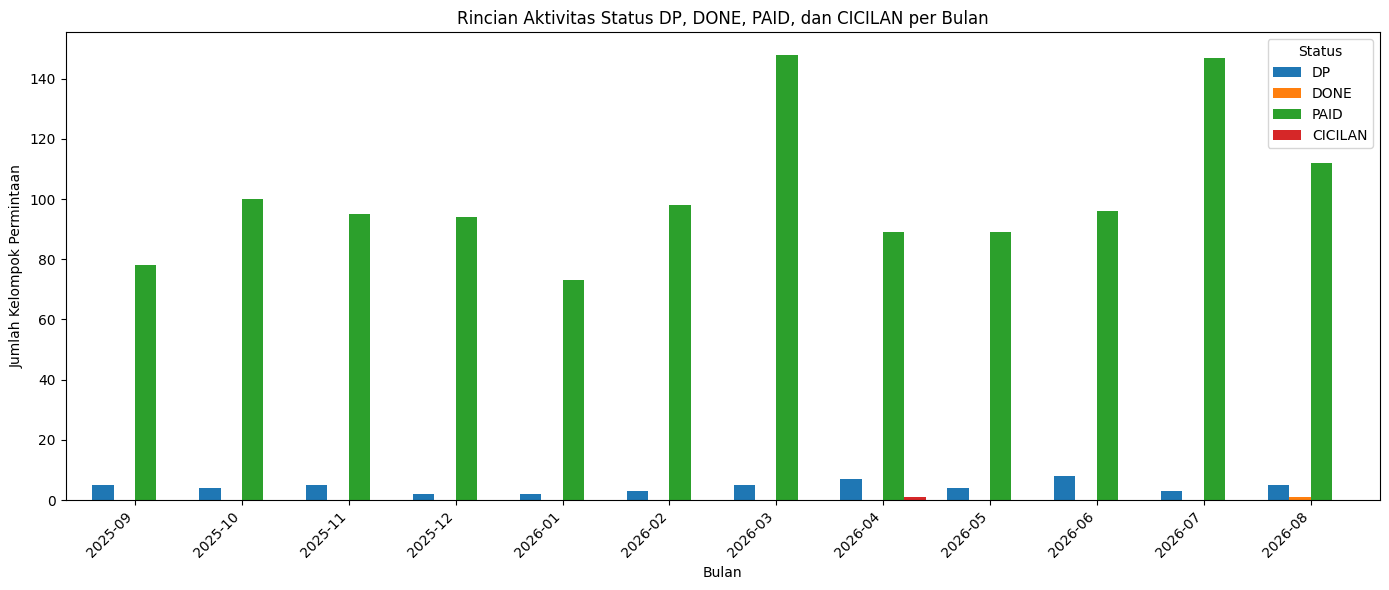

Grafik ini merupakan analisis pendukung status, bukan grafik total permintaan unik.


In [81]:
# TAHAP 64 - TREN BULANAN STATUS DP, DONE, DAN PAID, dan CICILAN

data_status_bulanan = data_status[
    data_status["Status_Bersih"].isin(status_utama)
].copy()

data_status_bulanan["Tanggal_Diperbaiki"] = pd.to_datetime(
    data_status_bulanan["Tanggal_Diperbaiki"], errors="coerce"
)
data_status_bulanan = data_status_bulanan.dropna(
    subset=["Tanggal_Diperbaiki"]
)
data_status_bulanan["Bulan"] = (
    data_status_bulanan["Tanggal_Diperbaiki"].dt.to_period("M").astype(str)
)

tren_status_bulanan = (
    data_status_bulanan
    .groupby(["Bulan", "Status_Bersih"])["ID_Kelompok_Pesanan"]
    .nunique()
    .unstack(fill_value=0)
)

# Memastikan kolom DP, DONE, dan PAID selalu tersedia
tren_status_bulanan = tren_status_bulanan.reindex(
    columns=status_utama, fill_value=0
)
tren_status_bulanan = tren_status_bulanan.reset_index()

print("TREN BULANAN KELOMPOK PERMINTAAN MENURUT STATUS")
display(tren_status_bulanan)

# Grafik pendukung status per bulan
tren_plot = tren_status_bulanan.set_index("Bulan")[status_utama]
ax = tren_plot.plot(
    kind="bar", figsize=(14, 6), width=0.8
)
ax.set_title(
    "Rincian Aktivitas Status DP, DONE, PAID, dan CICILAN per Bulan"
)
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah Kelompok Permintaan")
ax.legend(title="Status")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
ax.figure.savefig(
    GRAPH_DIR / "06_tren_status_bulanan.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Grafik ini merupakan analisis pendukung status, bukan grafik total permintaan unik.")

In [82]:
# TAHAP 65 - MENYIMPAN HASIL ANALISIS STATUS

from pathlib import Path

folder_hasil = Path(BASE_DIR) / "hasil_akhir"
folder_hasil.mkdir(parents=True, exist_ok=True)

hasil_status = {
    "16_Rincian_Status_Transaksi": rekap_status_detail,
    "17_Kombinasi_Status_Permintaan": rekap_kombinasi_status,
    "18_Tren_Status_Bulanan": tren_status_bulanan,
    "19_Ringkasan_Link_DP": rekap_link_dp_status,
    "20_Detail_Kelompok_Status": rincian_status_kelompok
}

# Simpan masing-masing tabel sebagai CSV
for nama_file, tabel in hasil_status.items():
    tabel.to_csv(
        folder_hasil / f"{nama_file}.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("File CSV analisis status berhasil disimpan:")
for nama_file in hasil_status:
    print("-", f"{nama_file}.csv")

# Tambahkan/segarkan sheet pada workbook arsip lengkap
file_arsip = folder_hasil / "Arsip_Lengkap_Penelitian.xlsx"
if file_arsip.exists():
    try:
        with pd.ExcelWriter(
            file_arsip, engine="openpyxl", mode="a",
            if_sheet_exists="replace"
        ) as writer:
            for nama_file, tabel in hasil_status.items():
                tabel_excel = tabel.copy()
                for kolom in tabel_excel.columns:
                    if isinstance(tabel_excel[kolom].dtype, pd.PeriodDtype):
                        tabel_excel[kolom] = tabel_excel[kolom].astype(str)
                tabel_excel.to_excel(
                    writer, sheet_name=nama_file[:31], index=False
                )
        print("Workbook Arsip_Lengkap_Penelitian.xlsx berhasil diperbarui.")
    except PermissionError:
        print("CSV berhasil disimpan, tetapi workbook sedang terbuka. Tutup file Excel lalu jalankan ulang Tahap 65.")
else:
    print("Workbook arsip belum ditemukan. CSV berhasil disimpan; jalankan Tahap 61 terlebih dahulu untuk membuat workbook arsip.")

print("Selesai. Hasil utama Top 10, tren permintaan, dan Logistic Regression tetap menggunakan proses sebelumnya.")

File CSV analisis status berhasil disimpan:
- 16_Rincian_Status_Transaksi.csv
- 17_Kombinasi_Status_Permintaan.csv
- 18_Tren_Status_Bulanan.csv
- 19_Ringkasan_Link_DP.csv
- 20_Detail_Kelompok_Status.csv
Workbook Arsip_Lengkap_Penelitian.xlsx berhasil diperbarui.
Selesai. Hasil utama Top 10, tren permintaan, dan Logistic Regression tetap menggunakan proses sebelumnya.


In [83]:
# TAHAP 66 - AUDIT STATUS DI LUAR DP, DONE, PAID, DAN CICILAN

status_utama = ["DP", "DONE", "PAID", "CICILAN"]

# Mengambil transaksi dengan status selain status utama
data_status_lain = data_status[
    ~data_status["Status_Bersih"].isin(status_utama)
].copy()

# Ringkasan status lainnya
rekap_status_lain = (
    data_status_lain.groupby("Status_Bersih")
    .agg(
        Jumlah_Baris=("ID_Transaksi", "size"),
        Jumlah_ID_Transaksi=("ID_Transaksi", "nunique"),
        Jumlah_Kelompok=("ID_Kelompok_Pesanan", "nunique"),
        Jumlah_Produk=("Nama_Produk_Normalisasi", "nunique")
    )
    .reset_index()
    .sort_values("Jumlah_Kelompok", ascending=False)
)

print("RINGKASAN STATUS LAINNYA")
display(rekap_status_lain)

# Menampilkan rincian transaksi dan produk
detail_status_lain = (
    data_status_lain[
        [
            "ID_Transaksi",
            "Status_Bersih",
            "Nama_Produk_Normalisasi",
            "ID_Kelompok_Pesanan"
        ]
    ]
    .sort_values(["Status_Bersih", "Nama_Produk_Normalisasi"])
    .reset_index(drop=True)
)

print("DETAIL TRANSAKSI STATUS LAINNYA")
display(detail_status_lain)

print("Total kelompok status lainnya:",
      detail_status_lain["ID_Kelompok_Pesanan"].nunique())

RINGKASAN STATUS LAINNYA


,Status_Bersih,Jumlah_Baris,Jumlah_ID_Transaksi,Jumlah_Kelompok,Jumlah_Produk
2,NO ACTION / CANCEL,6,5,6,5
4,REFUND,3,3,3,3
3,PROGRESS,3,2,3,3
1,KOSONG,2,2,2,2
0,COMPLAIN,1,1,1,1


DETAIL TRANSAKSI STATUS LAINNYA


,ID_Transaksi,Status_Bersih,Nama_Produk_Normalisasi,ID_Kelompok_Pesanan
0,Sumber_01.xlsx|MARET|33,COMPLAIN,LCD STANDARD,Sumber_01.xlsx|MARET|33||LCD STANDARD
1,Sumber_02.xlsx|Agustus|155,KOSONG,BATERAI OEM,Sumber_02.xlsx|Agustus|155||BATERAI OEM
2,Sumber_02.xlsx|Juli|49,KOSONG,LCD ORI APPLE,Sumber_02.xlsx|Juli|49||LCD ORI APPLE
3,Sumber_02.xlsx|Mei|71,NO ACTION / CANCEL,BATERAI OEM,Sumber_02.xlsx|Mei|71||BATERAI OEM
4,Sumber_01.xlsx|DESEMBER|76,NO ACTION / CANCEL,BATERAI ORI,Sumber_01.xlsx|DESEMBER|76||BATERAI ORI
5,Sumber_02.xlsx|Mei|71,NO ACTION / CANCEL,FLEKSIBEL CHARGE,Sumber_02.xlsx|Mei|71||FLEKSIBEL CHARGE
6,Sumber_01.xlsx|MARET|158,NO ACTION / CANCEL,IC DISPLAY,Sumber_01.xlsx|MARET|158||IC DISPLAY
7,Sumber_02.xlsx|Agustus|144,NO ACTION / CANCEL,LCD ORI APPLE,Sumber_02.xlsx|Agustus|144||LCD ORI APPLE
8,Sumber_02.xlsx|Agustus|158,NO ACTION / CANCEL,LCD ORI APPLE,Sumber_02.xlsx|Agustus|158||LCD ORI APPLE
9,Sumber_01.xlsx|JANUARI|71,PROGRESS,BATERAI OEM,Sumber_01.xlsx|JANUARI|71||BATERAI OEM


Total kelompok status lainnya: 15


In [84]:
# TAHAP 68 - PEMERIKSAAN TRANSAKSI CICILAN

id_cicilan = "Sumber_02.xlsx|April|18"

kolom_periksa = [
    "ID_Transaksi",
    "Tanggal_Diperbaiki",
    "Name",
    "Device",
    "Description",
    "Status_Bersih",
    "Payment Date",
    "Amount"
]

kolom_tersedia = [
    kolom for kolom in kolom_periksa
    if kolom in df_preprocess.columns
]

detail_cicilan = df_preprocess[
    df_preprocess["ID_Transaksi"] == id_cicilan
][kolom_tersedia]

display(detail_cicilan)

,ID_Transaksi,Tanggal_Diperbaiki,Name,Device,Description,Status_Bersih,Payment Date,Amount
1178,Sumber_02.xlsx|April|18,2026-04-05,P0471,iPhone XS,Lcd Standard + Free Ag Ceramic Privacy,CICILAN,2026-04-05 00:00:00,450000.0


In [85]:
# TAHAP 69 - AUDIT DATA DI LUAR PERIODE PENELITIAN

audit_periode = df_permintaan_utama.copy()

audit_periode["Tanggal_Permintaan"] = pd.to_datetime(
    audit_periode["Tanggal_Permintaan"],
    errors="coerce"
)

mask_periode = (
    (audit_periode["Tanggal_Permintaan"] >= "2025-09-01") &
    (audit_periode["Tanggal_Permintaan"] <= "2026-08-31")
)

data_di_luar_periode = audit_periode[~mask_periode].copy()

print("Total data hasil filter:", len(audit_periode))
print("Data masuk periode:", mask_periode.sum())
print("Data di luar periode/tanggal kosong:", len(data_di_luar_periode))

display(
    data_di_luar_periode[
        [
            "ID_Kelompok_Pesanan",
            "Nama_Produk_Normalisasi",
            "Tanggal_Permintaan",
            "Daftar_Status"
        ]
    ]
)

Total data hasil filter: 1242
Data masuk periode: 1242
Data di luar periode/tanggal kosong: 0


,ID_Kelompok_Pesanan,Nama_Produk_Normalisasi,Tanggal_Permintaan,Daftar_Status


In [86]:
# AUDIT NAMA SPAREPART FLEKSIBEL

mask_fleksibel = (
    df_transaksi_sparepart["Nama_Produk_Normalisasi"]
    .astype(str)
    .str.contains("FLEKS", case=False, na=False)
)

kolom_audit = [
    "ID_Transaksi",
    "Tanggal_Diperbaiki",
    "Name",
    "Device",
    "Description",
    "Komponen_Kandidat",
    "Nama_Produk_Normalisasi",
    "Status_Bersih"
]

display(
    df_transaksi_sparepart.loc[
        mask_fleksibel, kolom_audit
    ]
    .drop_duplicates()
    .sort_values(["Nama_Produk_Normalisasi", "Tanggal_Diperbaiki"])
)

,ID_Transaksi,Tanggal_Diperbaiki,Name,Device,Description,Komponen_Kandidat,Nama_Produk_Normalisasi,Status_Bersih
3,Sumber_01.xlsx|SEPTEMBER|5,2025-09-02,P0022,iPhone XS Max,Fleksibel Charge,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
47,Sumber_01.xlsx|SEPTEMBER|75,2025-09-17,P0195,iPhone 8,Fleksibel Charge,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
128,Sumber_01.xlsx|OKTOBER|61,2025-10-12,P0271,iPhone 12 Pro,Stuck Logo Kenak Air > Speaker Atas + Fleksibe...,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
185,Sumber_01.xlsx|OKTOBER|140,2025-10-30,P0321,iPhone 12 Pro Max,Baterai Oem + Fleksibel Charge,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
236,Sumber_01.xlsx|NOVEMBER|73,2025-11-17,P0163,iPhone XR,Cek kena air > Baterai Oem + Fleksibel Charge,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
...,...,...,...,...,...,...,...,...
194,Sumber_01.xlsx|NOVEMBER|10,2025-11-03,P0234,iPhone XS,Fleksible On/Off,FLEKSIBLE ON/OFF,FLEKSIBLE ON/OFF,PAID
948,Sumber_02.xlsx|Juni|45,2026-06-09,P0068,iPhone 11 Pro,Housing Grey + Fleksible On/Off + Ag Black Biasa,FLEKSIBLE ON/OFF,FLEKSIBLE ON/OFF,PAID
1014,Sumber_02.xlsx|Juni|134,2026-06-30,P0918,iPhone XR,Baterai Oem + Fleksible Spek Atas,FLEKSIBLE SPEK ATAS,FLEKSIBLE SPEK ATAS,PAID
963,Sumber_02.xlsx|Juni|65,2026-06-14,P0891,iPhone 15,DP Fleksible Tag-On Face ID,DP FLEKSIBLE TAG-ON FACE ID,FLEKSIBLE TAG-ON FACE ID,DP


In [87]:
# TAHAP 70 - PEMERIKSAAN DUA NAMA FLEKSIBEL CHARGE

nama_target = [
    "FLEKSIBLE CHARGER",
    "FLEKSIBEL CHARGE"
]

mask = (
    df_transaksi_sparepart["Nama_Produk_Normalisasi"]
    .astype(str)
    .str.upper()
    .isin(nama_target)
)

kolom = [
    "ID_Transaksi",
    "Tanggal_Diperbaiki",
    "Device",
    "Description",
    "Komponen_Kandidat",
    "Nama_Produk_Normalisasi",
    "Status_Bersih"
]

display(
    df_transaksi_sparepart.loc[mask, kolom]
    .sort_values("Nama_Produk_Normalisasi")
    .reset_index(drop=True)
)

print("\nJUMLAH MASING-MASING NAMA:")
display(
    df_transaksi_sparepart.loc[mask]
    ["Nama_Produk_Normalisasi"]
    .value_counts()
    .rename_axis("Nama_Produk")
    .reset_index(name="Jumlah")
)

,ID_Transaksi,Tanggal_Diperbaiki,Device,Description,Komponen_Kandidat,Nama_Produk_Normalisasi,Status_Bersih
0,Sumber_01.xlsx|SEPTEMBER|5,2025-09-02,iPhone XS Max,Fleksibel Charge,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
1,Sumber_01.xlsx|MARET|2,2026-03-01,iPhone 6s+,Baterai Oem + Lcd Standard + Fleksibel Charge ...,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
2,Sumber_01.xlsx|MARET|134,2026-03-24,iPhone 8+,Baterai Oem + Fleksible Charger,FLEKSIBLE CHARGER,FLEKSIBEL CHARGE,PAID
3,Sumber_01.xlsx|MARET|142,2026-03-25,iPhone 12 Pro Max,Fleksibel Charge,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
4,Sumber_01.xlsx|MARET|163,2026-03-29,iPhone 11,Fleksibel Charge,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
...,...,...,...,...,...,...,...
31,Sumber_01.xlsx|JANUARI|61,2026-01-16,iPhone 11,Fleksible Charger,FLEKSIBLE CHARGER,FLEKSIBEL CHARGE,PAID
32,Sumber_01.xlsx|JANUARI|63,2026-01-17,iPhone XS Max,Baterai Oem + Fleksible Charger,FLEKSIBLE CHARGER,FLEKSIBEL CHARGE,PAID
33,Sumber_01.xlsx|FEBRUARI|24,2026-02-04,iPhone XS,Fleksibel Charge,FLEKSIBEL CHARGE,FLEKSIBEL CHARGE,PAID
34,Sumber_02.xlsx|Juni|63,2026-06-14,iPhone 12 Pro,Fleksible Charger,FLEKSIBLE CHARGER,FLEKSIBEL CHARGE,PAID



JUMLAH MASING-MASING NAMA:


,Nama_Produk,Jumlah
0,FLEKSIBEL CHARGE,36
